In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

def set_rho(ff, rho_tot):
    '''
    Proton Density.
    rho_tot = total proton density
    '''
    rho_fat = ff*rho_tot
    rho_water = rho_tot - rho_fat
    return(rho_fat, rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    
    # TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    return(echo_times)


def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    '''
    
    # rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    rho = np.array([rho_fat*0.047, rho_fat*0.039, rho_fat*0.006, 
                    rho_fat*0.12, rho_fat*0.7, rho_fat*0.088, rho_water])
    
    # standard, individual T2* values
    t2star = np.array([0.030, 0.040, 0.051, 0.052, 0.062, 0.083, 0.023] )
    
    # frequency in parts per million for each moiety
    freq_ppm = np.array([5.3, 4.2, 2.75, 2.1, 1.3, 0.9, 4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      # magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) # Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    # calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    # obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return(Sabs)


def continuous_timeseries(endpoint=0.01):
    return(np.linspace(0, endpoint, 1000, endpoint=True))

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return(ff)

# Teste 1:
## Funcionamento das alterações


rho_fat = 0.010
rho_water = 9.990
rho_tot = 10.000
OK


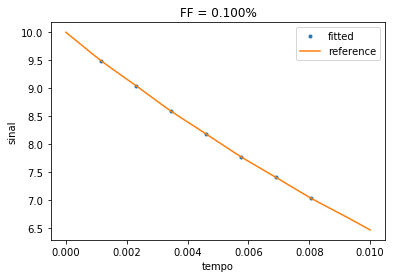

rho_fat = 0.112
rho_water = 9.888
rho_tot = 10.000
OK


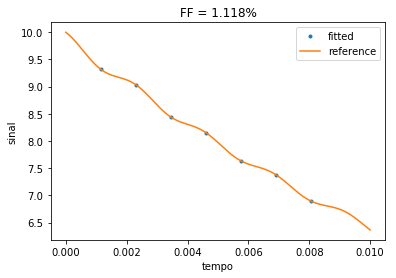

rho_fat = 0.214
rho_water = 9.786
rho_tot = 10.000
OK


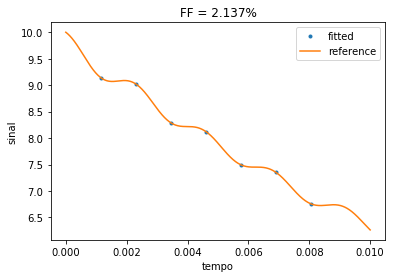

rho_fat = 0.316
rho_water = 9.684
rho_tot = 10.000
OK


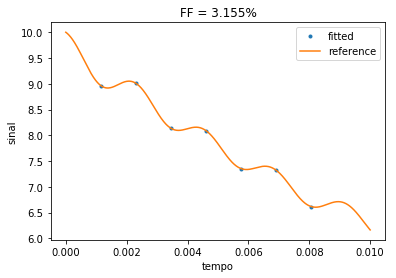

rho_fat = 0.417
rho_water = 9.583
rho_tot = 10.000
OK


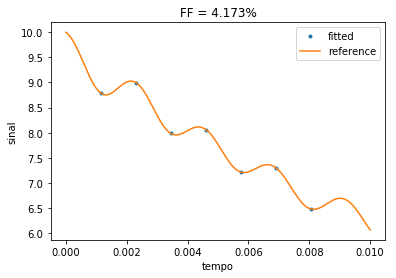

rho_fat = 0.519
rho_water = 9.481
rho_tot = 10.000
OK


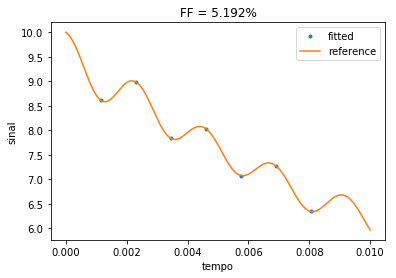

rho_fat = 0.621
rho_water = 9.379
rho_tot = 10.000
OK


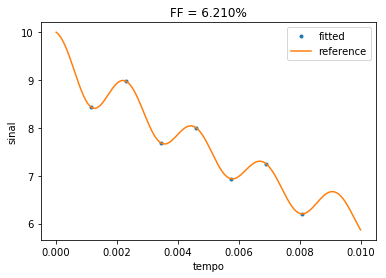

rho_fat = 0.723
rho_water = 9.277
rho_tot = 10.000
OK


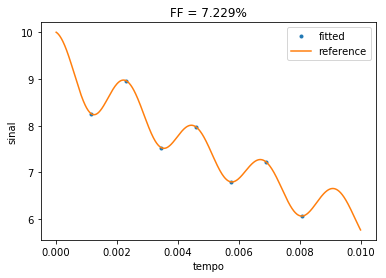

rho_fat = 0.825
rho_water = 9.175
rho_tot = 10.000
OK


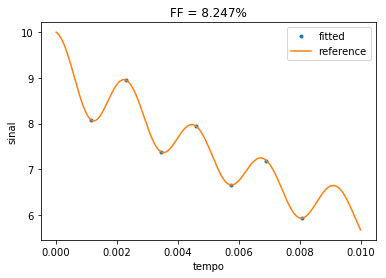

rho_fat = 0.927
rho_water = 9.073
rho_tot = 10.000
OK


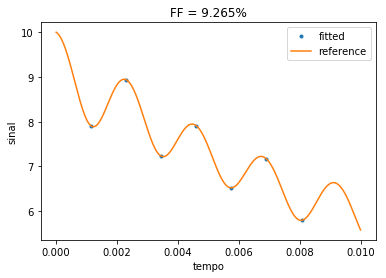

rho_fat = 1.028
rho_water = 8.972
rho_tot = 10.000
OK


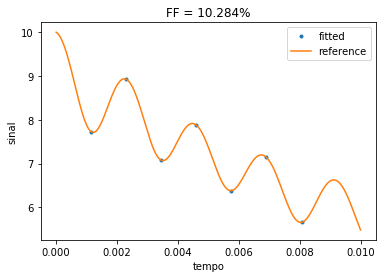

rho_fat = 1.130
rho_water = 8.870
rho_tot = 10.000
OK


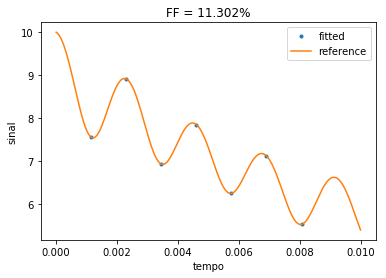

rho_fat = 1.232
rho_water = 8.768
rho_tot = 10.000
OK


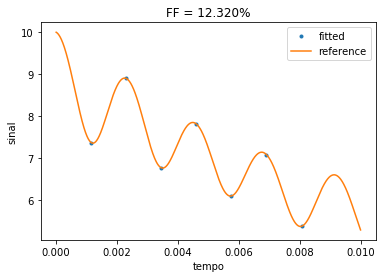

rho_fat = 1.334
rho_water = 8.666
rho_tot = 10.000
OK


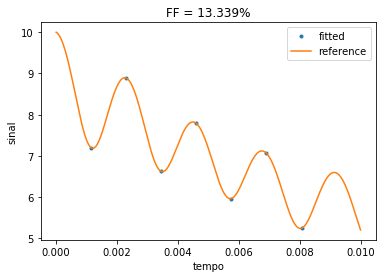

rho_fat = 1.436
rho_water = 8.564
rho_tot = 10.000
OK


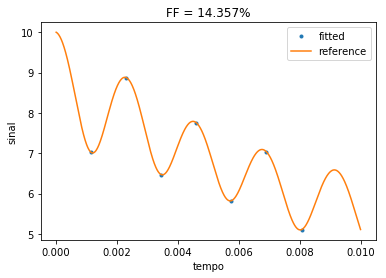

rho_fat = 1.538
rho_water = 8.462
rho_tot = 10.000
OK


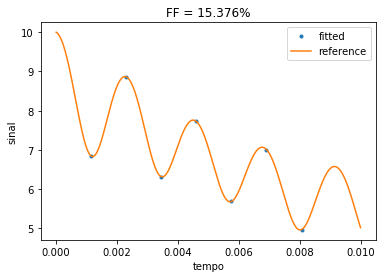

rho_fat = 1.639
rho_water = 8.361
rho_tot = 10.000
OK


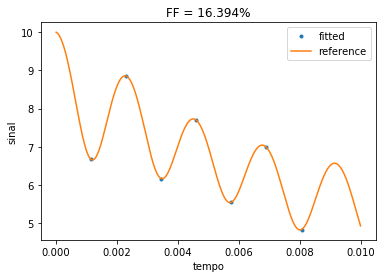

rho_fat = 1.741
rho_water = 8.259
rho_tot = 10.000
OK


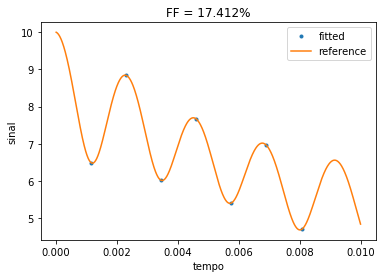

rho_fat = 1.843
rho_water = 8.157
rho_tot = 10.000
OK


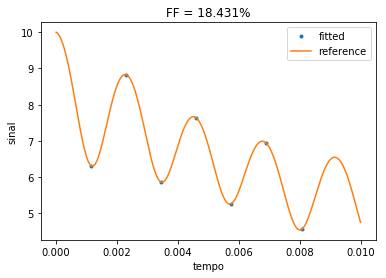

rho_fat = 1.945
rho_water = 8.055
rho_tot = 10.000
OK


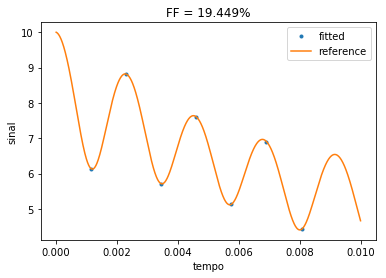

rho_fat = 2.047
rho_water = 7.953
rho_tot = 10.000
OK


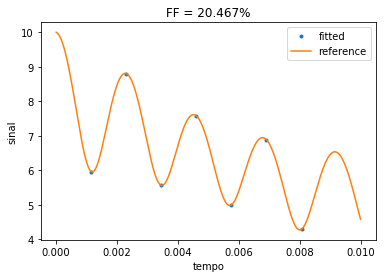

rho_fat = 2.149
rho_water = 7.851
rho_tot = 10.000
OK


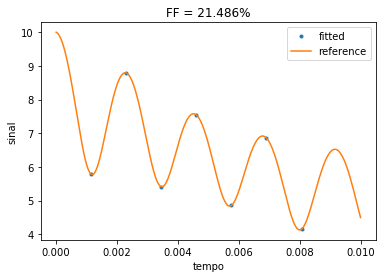

rho_fat = 2.250
rho_water = 7.750
rho_tot = 10.000
OK


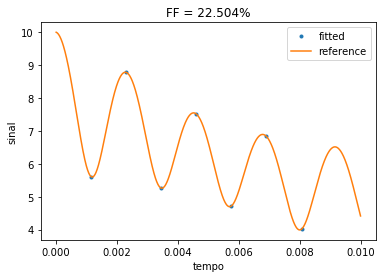

rho_fat = 2.352
rho_water = 7.648
rho_tot = 10.000
OK


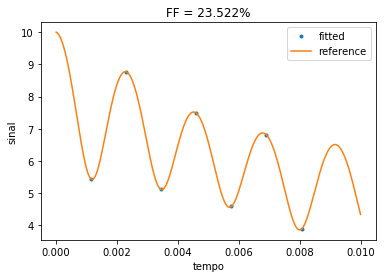

rho_fat = 2.454
rho_water = 7.546
rho_tot = 10.000
OK


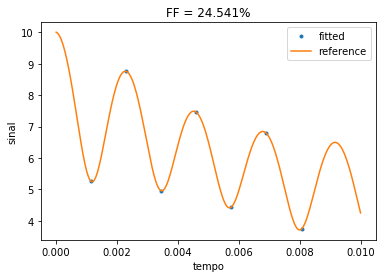

rho_fat = 2.556
rho_water = 7.444
rho_tot = 10.000
OK


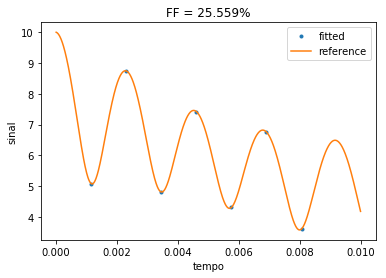

rho_fat = 2.658
rho_water = 7.342
rho_tot = 10.000
OK


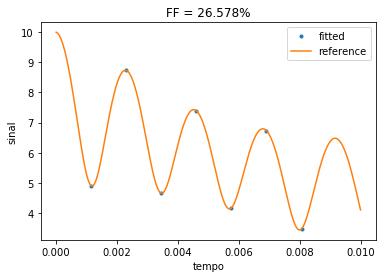

rho_fat = 2.760
rho_water = 7.240
rho_tot = 10.000
OK


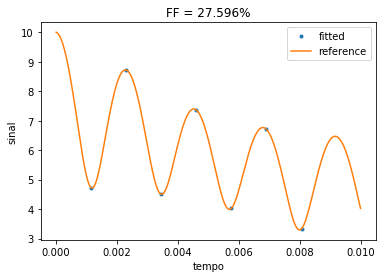

rho_fat = 2.861
rho_water = 7.139
rho_tot = 10.000
OK


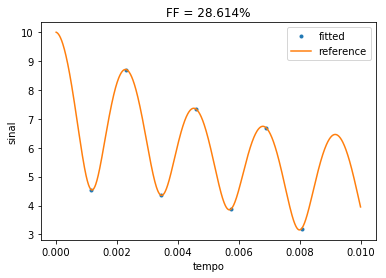

rho_fat = 2.963
rho_water = 7.037
rho_tot = 10.000
OK


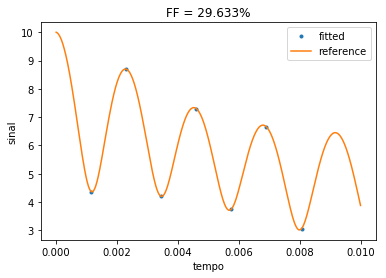

rho_fat = 3.065
rho_water = 6.935
rho_tot = 10.000
OK


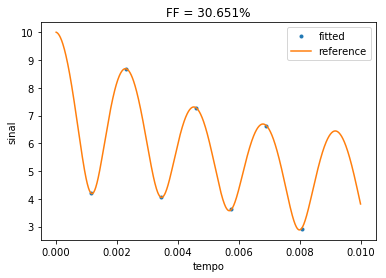

rho_fat = 3.167
rho_water = 6.833
rho_tot = 10.000
OK


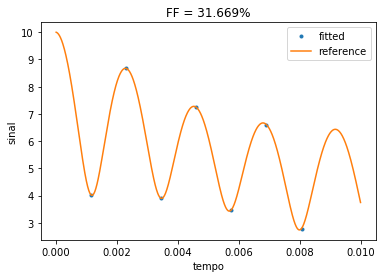

rho_fat = 3.269
rho_water = 6.731
rho_tot = 10.000
OK


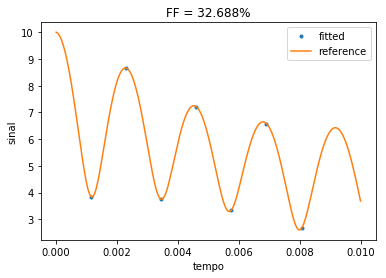

rho_fat = 3.371
rho_water = 6.629
rho_tot = 10.000
OK


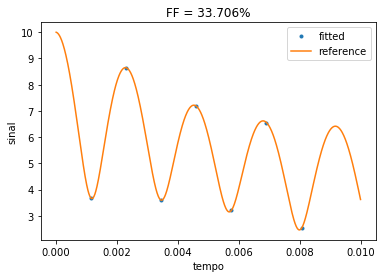

rho_fat = 3.472
rho_water = 6.528
rho_tot = 10.000
OK


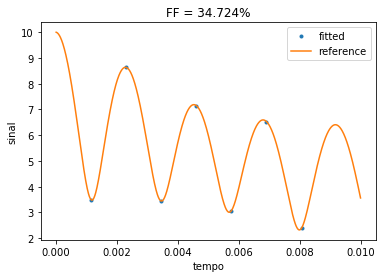

rho_fat = 3.574
rho_water = 6.426
rho_tot = 10.000
OK


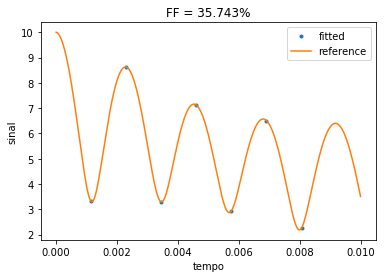

rho_fat = 3.676
rho_water = 6.324
rho_tot = 10.000
OK


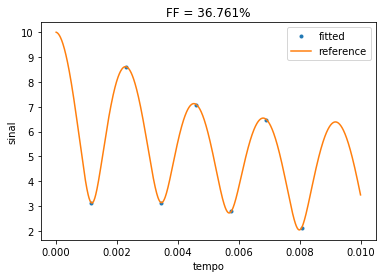

rho_fat = 3.778
rho_water = 6.222
rho_tot = 10.000
OK


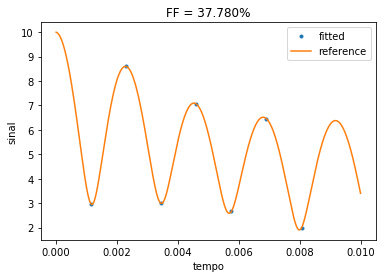

rho_fat = 3.880
rho_water = 6.120
rho_tot = 10.000
OK


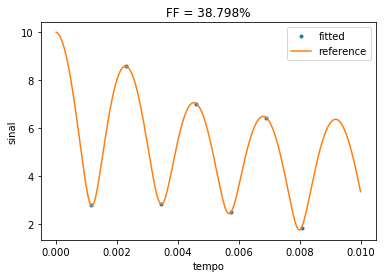

rho_fat = 3.982
rho_water = 6.018
rho_tot = 10.000
OK


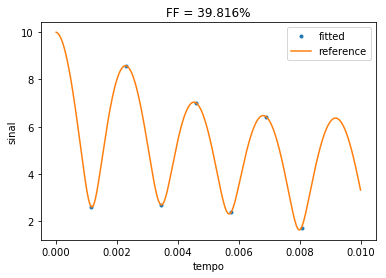

rho_fat = 4.083
rho_water = 5.917
rho_tot = 10.000
OK


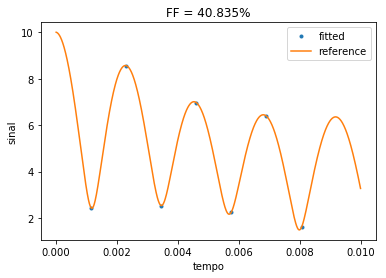

rho_fat = 4.185
rho_water = 5.815
rho_tot = 10.000
OK


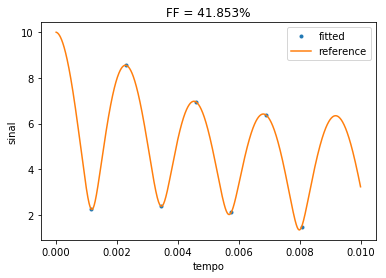

rho_fat = 4.287
rho_water = 5.713
rho_tot = 10.000
OK


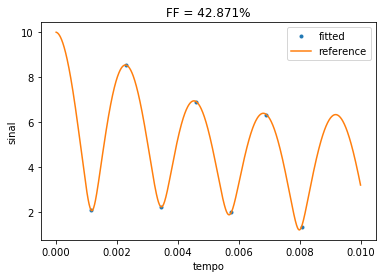

rho_fat = 4.389
rho_water = 5.611
rho_tot = 10.000
OK


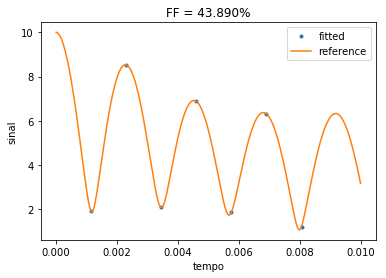

rho_fat = 4.491
rho_water = 5.509
rho_tot = 10.000
OK


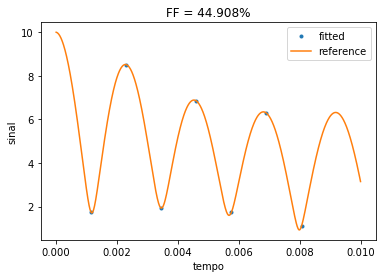

rho_fat = 4.593
rho_water = 5.407
rho_tot = 10.000
OK


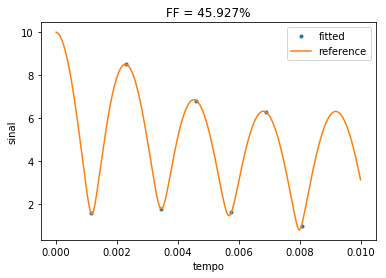

rho_fat = 4.694
rho_water = 5.306
rho_tot = 10.000
OK


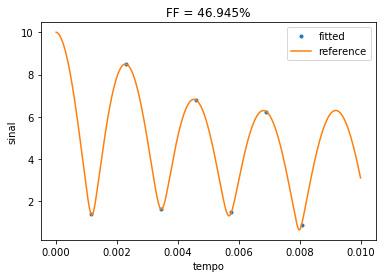

rho_fat = 4.796
rho_water = 5.204
rho_tot = 10.000
OK


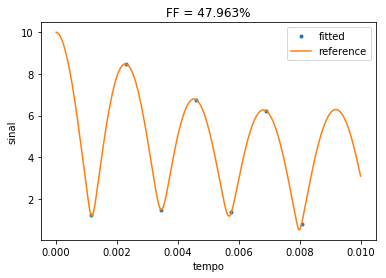

rho_fat = 4.898
rho_water = 5.102
rho_tot = 10.000
OK


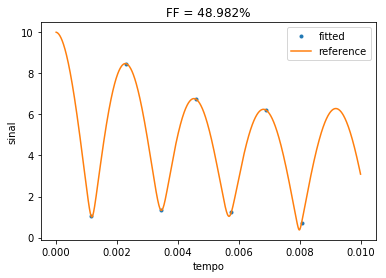

rho_fat = 5.000
rho_water = 5.000
rho_tot = 10.000
OK


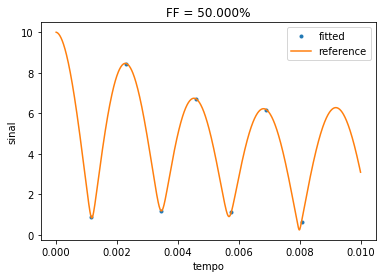

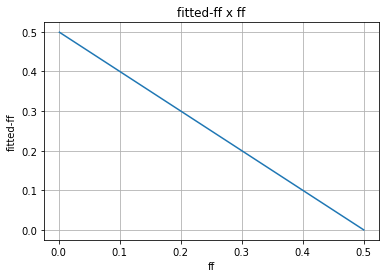

In [2]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 10                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata)
    fitted10.append(calc_fatfrac(fitted_par))
    
    ref10 = np.zeros(np.size(fitted10))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: print('Diferentes')
    
    plt.figure()
    plt.plot(xdata, ydata, '.', label='fitted')
    plt.plot(x, gen_GRE(x, *fitted_par), label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('tempo')
    plt.ylabel('sinal')
    plt.legend()
    plt.show()
    
plt.plot(ff, (fitted10-ff), lw=1.5)
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.title('fitted-ff x ff')
plt.grid(True)
plt.show()

rho_fat = 0.100
rho_water = 99.900
rho_tot = 100.000
OK


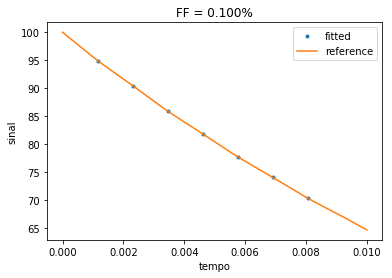

rho_fat = 1.118
rho_water = 98.882
rho_tot = 100.000
OK


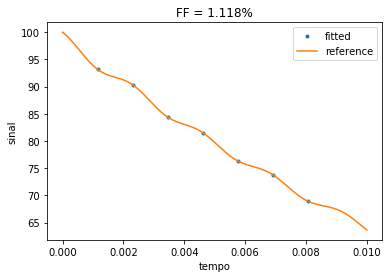

rho_fat = 2.137
rho_water = 97.863
rho_tot = 100.000
OK


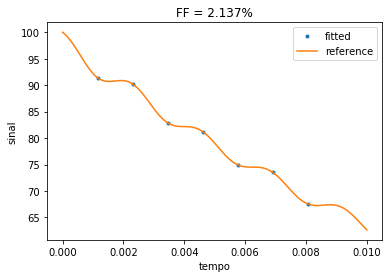

rho_fat = 3.155
rho_water = 96.845
rho_tot = 100.000
OK


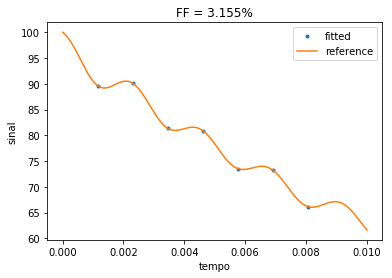

rho_fat = 4.173
rho_water = 95.827
rho_tot = 100.000
OK


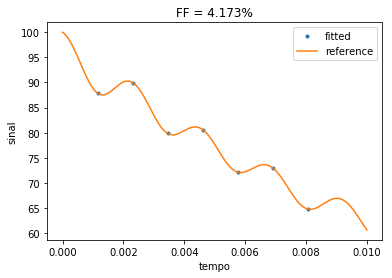

rho_fat = 5.192
rho_water = 94.808
rho_tot = 100.000
OK


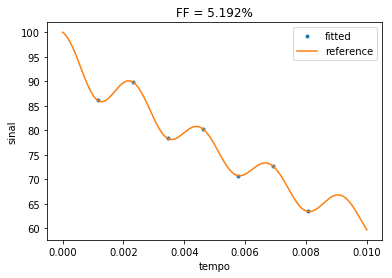

rho_fat = 6.210
rho_water = 93.790
rho_tot = 100.000
OK


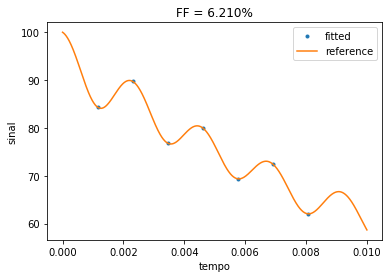

rho_fat = 7.229
rho_water = 92.771
rho_tot = 100.000
OK


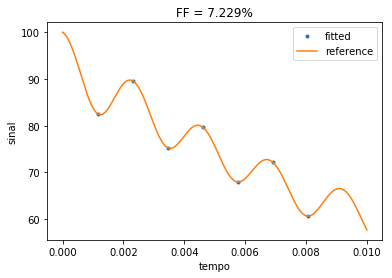

rho_fat = 8.247
rho_water = 91.753
rho_tot = 100.000
OK


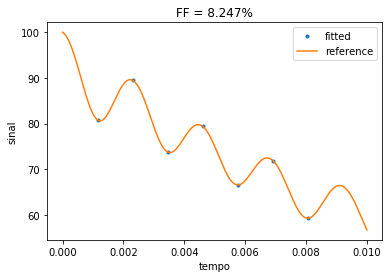

rho_fat = 9.265
rho_water = 90.735
rho_tot = 100.000
OK


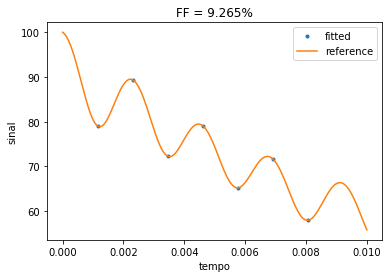

rho_fat = 10.284
rho_water = 89.716
rho_tot = 100.000
OK


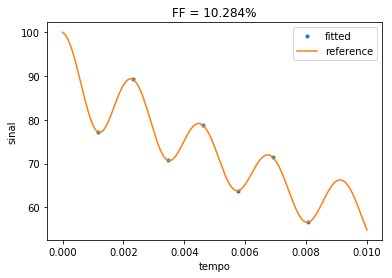

rho_fat = 11.302
rho_water = 88.698
rho_tot = 100.000
OK


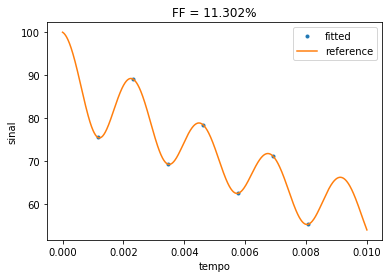

rho_fat = 12.320
rho_water = 87.680
rho_tot = 100.000
OK


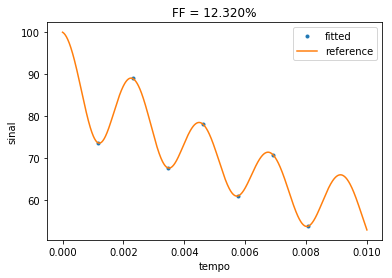

rho_fat = 13.339
rho_water = 86.661
rho_tot = 100.000
OK


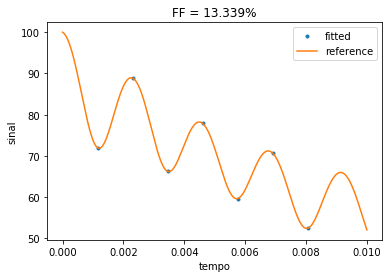

rho_fat = 14.357
rho_water = 85.643
rho_tot = 100.000
OK


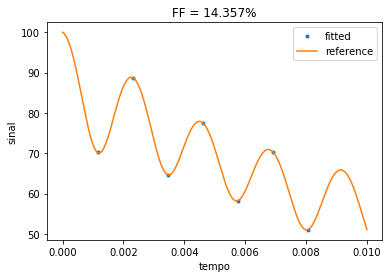

rho_fat = 15.376
rho_water = 84.624
rho_tot = 100.000
OK


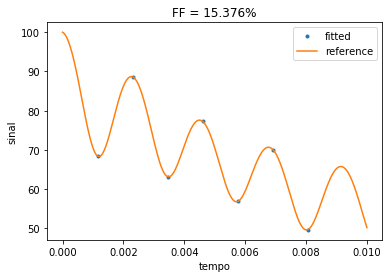

rho_fat = 16.394
rho_water = 83.606
rho_tot = 100.000
OK


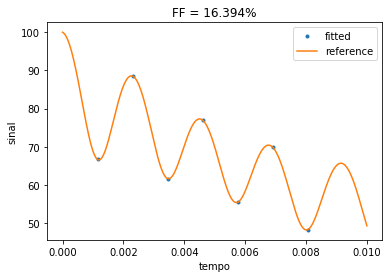

rho_fat = 17.412
rho_water = 82.588
rho_tot = 100.000
OK


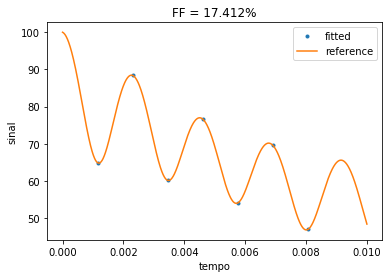

rho_fat = 18.431
rho_water = 81.569
rho_tot = 100.000
OK


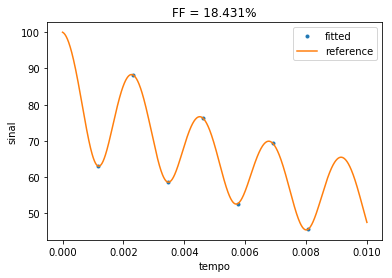

rho_fat = 19.449
rho_water = 80.551
rho_tot = 100.000
OK


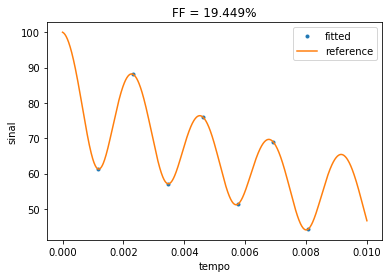

rho_fat = 20.467
rho_water = 79.533
rho_tot = 100.000
OK


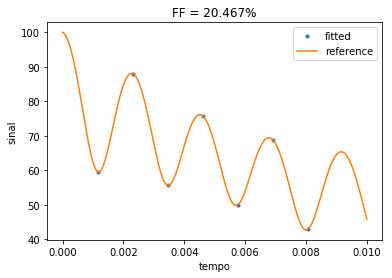

rho_fat = 21.486
rho_water = 78.514
rho_tot = 100.000
OK


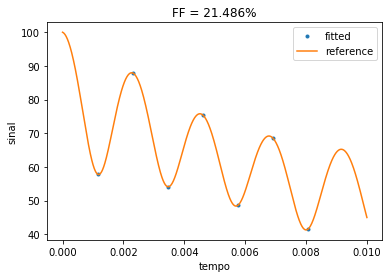

rho_fat = 22.504
rho_water = 77.496
rho_tot = 100.000
OK


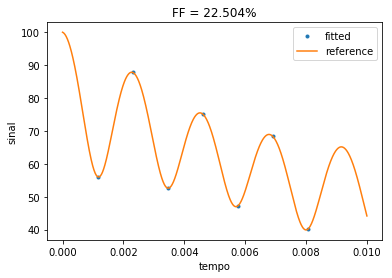

rho_fat = 23.522
rho_water = 76.478
rho_tot = 100.000
OK


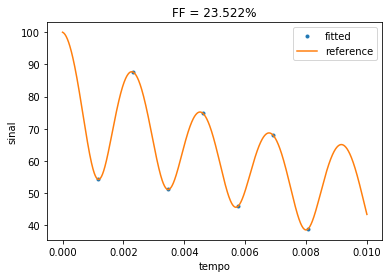

rho_fat = 24.541
rho_water = 75.459
rho_tot = 100.000
OK


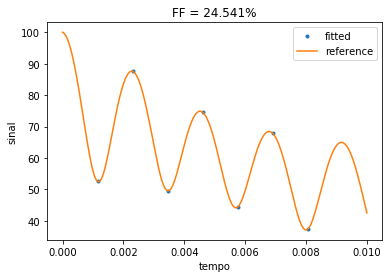

rho_fat = 25.559
rho_water = 74.441
rho_tot = 100.000
OK


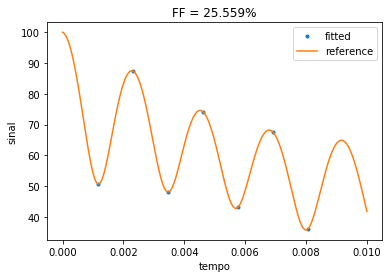

rho_fat = 26.578
rho_water = 73.422
rho_tot = 100.000
OK


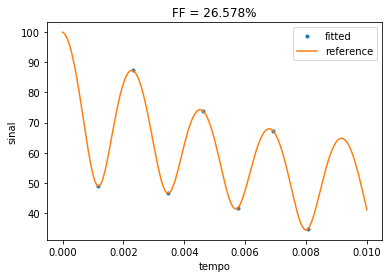

rho_fat = 27.596
rho_water = 72.404
rho_tot = 100.000
OK


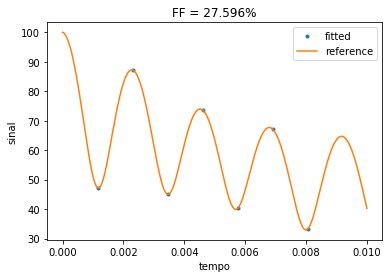

rho_fat = 28.614
rho_water = 71.386
rho_tot = 100.000
OK


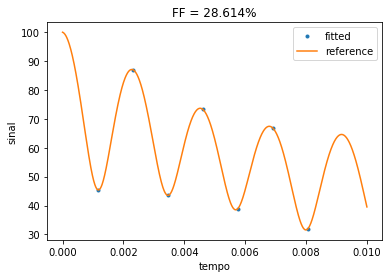

rho_fat = 29.633
rho_water = 70.367
rho_tot = 100.000
OK


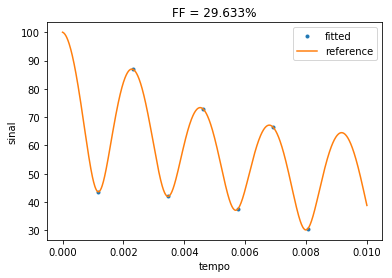

rho_fat = 30.651
rho_water = 69.349
rho_tot = 100.000
OK


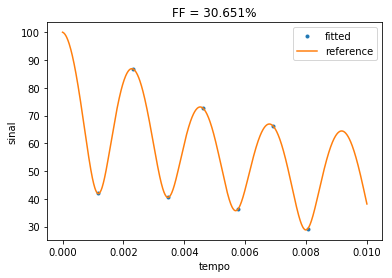

rho_fat = 31.669
rho_water = 68.331
rho_tot = 100.000
OK


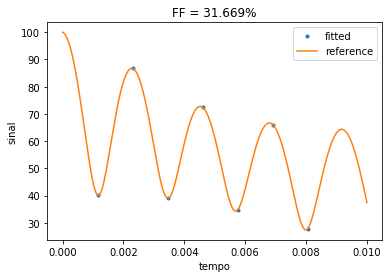

rho_fat = 32.688
rho_water = 67.312
rho_tot = 100.000
OK


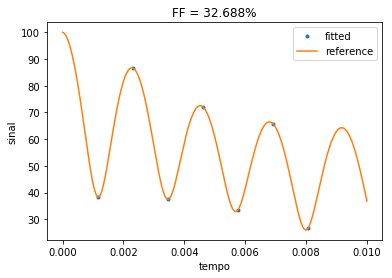

rho_fat = 33.706
rho_water = 66.294
rho_tot = 100.000
OK


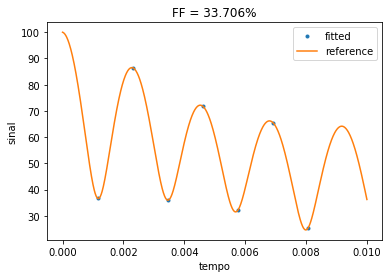

rho_fat = 34.724
rho_water = 65.276
rho_tot = 100.000
OK


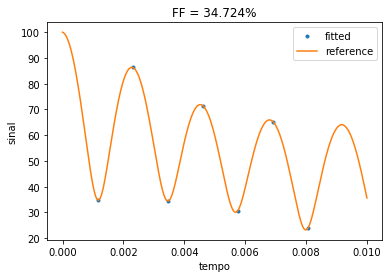

rho_fat = 35.743
rho_water = 64.257
rho_tot = 100.000
OK


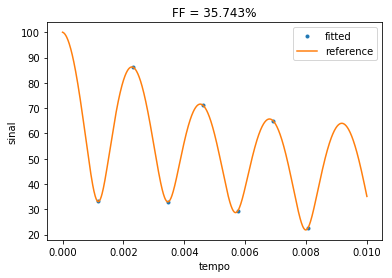

rho_fat = 36.761
rho_water = 63.239
rho_tot = 100.000
OK


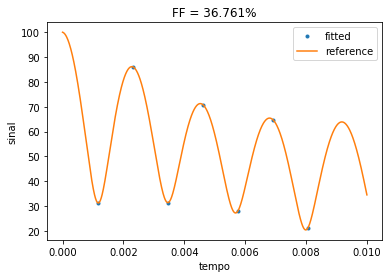

rho_fat = 37.780
rho_water = 62.220
rho_tot = 100.000
OK


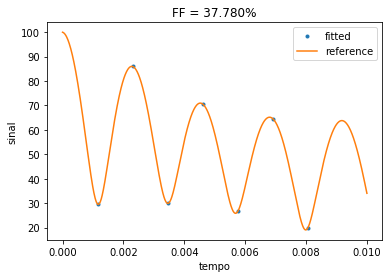

rho_fat = 38.798
rho_water = 61.202
rho_tot = 100.000
OK


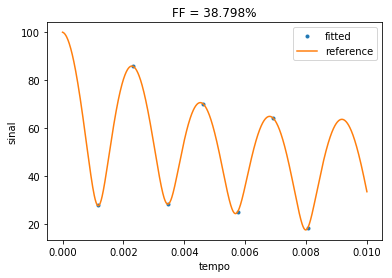

rho_fat = 39.816
rho_water = 60.184
rho_tot = 100.000
OK


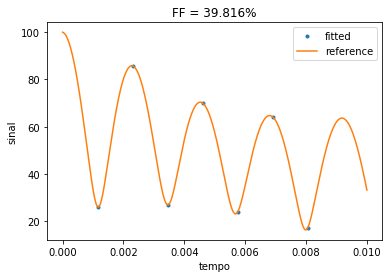

rho_fat = 40.835
rho_water = 59.165
rho_tot = 100.000
OK


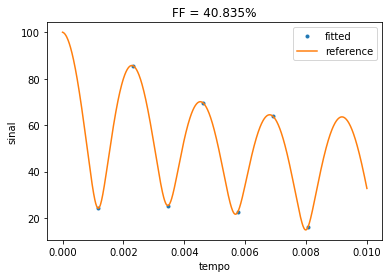

rho_fat = 41.853
rho_water = 58.147
rho_tot = 100.000
OK


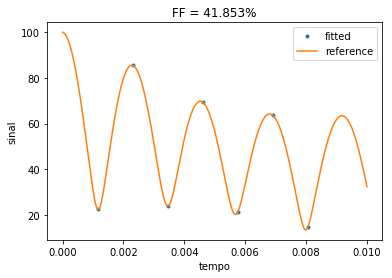

rho_fat = 42.871
rho_water = 57.129
rho_tot = 100.000
OK


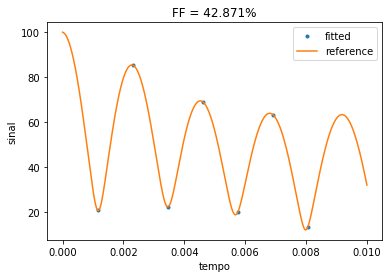

rho_fat = 43.890
rho_water = 56.110
rho_tot = 100.000
OK


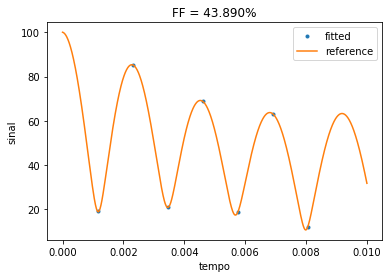

rho_fat = 44.908
rho_water = 55.092
rho_tot = 100.000
OK


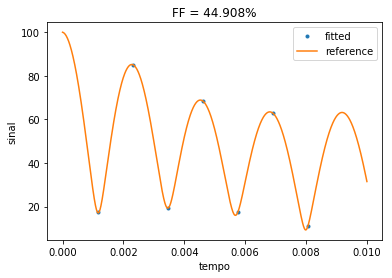

rho_fat = 45.927
rho_water = 54.073
rho_tot = 100.000
OK


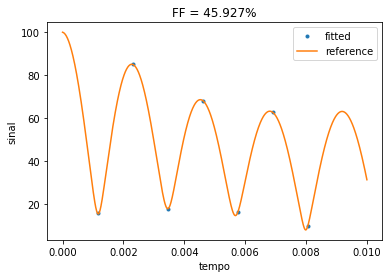

rho_fat = 46.945
rho_water = 53.055
rho_tot = 100.000
OK


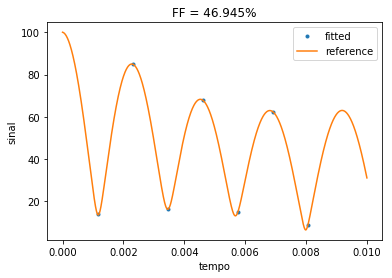

rho_fat = 47.963
rho_water = 52.037
rho_tot = 100.000
OK


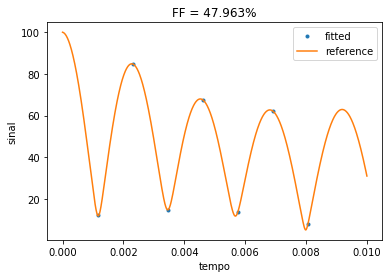

rho_fat = 48.982
rho_water = 51.018
rho_tot = 100.000
OK


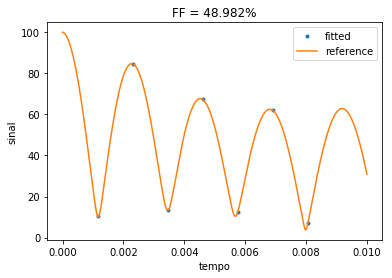

rho_fat = 50.000
rho_water = 50.000
rho_tot = 100.000
OK


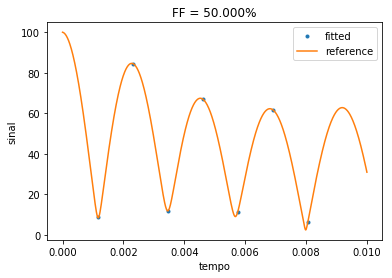

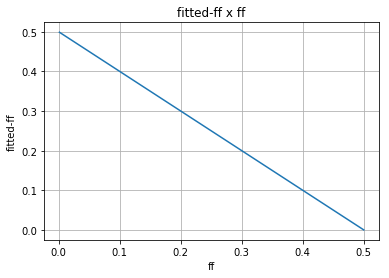

In [3]:
x = continuous_timeseries()           # plotar função contínua
ff = np.linspace(0.001, 0.5)          # fat fraction
rho_tot = 100                         # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted100 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata)
    fitted100.append(calc_fatfrac(fitted_par))
    
    ref100 = np.zeros(np.size(fitted100))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: print('Diferentes')
    
    plt.figure()
    plt.plot(xdata, ydata, '.', label='fitted')
    plt.plot(x, gen_GRE(x, *fitted_par), label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('tempo')
    plt.ylabel('sinal')
    plt.legend()
    plt.show()
    
plt.plot(ff, (fitted100-ff), lw=1.5)
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.title('fitted-ff x ff')
plt.grid(True)
plt.show()

rho_fat = 1.000
rho_water = 999.000
rho_tot = 1000.000
OK


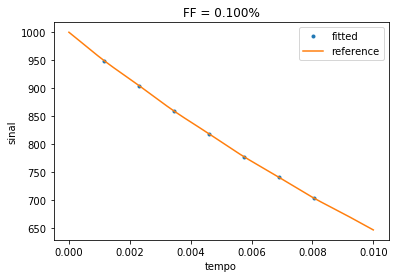

rho_fat = 11.184
rho_water = 988.816
rho_tot = 1000.000
OK


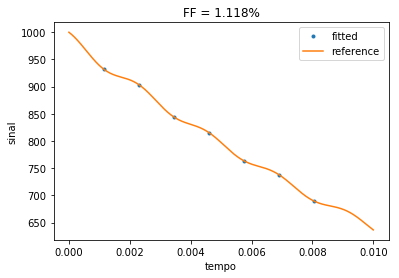

rho_fat = 21.367
rho_water = 978.633
rho_tot = 1000.000
OK


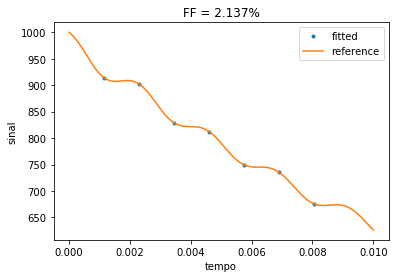

rho_fat = 31.551
rho_water = 968.449
rho_tot = 1000.000
OK


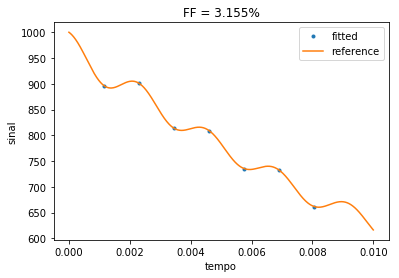

rho_fat = 41.735
rho_water = 958.265
rho_tot = 1000.000
OK


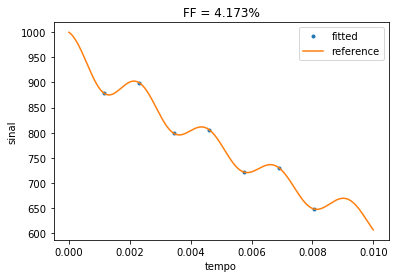

rho_fat = 51.918
rho_water = 948.082
rho_tot = 1000.000
OK


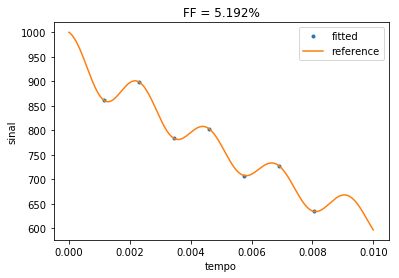

rho_fat = 62.102
rho_water = 937.898
rho_tot = 1000.000
OK


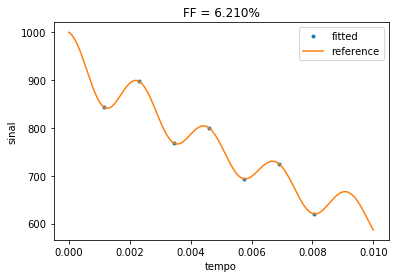

rho_fat = 72.286
rho_water = 927.714
rho_tot = 1000.000
OK


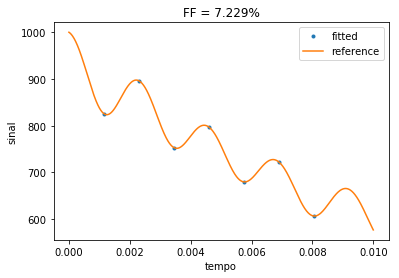

rho_fat = 82.469
rho_water = 917.531
rho_tot = 1000.000
OK


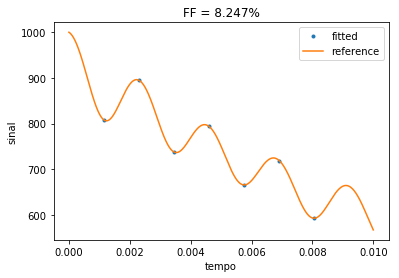

rho_fat = 92.653
rho_water = 907.347
rho_tot = 1000.000
OK


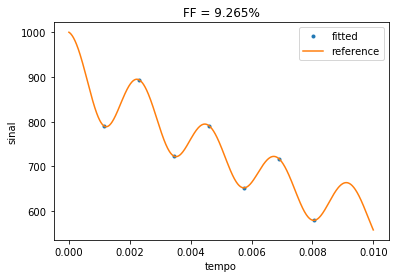

rho_fat = 102.837
rho_water = 897.163
rho_tot = 1000.000
OK


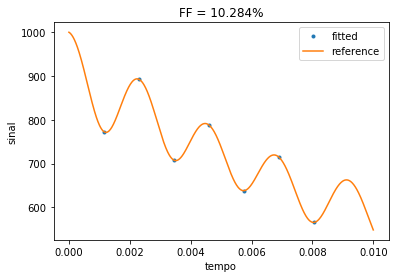

rho_fat = 113.020
rho_water = 886.980
rho_tot = 1000.000
OK


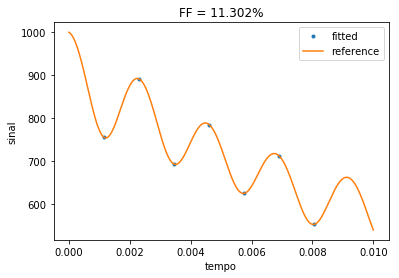

rho_fat = 123.204
rho_water = 876.796
rho_tot = 1000.000
OK


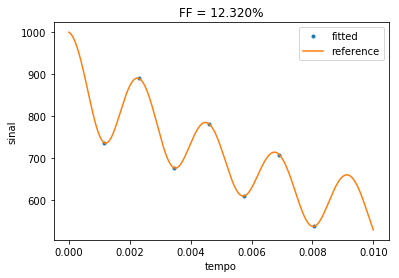

rho_fat = 133.388
rho_water = 866.612
rho_tot = 1000.000
OK


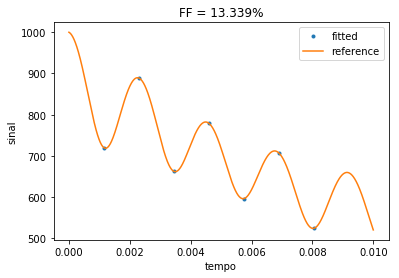

rho_fat = 143.571
rho_water = 856.429
rho_tot = 1000.000
OK


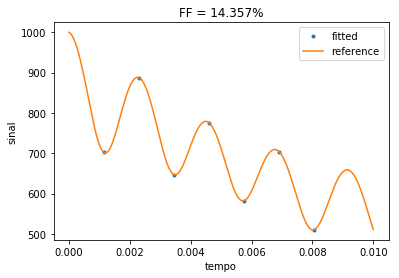

rho_fat = 153.755
rho_water = 846.245
rho_tot = 1000.000
OK


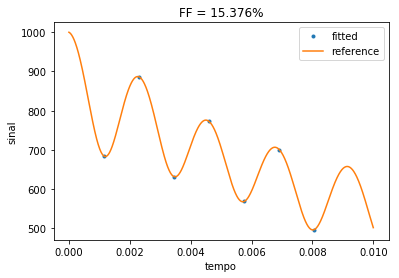

rho_fat = 163.939
rho_water = 836.061
rho_tot = 1000.000
OK


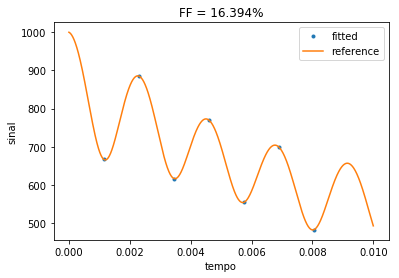

rho_fat = 174.122
rho_water = 825.878
rho_tot = 1000.000
OK


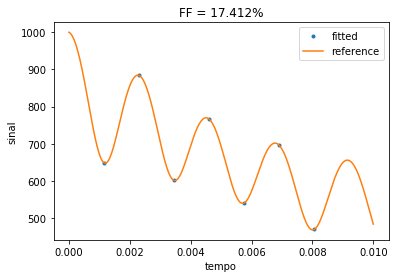

rho_fat = 184.306
rho_water = 815.694
rho_tot = 1000.000
OK


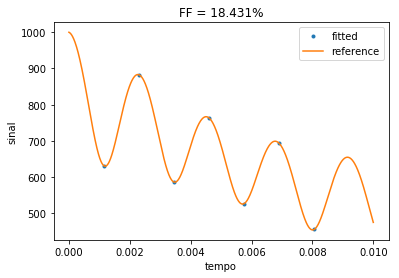

rho_fat = 194.490
rho_water = 805.510
rho_tot = 1000.000
OK


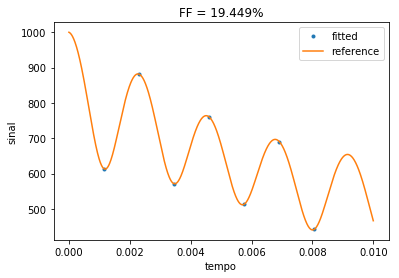

rho_fat = 204.673
rho_water = 795.327
rho_tot = 1000.000
OK


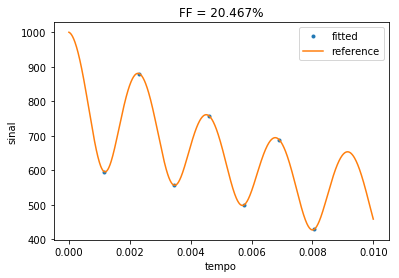

rho_fat = 214.857
rho_water = 785.143
rho_tot = 1000.000
OK


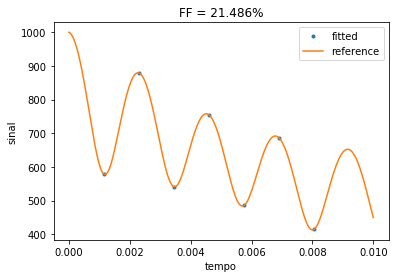

rho_fat = 225.041
rho_water = 774.959
rho_tot = 1000.000
OK


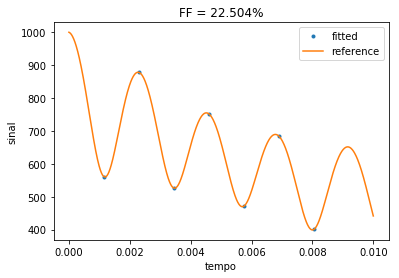

rho_fat = 235.224
rho_water = 764.776
rho_tot = 1000.000
OK


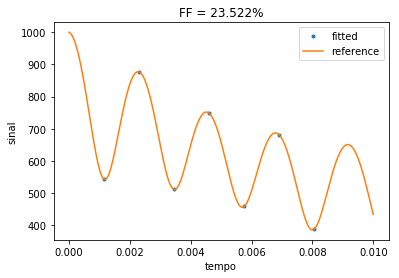

rho_fat = 245.408
rho_water = 754.592
rho_tot = 1000.000
OK


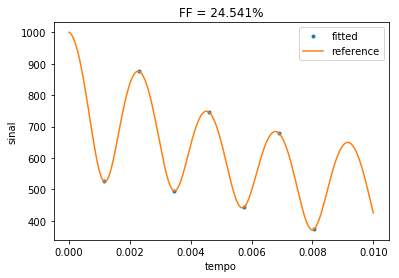

rho_fat = 255.592
rho_water = 744.408
rho_tot = 1000.000
OK


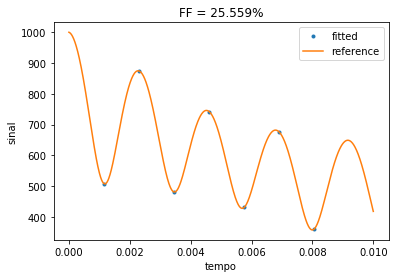

rho_fat = 265.776
rho_water = 734.224
rho_tot = 1000.000
OK


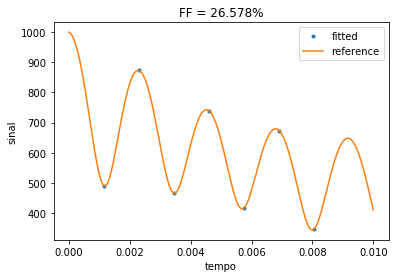

rho_fat = 275.959
rho_water = 724.041
rho_tot = 1000.000
OK


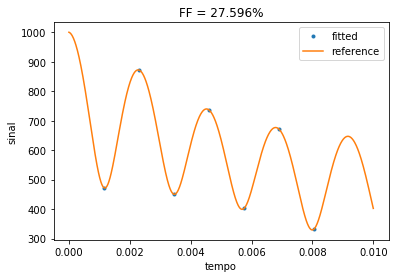

rho_fat = 286.143
rho_water = 713.857
rho_tot = 1000.000
OK


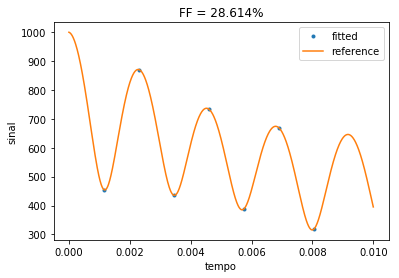

rho_fat = 296.327
rho_water = 703.673
rho_tot = 1000.000
OK


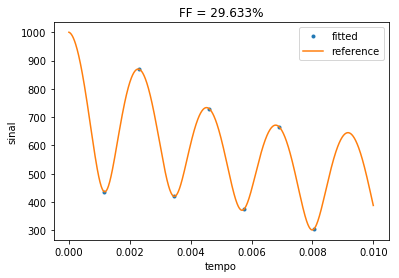

rho_fat = 306.510
rho_water = 693.490
rho_tot = 1000.000
OK


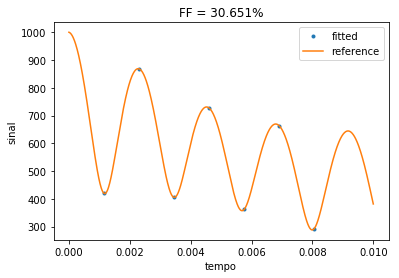

rho_fat = 316.694
rho_water = 683.306
rho_tot = 1000.000
OK


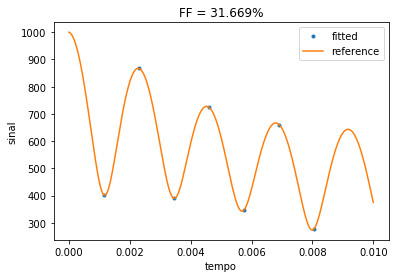

rho_fat = 326.878
rho_water = 673.122
rho_tot = 1000.000
OK


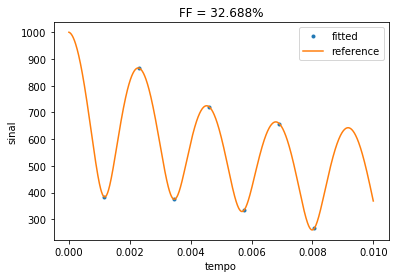

rho_fat = 337.061
rho_water = 662.939
rho_tot = 1000.000
OK


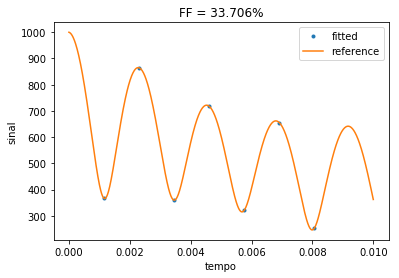

rho_fat = 347.245
rho_water = 652.755
rho_tot = 1000.000
OK


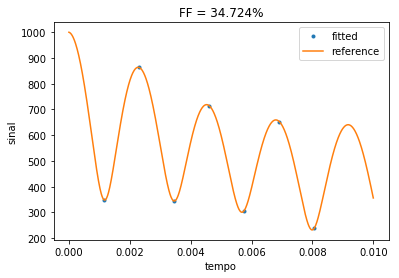

rho_fat = 357.429
rho_water = 642.571
rho_tot = 1000.000
OK


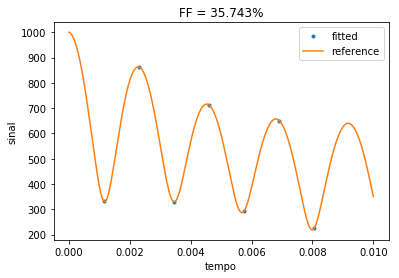

rho_fat = 367.612
rho_water = 632.388
rho_tot = 1000.000
OK


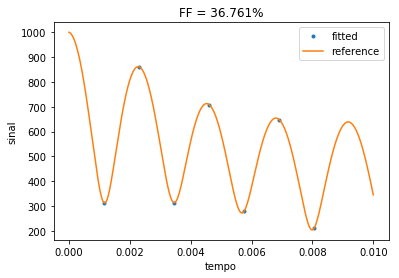

rho_fat = 377.796
rho_water = 622.204
rho_tot = 1000.000
OK


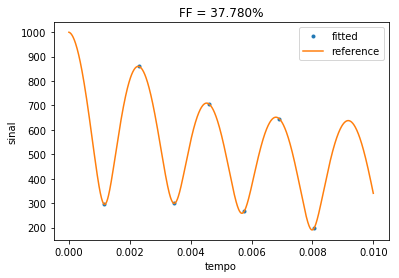

rho_fat = 387.980
rho_water = 612.020
rho_tot = 1000.000
OK


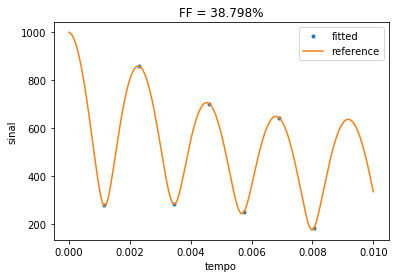

rho_fat = 398.163
rho_water = 601.837
rho_tot = 1000.000
OK


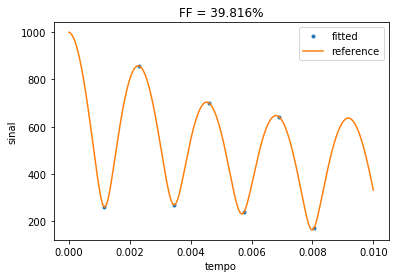

rho_fat = 408.347
rho_water = 591.653
rho_tot = 1000.000
OK


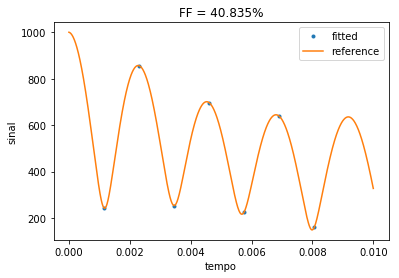

rho_fat = 418.531
rho_water = 581.469
rho_tot = 1000.000
OK


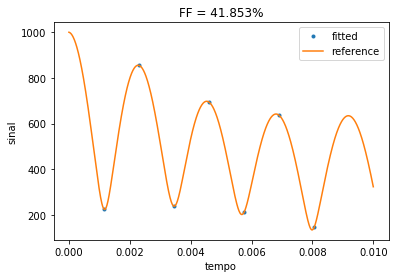

rho_fat = 428.714
rho_water = 571.286
rho_tot = 1000.000
OK


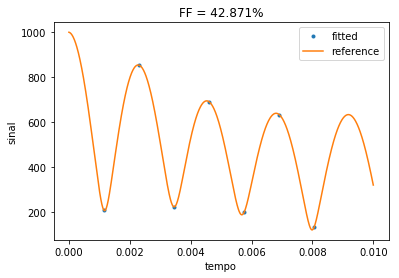

rho_fat = 438.898
rho_water = 561.102
rho_tot = 1000.000
OK


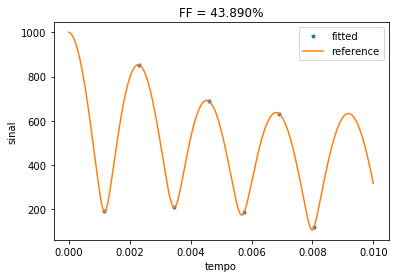

rho_fat = 449.082
rho_water = 550.918
rho_tot = 1000.000
OK


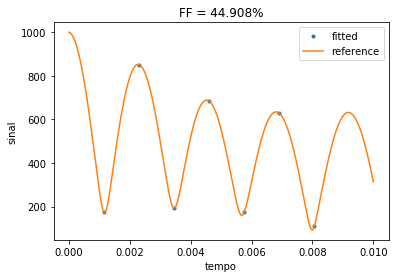

rho_fat = 459.265
rho_water = 540.735
rho_tot = 1000.000
OK


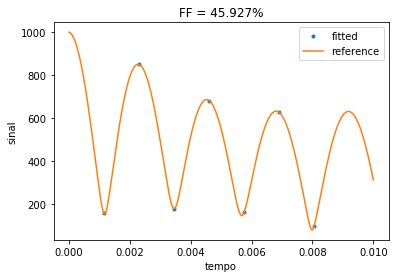

rho_fat = 469.449
rho_water = 530.551
rho_tot = 1000.000
OK


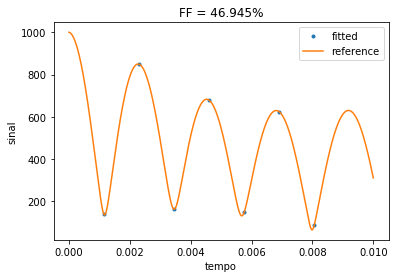

rho_fat = 479.633
rho_water = 520.367
rho_tot = 1000.000
OK


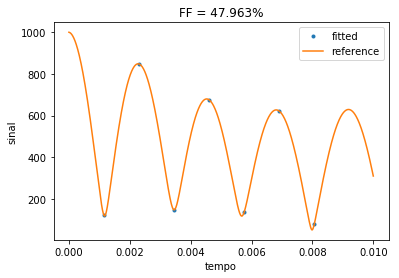

rho_fat = 489.816
rho_water = 510.184
rho_tot = 1000.000
OK


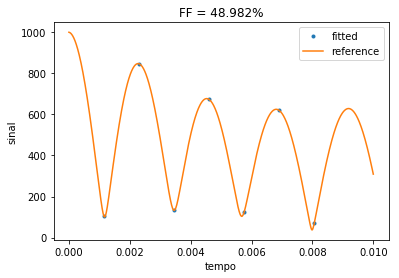

rho_fat = 500.000
rho_water = 500.000
rho_tot = 1000.000
OK


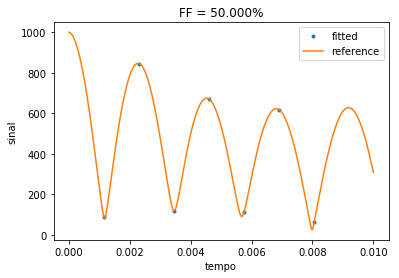

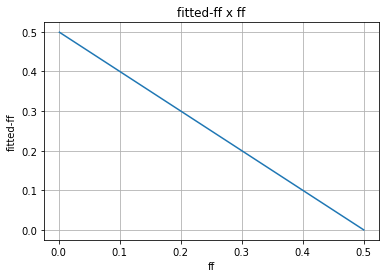

In [4]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 1000               # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted1000 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata)
    fitted1000.append(calc_fatfrac(fitted_par))
    
    ref1000 = np.zeros(np.size(fitted1000))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: print('Diferentes')
    
    plt.figure()
    plt.plot(xdata, ydata, '.', label='fitted')
    plt.plot(x, gen_GRE(x, *fitted_par), label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('tempo')
    plt.ylabel('sinal')
    plt.legend()
    plt.show()
    
plt.plot(ff, (fitted1000-ff), lw=1.5)
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.title('fitted-ff x ff')
plt.grid(True)
plt.show()

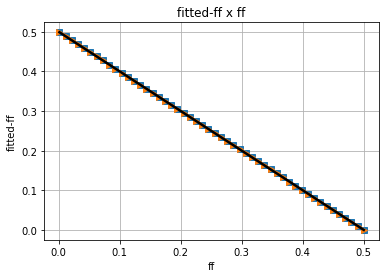

In [5]:
plt.plot(ff, (fitted10-ff), 's')
plt.plot(ff, (fitted100-ff), '>', lw=1.5)
plt.plot(ff, (fitted1000-ff), 'k-', lw=2.5)
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.title('fitted-ff x ff')
plt.grid(True)
plt.show()

# Teste 2:
## Variando o valor inicial da gordura

rho_fat = 0.010
rho_water = 9.990
rho_tot = 10.000
OK


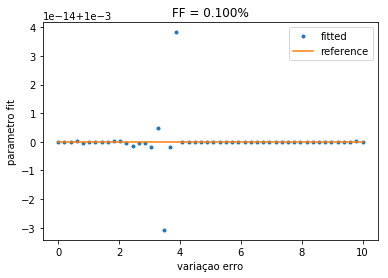

rho_fat = 0.112
rho_water = 9.888
rho_tot = 10.000
OK


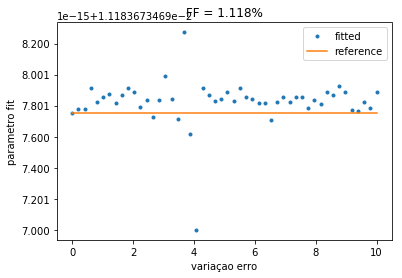

rho_fat = 0.214
rho_water = 9.786
rho_tot = 10.000
OK


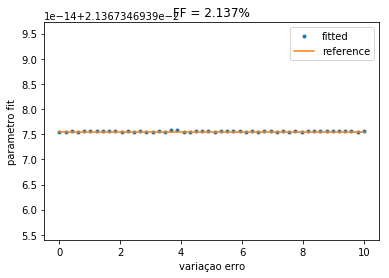

rho_fat = 0.316
rho_water = 9.684
rho_tot = 10.000
OK


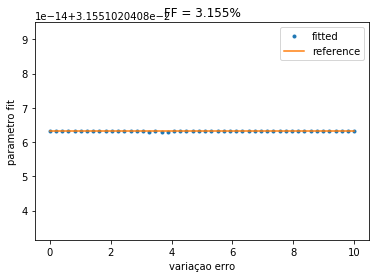

rho_fat = 0.417
rho_water = 9.583
rho_tot = 10.000
OK


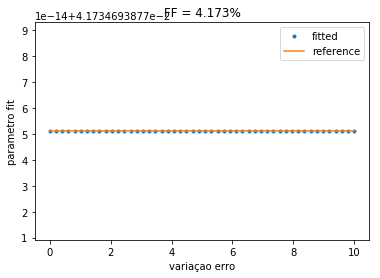

rho_fat = 0.519
rho_water = 9.481
rho_tot = 10.000
OK


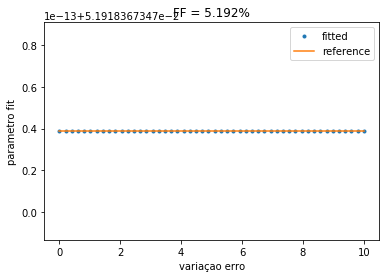

rho_fat = 0.621
rho_water = 9.379
rho_tot = 10.000
OK


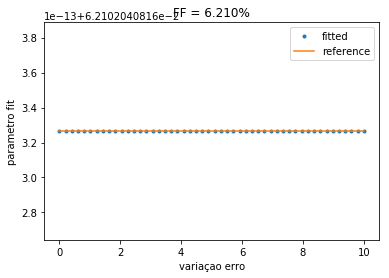

rho_fat = 0.723
rho_water = 9.277
rho_tot = 10.000
OK


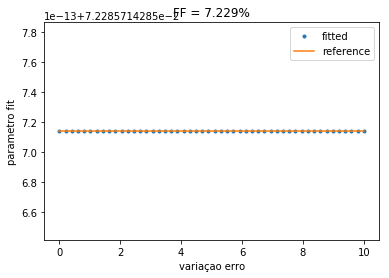

rho_fat = 0.825
rho_water = 9.175
rho_tot = 10.000
OK


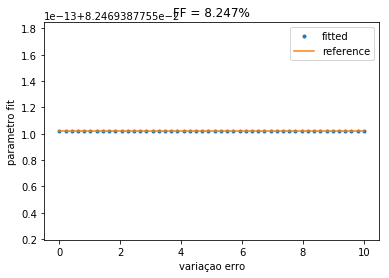

rho_fat = 0.927
rho_water = 9.073
rho_tot = 10.000
OK


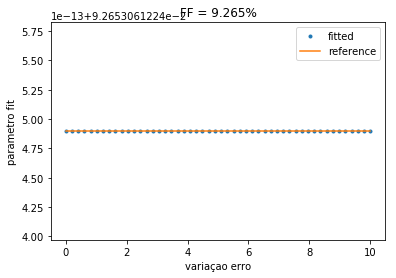

rho_fat = 1.028
rho_water = 8.972
rho_tot = 10.000
OK


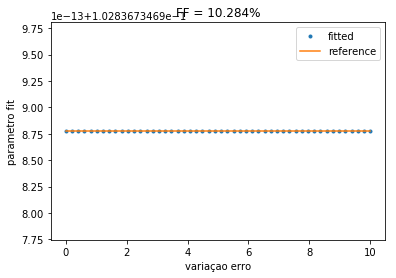

rho_fat = 1.130
rho_water = 8.870
rho_tot = 10.000
OK


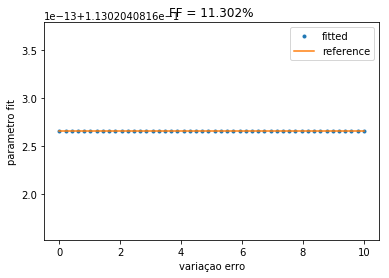

rho_fat = 1.232
rho_water = 8.768
rho_tot = 10.000
OK


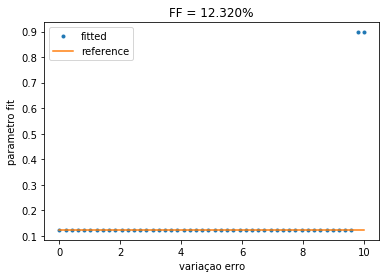

rho_fat = 1.334
rho_water = 8.666
rho_tot = 10.000
OK


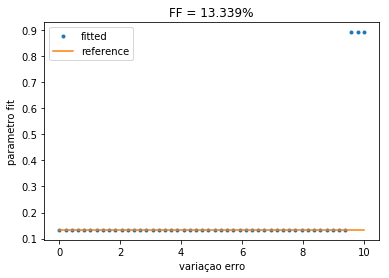

rho_fat = 1.436
rho_water = 8.564
rho_tot = 10.000
OK


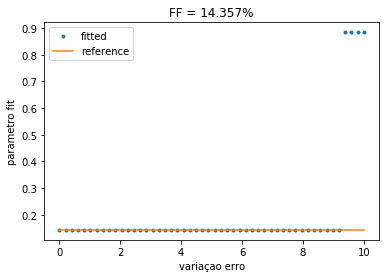

rho_fat = 1.538
rho_water = 8.462
rho_tot = 10.000
OK


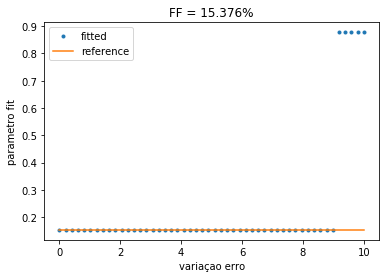

rho_fat = 1.639
rho_water = 8.361
rho_tot = 10.000
OK


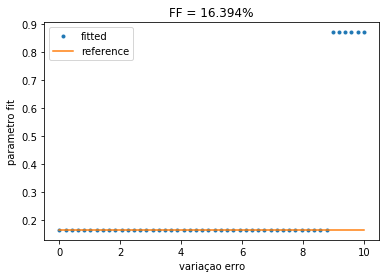

rho_fat = 1.741
rho_water = 8.259
rho_tot = 10.000
OK


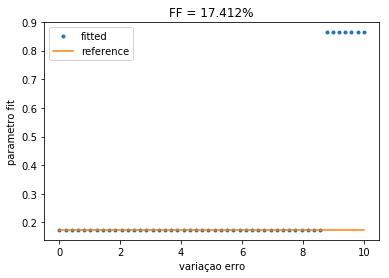

rho_fat = 1.843
rho_water = 8.157
rho_tot = 10.000
OK


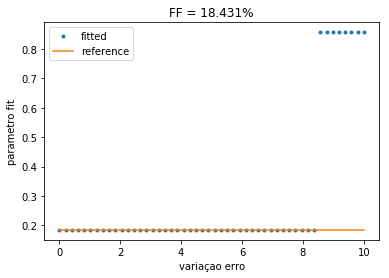

rho_fat = 1.945
rho_water = 8.055
rho_tot = 10.000
OK


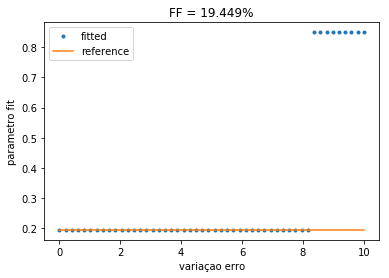

rho_fat = 2.047
rho_water = 7.953
rho_tot = 10.000
OK


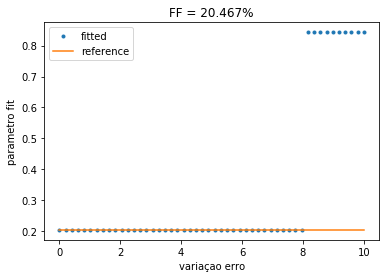

rho_fat = 2.149
rho_water = 7.851
rho_tot = 10.000
OK


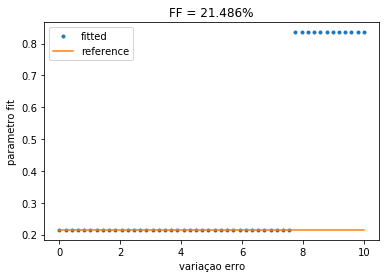

rho_fat = 2.250
rho_water = 7.750
rho_tot = 10.000
OK


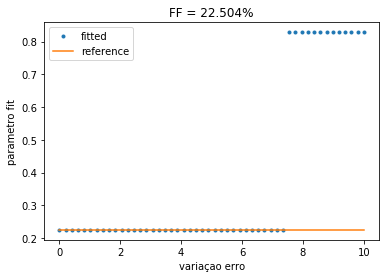

rho_fat = 2.352
rho_water = 7.648
rho_tot = 10.000
OK


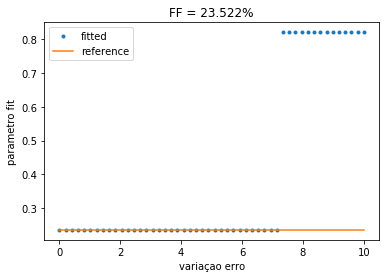

rho_fat = 2.454
rho_water = 7.546
rho_tot = 10.000
OK


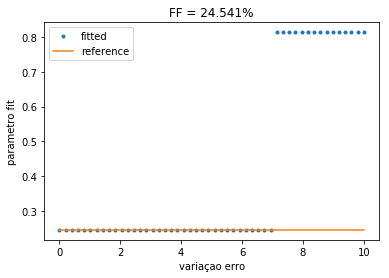

rho_fat = 2.556
rho_water = 7.444
rho_tot = 10.000
OK


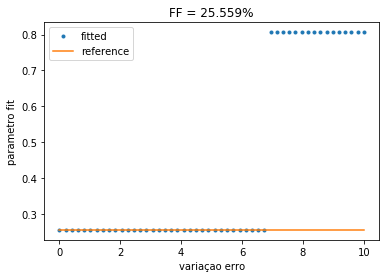

rho_fat = 2.658
rho_water = 7.342
rho_tot = 10.000
OK


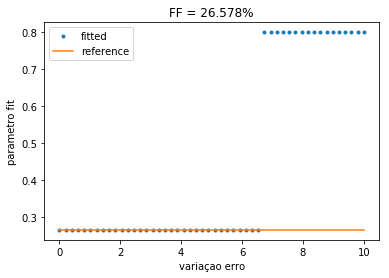

rho_fat = 2.760
rho_water = 7.240
rho_tot = 10.000
OK


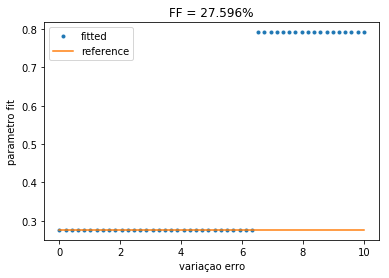

rho_fat = 2.861
rho_water = 7.139
rho_tot = 10.000
OK


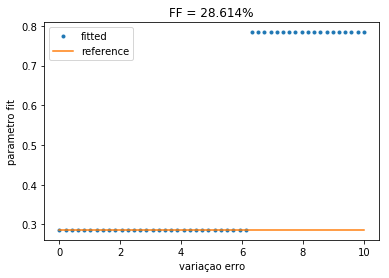

rho_fat = 2.963
rho_water = 7.037
rho_tot = 10.000
OK


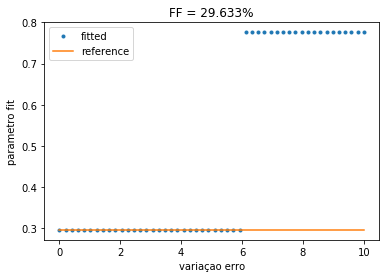

rho_fat = 3.065
rho_water = 6.935
rho_tot = 10.000
OK


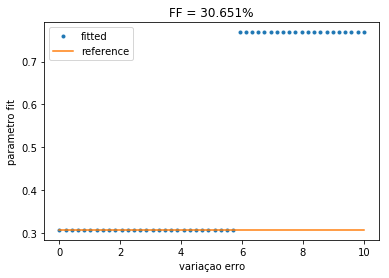

rho_fat = 3.167
rho_water = 6.833
rho_tot = 10.000
OK


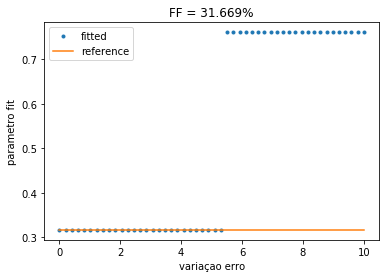

rho_fat = 3.269
rho_water = 6.731
rho_tot = 10.000
OK


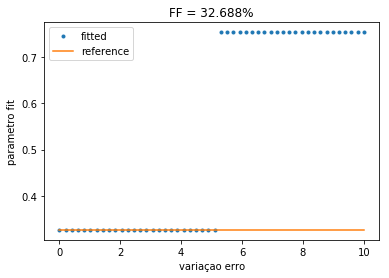

rho_fat = 3.371
rho_water = 6.629
rho_tot = 10.000
OK


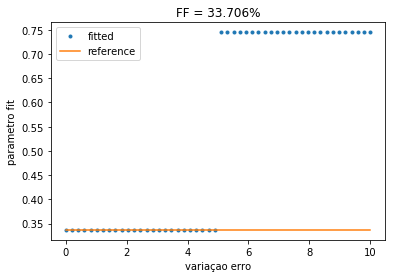

rho_fat = 3.472
rho_water = 6.528
rho_tot = 10.000
OK


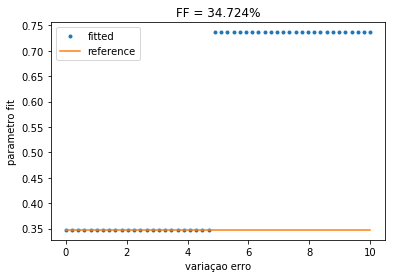

rho_fat = 3.574
rho_water = 6.426
rho_tot = 10.000
OK


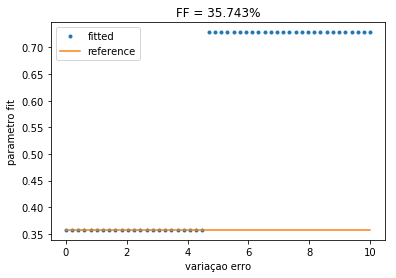

rho_fat = 3.676
rho_water = 6.324
rho_tot = 10.000
OK


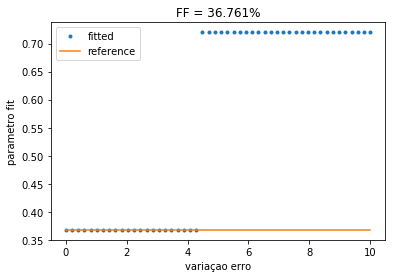

rho_fat = 3.778
rho_water = 6.222
rho_tot = 10.000
OK


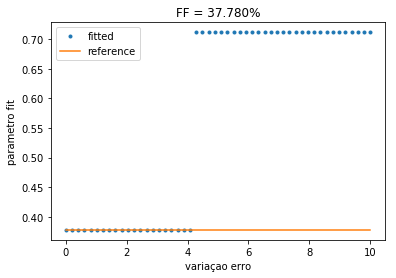

rho_fat = 3.880
rho_water = 6.120
rho_tot = 10.000
OK


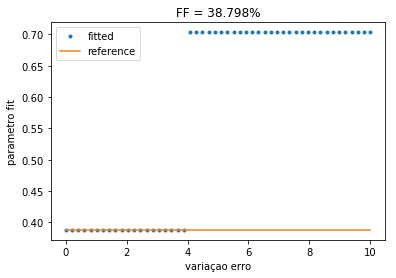

rho_fat = 3.982
rho_water = 6.018
rho_tot = 10.000
OK


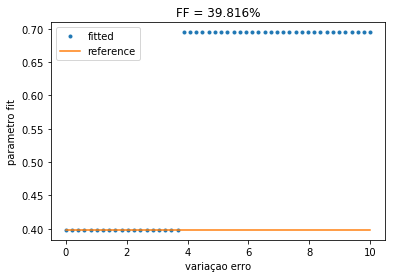

rho_fat = 4.083
rho_water = 5.917
rho_tot = 10.000
OK


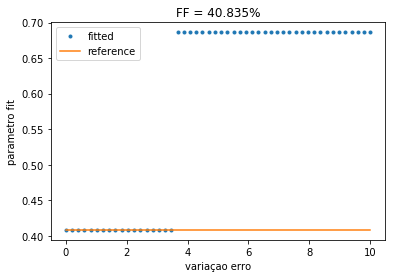

rho_fat = 4.185
rho_water = 5.815
rho_tot = 10.000
OK


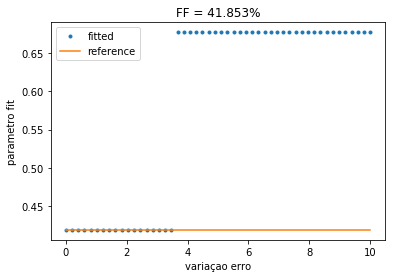

rho_fat = 4.287
rho_water = 5.713
rho_tot = 10.000
OK


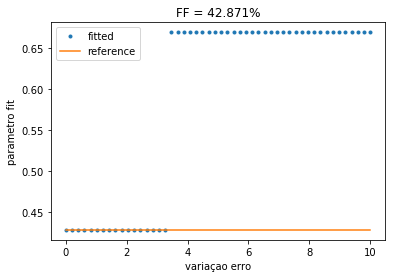

rho_fat = 4.389
rho_water = 5.611
rho_tot = 10.000
OK


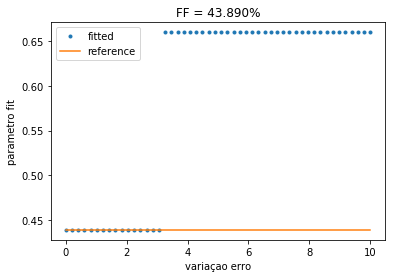

rho_fat = 4.491
rho_water = 5.509
rho_tot = 10.000
OK


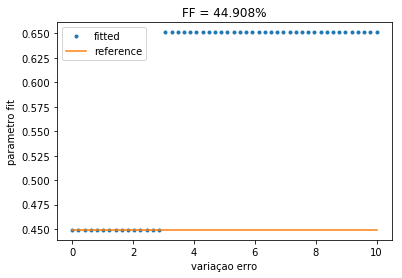

rho_fat = 4.593
rho_water = 5.407
rho_tot = 10.000
OK


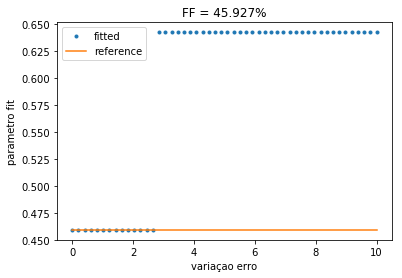

rho_fat = 4.694
rho_water = 5.306
rho_tot = 10.000
OK


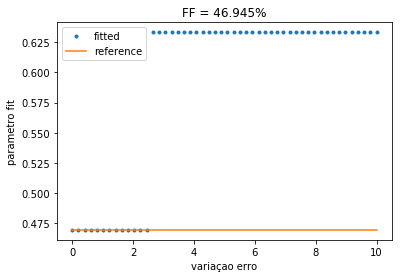

rho_fat = 4.796
rho_water = 5.204
rho_tot = 10.000
OK


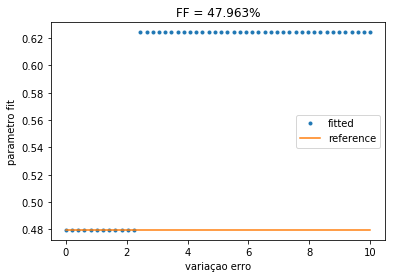

rho_fat = 4.898
rho_water = 5.102
rho_tot = 10.000
OK


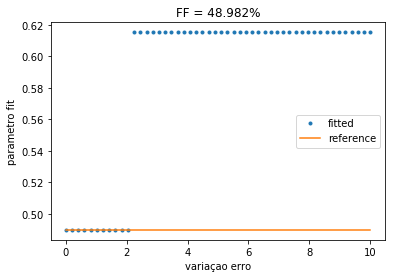

rho_fat = 5.000
rho_water = 5.000
rho_tot = 10.000
OK


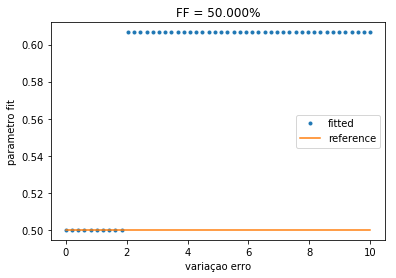

In [6]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 10                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(calc_fatfrac(fitted_par))
    
    ref10 = np.zeros(np.size(fitted10))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted10, '.', label='fitted')
    plt.plot(init_guess_var, ref10, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

rho_fat = 0.100
rho_water = 99.900
rho_tot = 100.000
OK


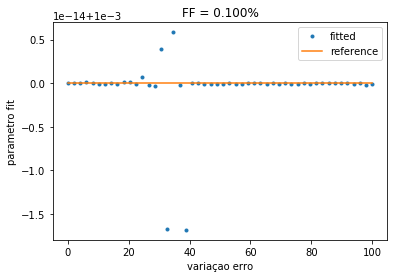

rho_fat = 1.118
rho_water = 98.882
rho_tot = 100.000
OK


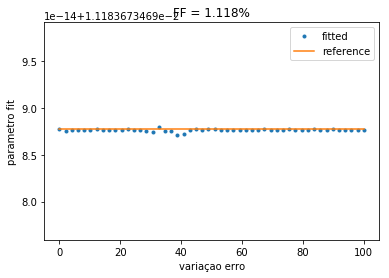

rho_fat = 2.137
rho_water = 97.863
rho_tot = 100.000
OK


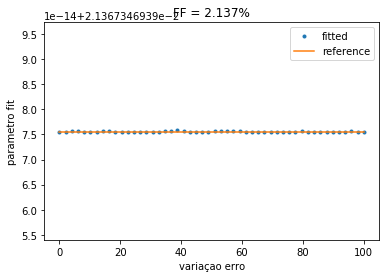

rho_fat = 3.155
rho_water = 96.845
rho_tot = 100.000
OK


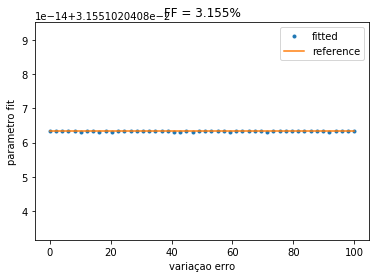

rho_fat = 4.173
rho_water = 95.827
rho_tot = 100.000
OK


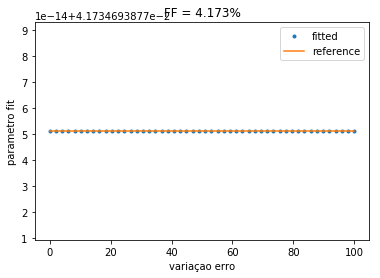

rho_fat = 5.192
rho_water = 94.808
rho_tot = 100.000
OK


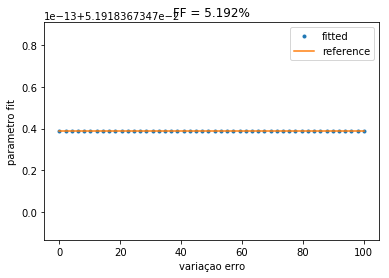

rho_fat = 6.210
rho_water = 93.790
rho_tot = 100.000
OK


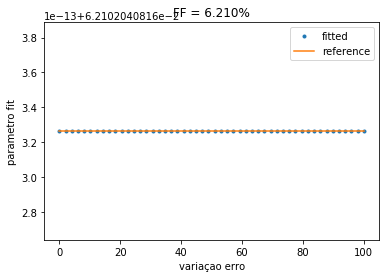

rho_fat = 7.229
rho_water = 92.771
rho_tot = 100.000
OK


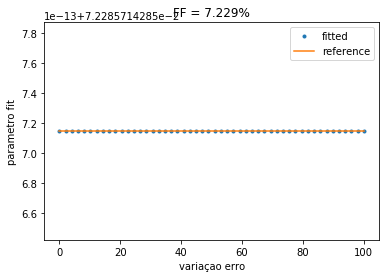

rho_fat = 8.247
rho_water = 91.753
rho_tot = 100.000
OK


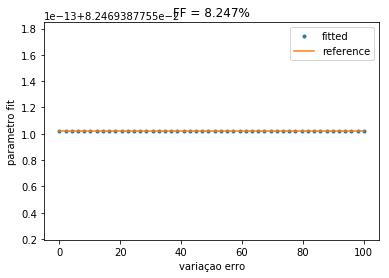

rho_fat = 9.265
rho_water = 90.735
rho_tot = 100.000
OK


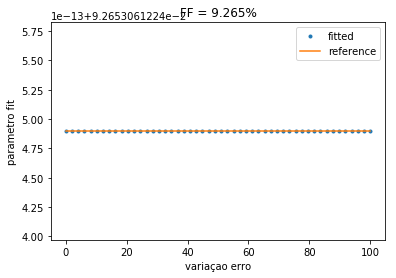

rho_fat = 10.284
rho_water = 89.716
rho_tot = 100.000
OK


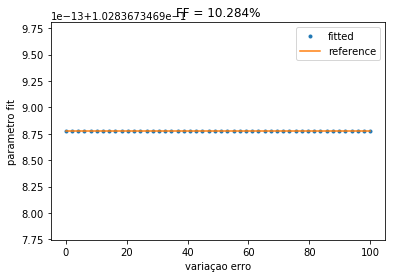

rho_fat = 11.302
rho_water = 88.698
rho_tot = 100.000
OK


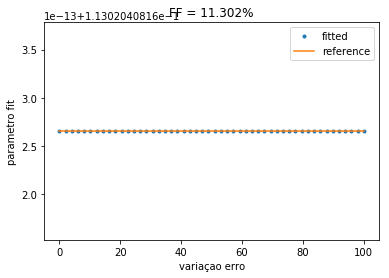

rho_fat = 12.320
rho_water = 87.680
rho_tot = 100.000
OK


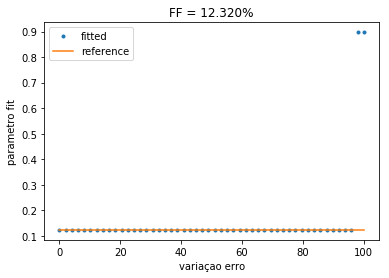

rho_fat = 13.339
rho_water = 86.661
rho_tot = 100.000
OK


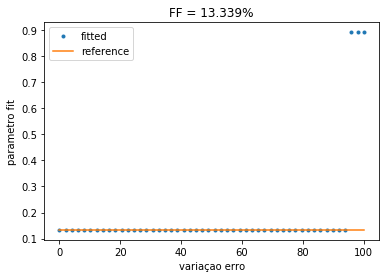

rho_fat = 14.357
rho_water = 85.643
rho_tot = 100.000
OK


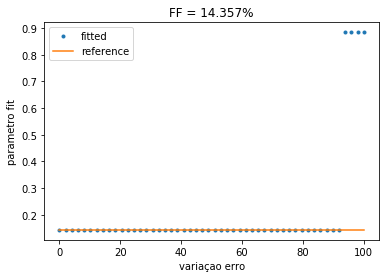

rho_fat = 15.376
rho_water = 84.624
rho_tot = 100.000
OK


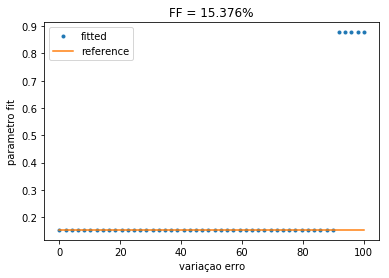

rho_fat = 16.394
rho_water = 83.606
rho_tot = 100.000
OK


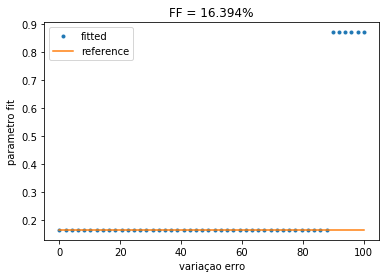

rho_fat = 17.412
rho_water = 82.588
rho_tot = 100.000
OK


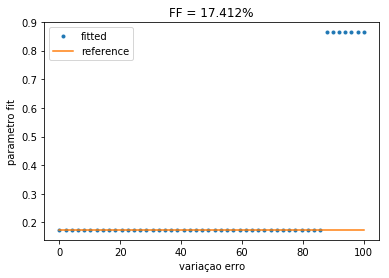

rho_fat = 18.431
rho_water = 81.569
rho_tot = 100.000
OK


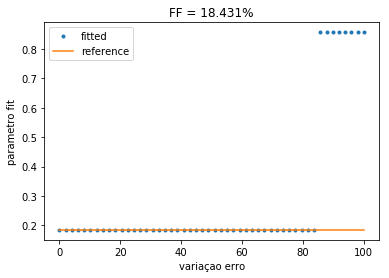

rho_fat = 19.449
rho_water = 80.551
rho_tot = 100.000
OK


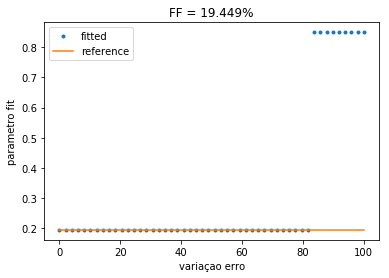

rho_fat = 20.467
rho_water = 79.533
rho_tot = 100.000
OK


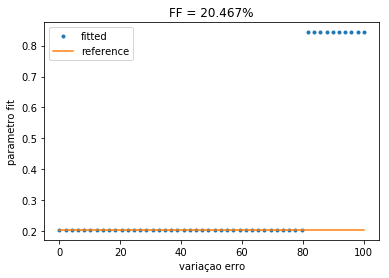

rho_fat = 21.486
rho_water = 78.514
rho_tot = 100.000
OK


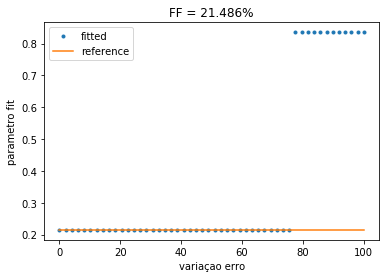

rho_fat = 22.504
rho_water = 77.496
rho_tot = 100.000
OK


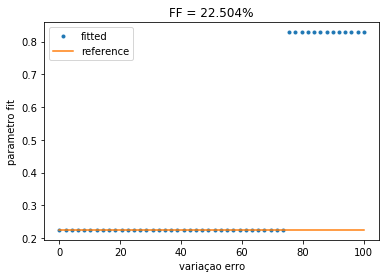

rho_fat = 23.522
rho_water = 76.478
rho_tot = 100.000
OK


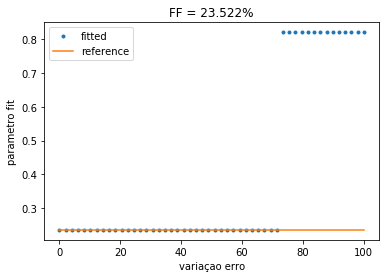

rho_fat = 24.541
rho_water = 75.459
rho_tot = 100.000
OK


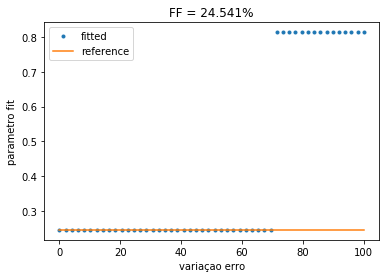

rho_fat = 25.559
rho_water = 74.441
rho_tot = 100.000
OK


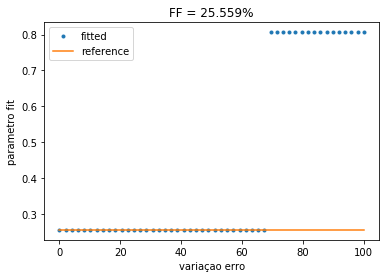

rho_fat = 26.578
rho_water = 73.422
rho_tot = 100.000
OK


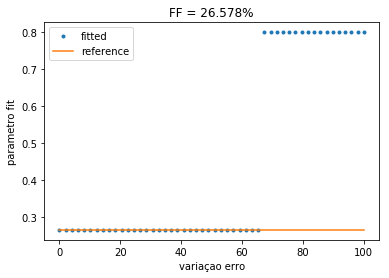

rho_fat = 27.596
rho_water = 72.404
rho_tot = 100.000
OK


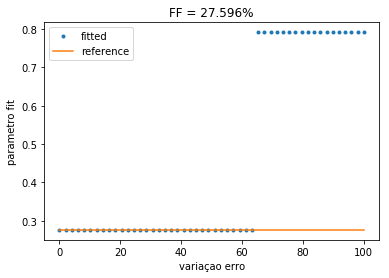

rho_fat = 28.614
rho_water = 71.386
rho_tot = 100.000
OK


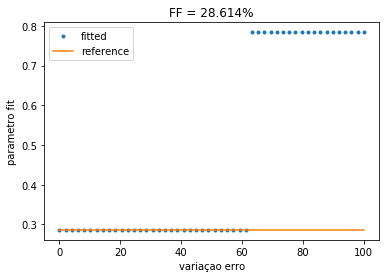

rho_fat = 29.633
rho_water = 70.367
rho_tot = 100.000
OK


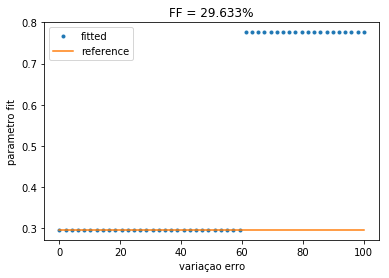

rho_fat = 30.651
rho_water = 69.349
rho_tot = 100.000
OK


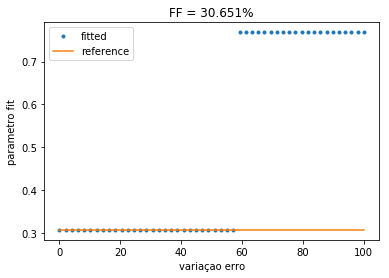

rho_fat = 31.669
rho_water = 68.331
rho_tot = 100.000
OK


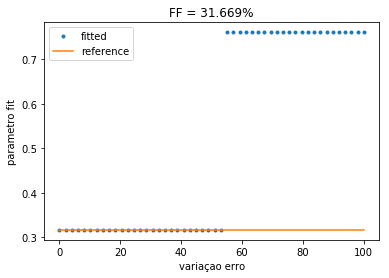

rho_fat = 32.688
rho_water = 67.312
rho_tot = 100.000
OK


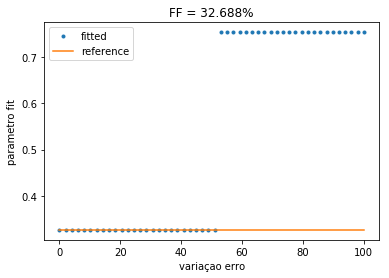

rho_fat = 33.706
rho_water = 66.294
rho_tot = 100.000
OK


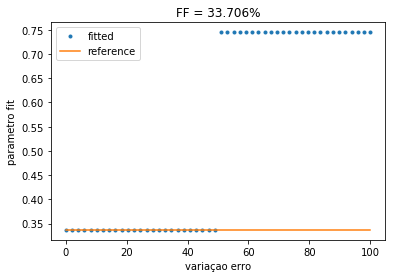

rho_fat = 34.724
rho_water = 65.276
rho_tot = 100.000
OK


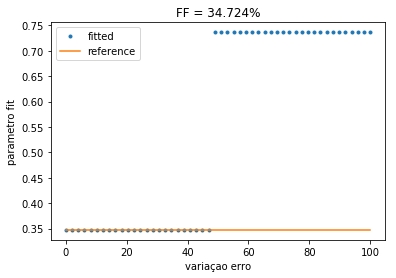

rho_fat = 35.743
rho_water = 64.257
rho_tot = 100.000
OK


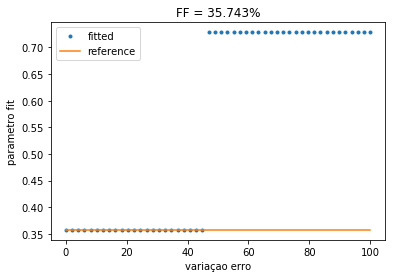

rho_fat = 36.761
rho_water = 63.239
rho_tot = 100.000
OK


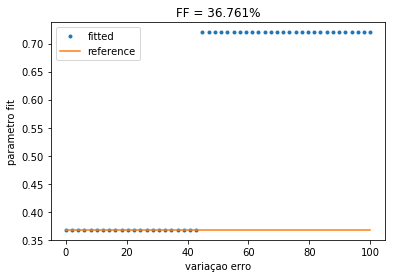

rho_fat = 37.780
rho_water = 62.220
rho_tot = 100.000
OK


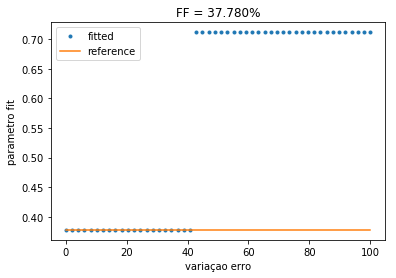

rho_fat = 38.798
rho_water = 61.202
rho_tot = 100.000
OK


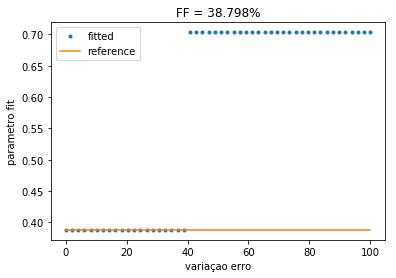

rho_fat = 39.816
rho_water = 60.184
rho_tot = 100.000
OK


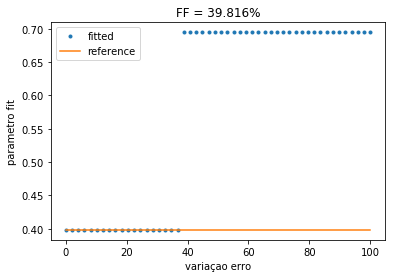

rho_fat = 40.835
rho_water = 59.165
rho_tot = 100.000
OK


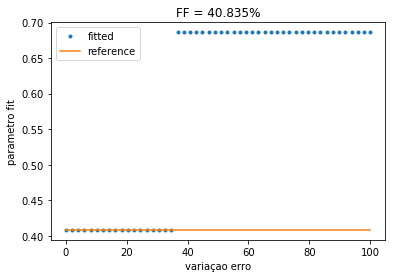

rho_fat = 41.853
rho_water = 58.147
rho_tot = 100.000
OK


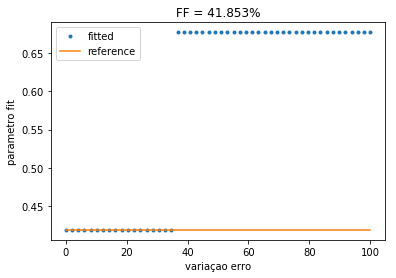

rho_fat = 42.871
rho_water = 57.129
rho_tot = 100.000
OK


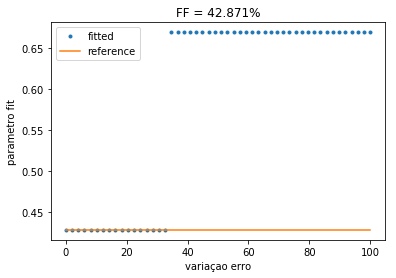

rho_fat = 43.890
rho_water = 56.110
rho_tot = 100.000
OK


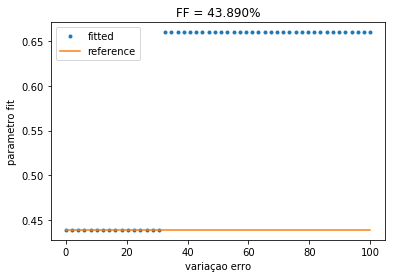

rho_fat = 44.908
rho_water = 55.092
rho_tot = 100.000
OK


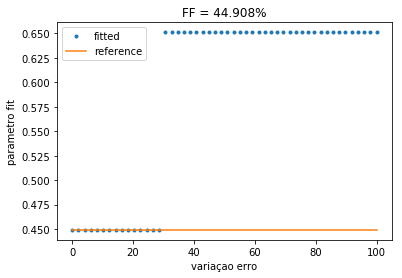

rho_fat = 45.927
rho_water = 54.073
rho_tot = 100.000
OK


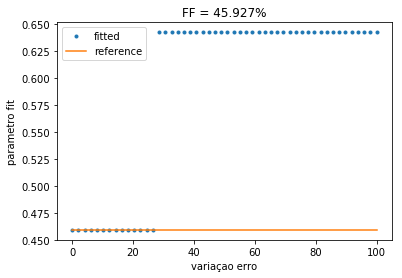

rho_fat = 46.945
rho_water = 53.055
rho_tot = 100.000
OK


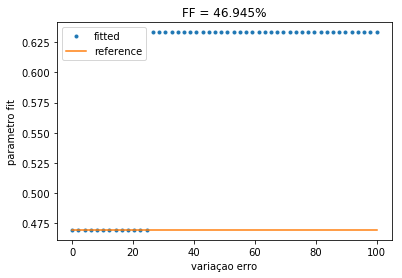

rho_fat = 47.963
rho_water = 52.037
rho_tot = 100.000
OK


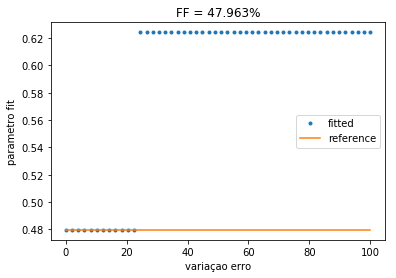

rho_fat = 48.982
rho_water = 51.018
rho_tot = 100.000
OK


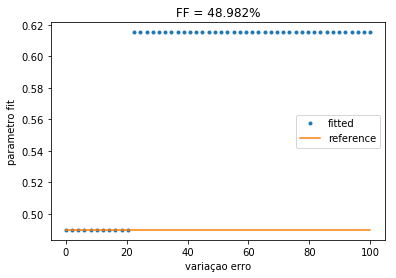

rho_fat = 50.000
rho_water = 50.000
rho_tot = 100.000
OK


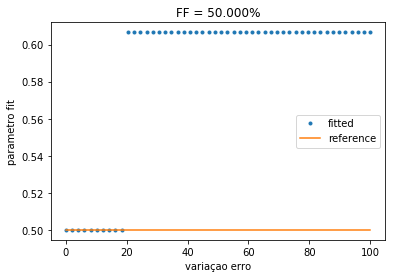

In [7]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 100                # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted100 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted100.append(calc_fatfrac(fitted_par))
    
    ref100 = np.zeros(np.size(fitted100))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted100, '.', label='fitted')
    plt.plot(init_guess_var, ref100, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

rho_fat = 1.000
rho_water = 999.000
rho_tot = 1000.000
OK


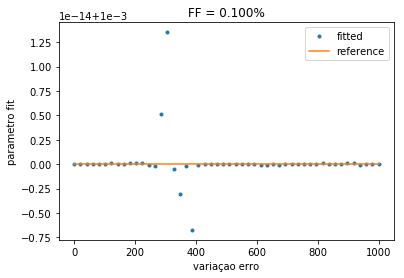

rho_fat = 11.184
rho_water = 988.816
rho_tot = 1000.000
OK


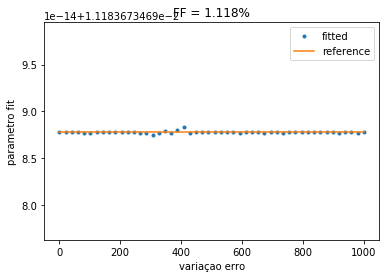

rho_fat = 21.367
rho_water = 978.633
rho_tot = 1000.000
OK


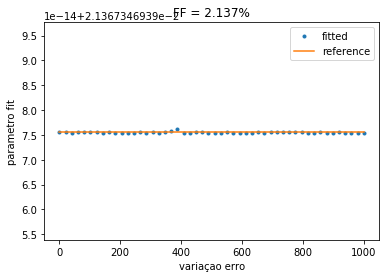

rho_fat = 31.551
rho_water = 968.449
rho_tot = 1000.000
OK


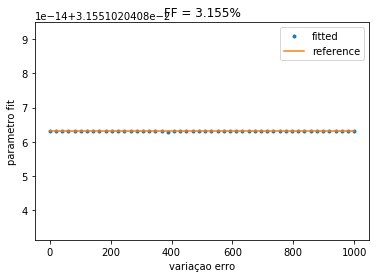

rho_fat = 41.735
rho_water = 958.265
rho_tot = 1000.000
OK


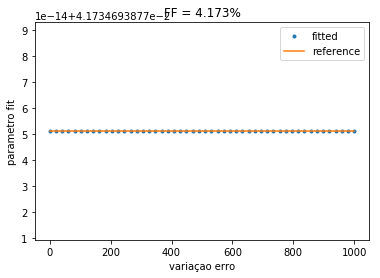

rho_fat = 51.918
rho_water = 948.082
rho_tot = 1000.000
OK


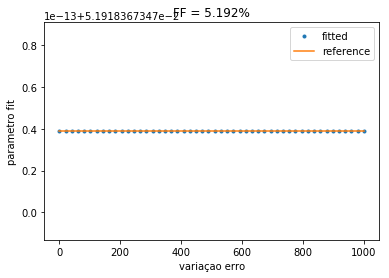

rho_fat = 62.102
rho_water = 937.898
rho_tot = 1000.000
OK


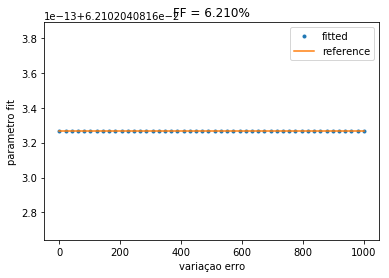

rho_fat = 72.286
rho_water = 927.714
rho_tot = 1000.000
OK


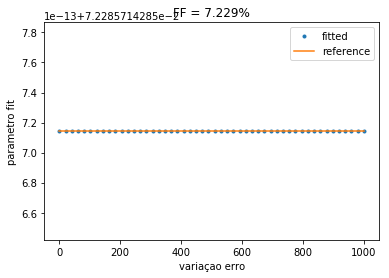

rho_fat = 82.469
rho_water = 917.531
rho_tot = 1000.000
OK


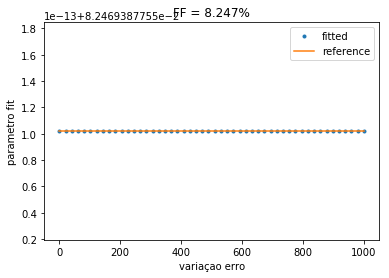

rho_fat = 92.653
rho_water = 907.347
rho_tot = 1000.000
OK


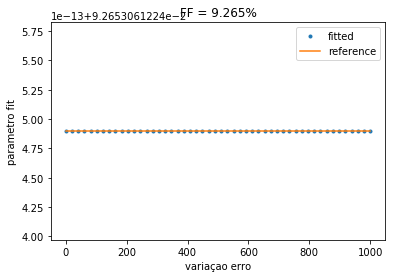

rho_fat = 102.837
rho_water = 897.163
rho_tot = 1000.000
OK


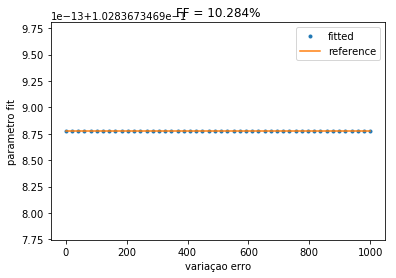

rho_fat = 113.020
rho_water = 886.980
rho_tot = 1000.000
OK


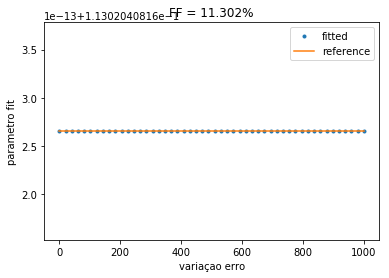

rho_fat = 123.204
rho_water = 876.796
rho_tot = 1000.000
OK


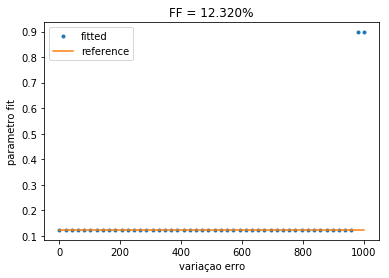

rho_fat = 133.388
rho_water = 866.612
rho_tot = 1000.000
OK


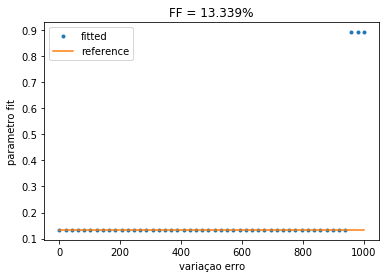

rho_fat = 143.571
rho_water = 856.429
rho_tot = 1000.000
OK


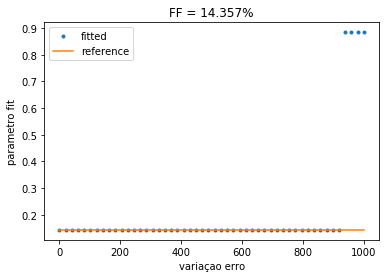

rho_fat = 153.755
rho_water = 846.245
rho_tot = 1000.000
OK


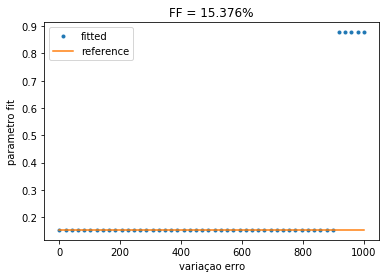

rho_fat = 163.939
rho_water = 836.061
rho_tot = 1000.000
OK


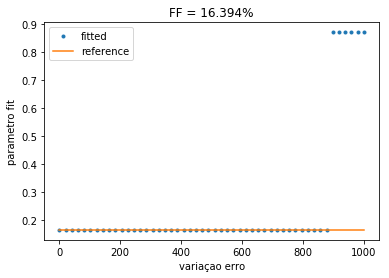

rho_fat = 174.122
rho_water = 825.878
rho_tot = 1000.000
OK


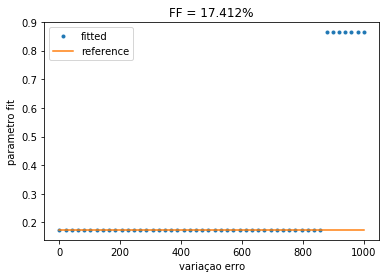

rho_fat = 184.306
rho_water = 815.694
rho_tot = 1000.000
OK


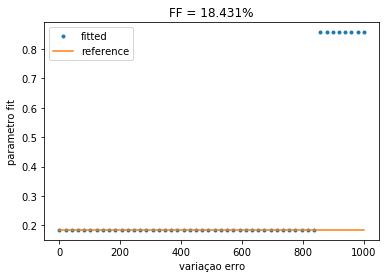

rho_fat = 194.490
rho_water = 805.510
rho_tot = 1000.000
OK


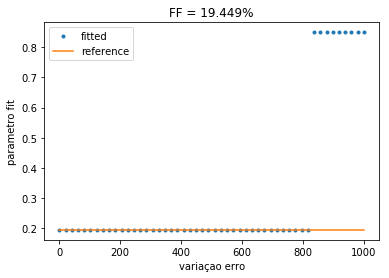

rho_fat = 204.673
rho_water = 795.327
rho_tot = 1000.000
OK


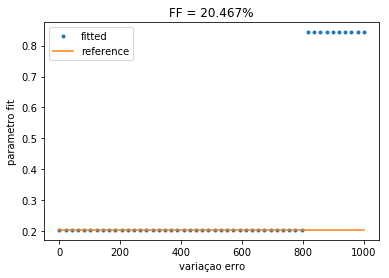

rho_fat = 214.857
rho_water = 785.143
rho_tot = 1000.000
OK


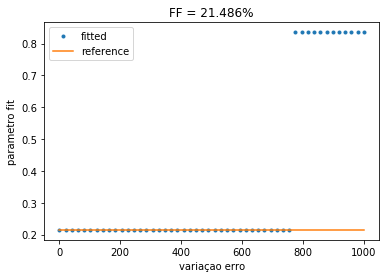

rho_fat = 225.041
rho_water = 774.959
rho_tot = 1000.000
OK


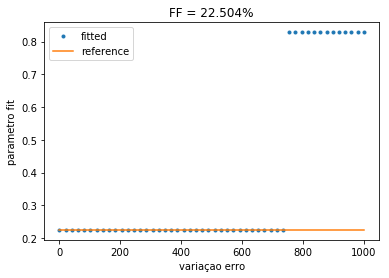

rho_fat = 235.224
rho_water = 764.776
rho_tot = 1000.000
OK


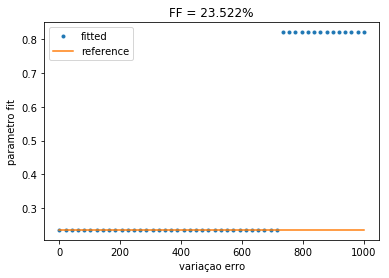

rho_fat = 245.408
rho_water = 754.592
rho_tot = 1000.000
OK


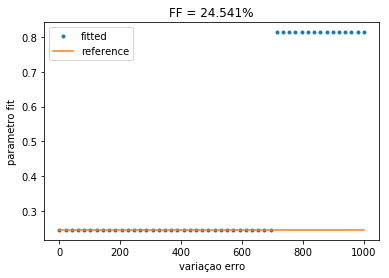

rho_fat = 255.592
rho_water = 744.408
rho_tot = 1000.000
OK


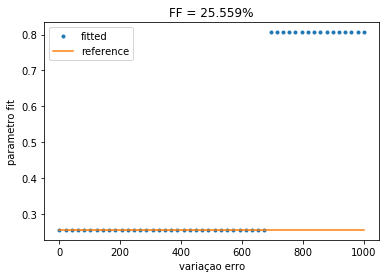

rho_fat = 265.776
rho_water = 734.224
rho_tot = 1000.000
OK


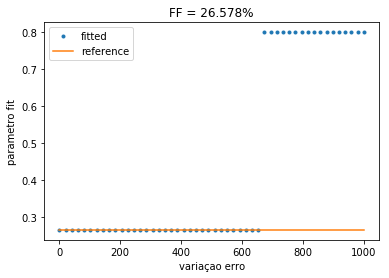

rho_fat = 275.959
rho_water = 724.041
rho_tot = 1000.000
OK


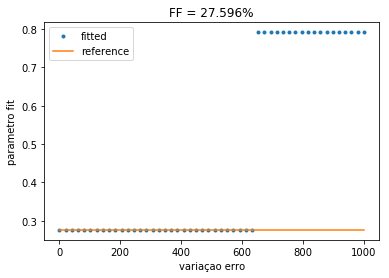

rho_fat = 286.143
rho_water = 713.857
rho_tot = 1000.000
OK


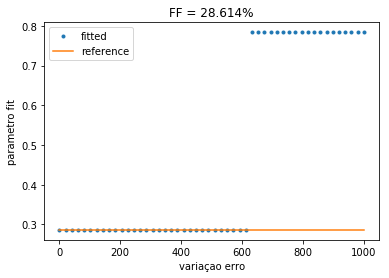

rho_fat = 296.327
rho_water = 703.673
rho_tot = 1000.000
OK


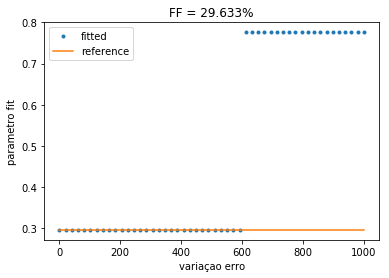

rho_fat = 306.510
rho_water = 693.490
rho_tot = 1000.000
OK


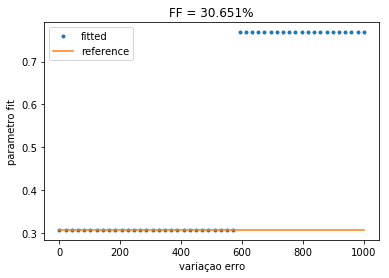

rho_fat = 316.694
rho_water = 683.306
rho_tot = 1000.000
OK


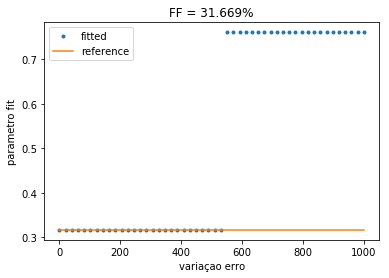

rho_fat = 326.878
rho_water = 673.122
rho_tot = 1000.000
OK


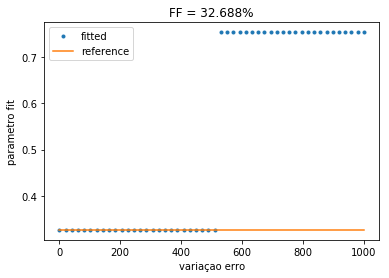

rho_fat = 337.061
rho_water = 662.939
rho_tot = 1000.000
OK


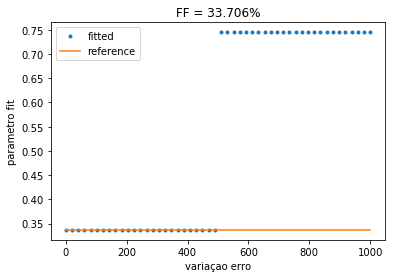

rho_fat = 347.245
rho_water = 652.755
rho_tot = 1000.000
OK


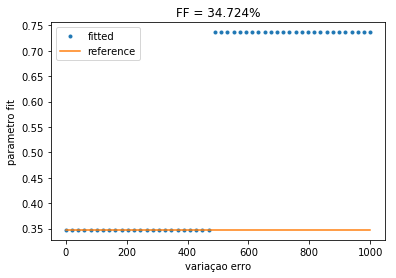

rho_fat = 357.429
rho_water = 642.571
rho_tot = 1000.000
OK


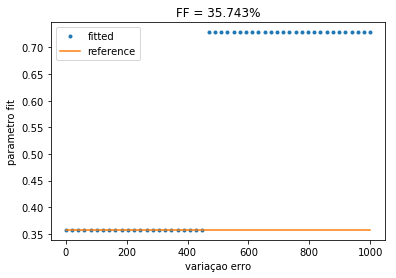

rho_fat = 367.612
rho_water = 632.388
rho_tot = 1000.000
OK


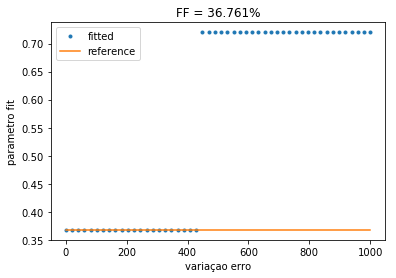

rho_fat = 377.796
rho_water = 622.204
rho_tot = 1000.000
OK


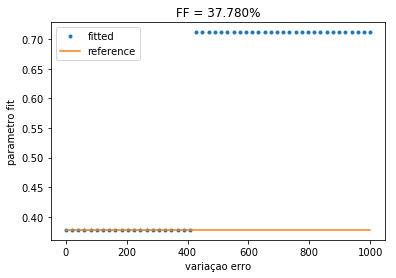

rho_fat = 387.980
rho_water = 612.020
rho_tot = 1000.000
OK


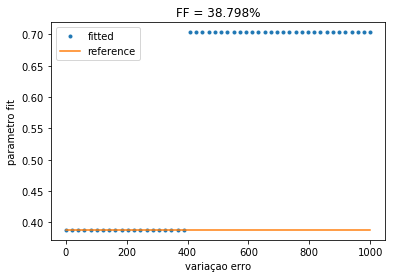

rho_fat = 398.163
rho_water = 601.837
rho_tot = 1000.000
OK


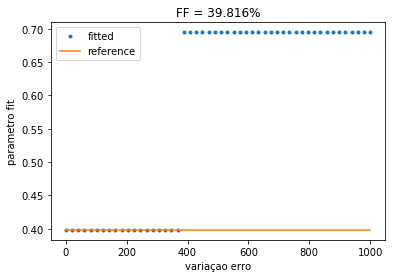

rho_fat = 408.347
rho_water = 591.653
rho_tot = 1000.000
OK


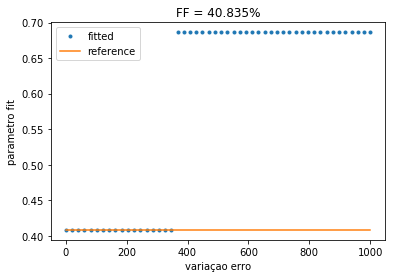

rho_fat = 418.531
rho_water = 581.469
rho_tot = 1000.000
OK


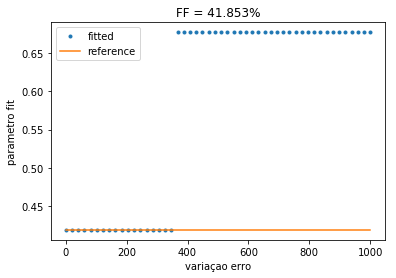

rho_fat = 428.714
rho_water = 571.286
rho_tot = 1000.000
OK


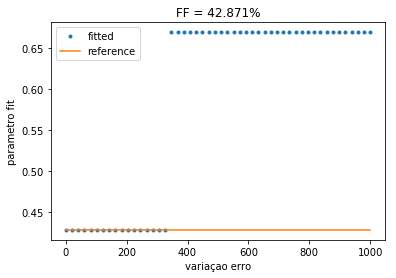

rho_fat = 438.898
rho_water = 561.102
rho_tot = 1000.000
OK


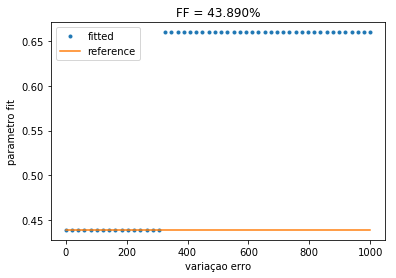

rho_fat = 449.082
rho_water = 550.918
rho_tot = 1000.000
OK


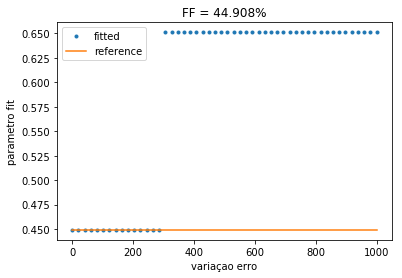

rho_fat = 459.265
rho_water = 540.735
rho_tot = 1000.000
OK


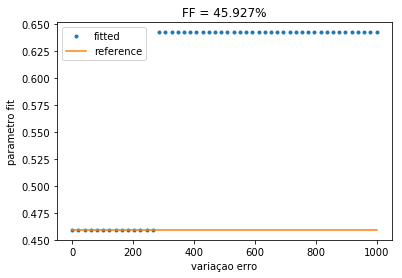

rho_fat = 469.449
rho_water = 530.551
rho_tot = 1000.000
OK


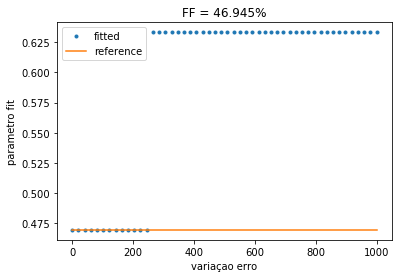

rho_fat = 479.633
rho_water = 520.367
rho_tot = 1000.000
OK


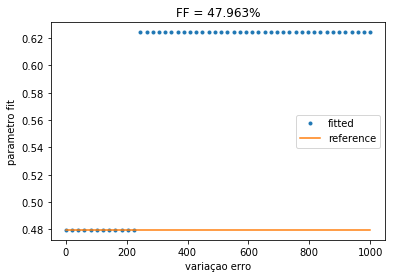

rho_fat = 489.816
rho_water = 510.184
rho_tot = 1000.000
OK


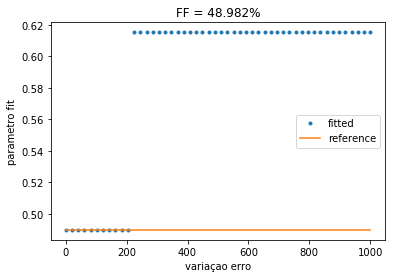

rho_fat = 500.000
rho_water = 500.000
rho_tot = 1000.000
OK


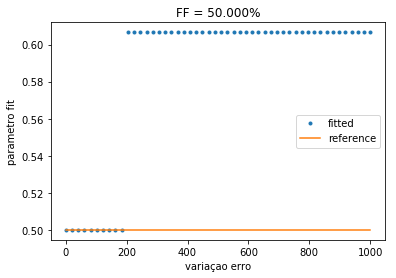

In [8]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 1000               # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted1000 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1000.append(calc_fatfrac(fitted_par))
    
    ref1000 = np.zeros(np.size(fitted1000))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted1000, '.', label='fitted')
    plt.plot(init_guess_var, ref1000, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

# Juntar os 3 rho_tot em graf ?

# Teste 3:
## Variando o valor inicial da água

rho_fat = 0.010
rho_water = 9.990
rho_tot = 10.000
OK


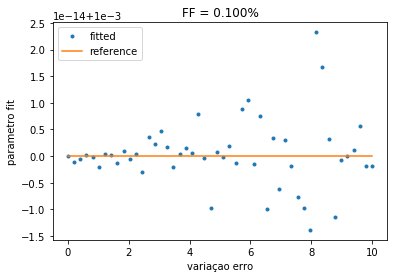

rho_fat = 0.112
rho_water = 9.888
rho_tot = 10.000
OK


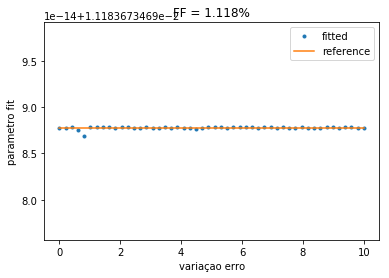

rho_fat = 0.214
rho_water = 9.786
rho_tot = 10.000
OK


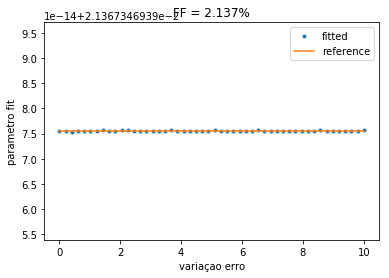

rho_fat = 0.316
rho_water = 9.684
rho_tot = 10.000
OK


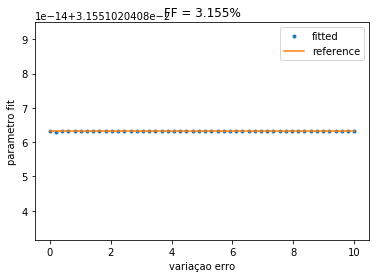

rho_fat = 0.417
rho_water = 9.583
rho_tot = 10.000
OK


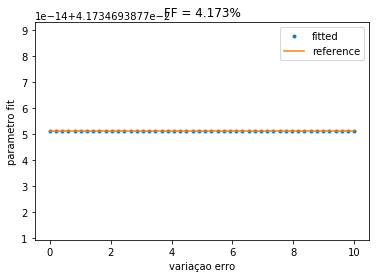

rho_fat = 0.519
rho_water = 9.481
rho_tot = 10.000
OK


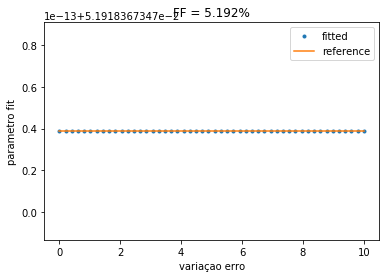

rho_fat = 0.621
rho_water = 9.379
rho_tot = 10.000
OK


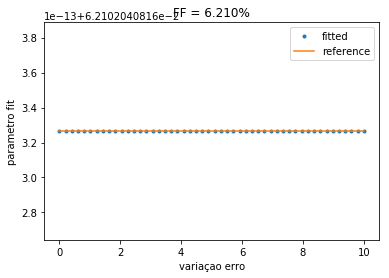

rho_fat = 0.723
rho_water = 9.277
rho_tot = 10.000
OK


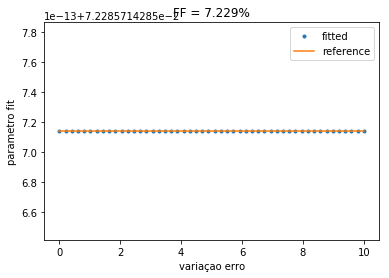

rho_fat = 0.825
rho_water = 9.175
rho_tot = 10.000
OK


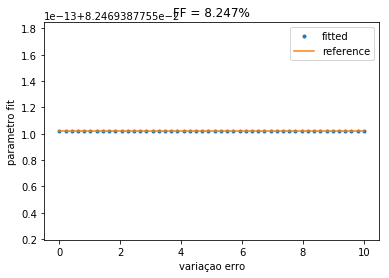

rho_fat = 0.927
rho_water = 9.073
rho_tot = 10.000
OK


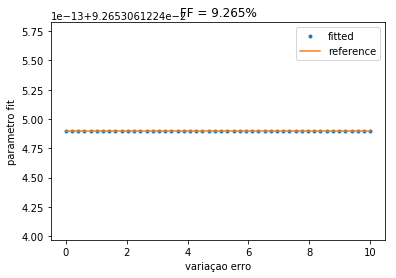

rho_fat = 1.028
rho_water = 8.972
rho_tot = 10.000
OK


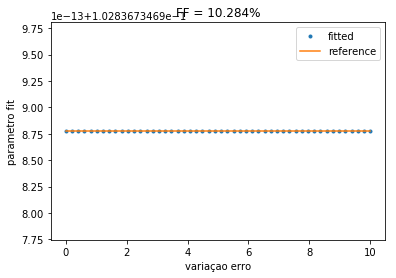

rho_fat = 1.130
rho_water = 8.870
rho_tot = 10.000
OK


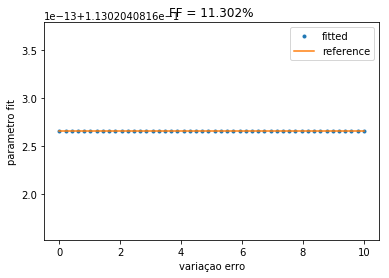

rho_fat = 1.232
rho_water = 8.768
rho_tot = 10.000
OK


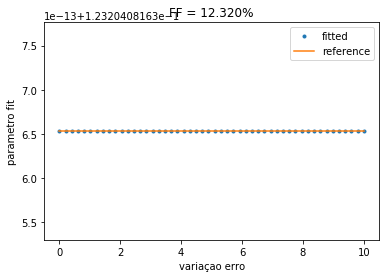

rho_fat = 1.334
rho_water = 8.666
rho_tot = 10.000
OK


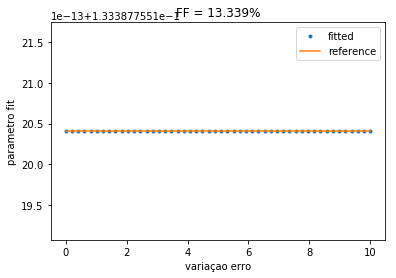

rho_fat = 1.436
rho_water = 8.564
rho_tot = 10.000
OK


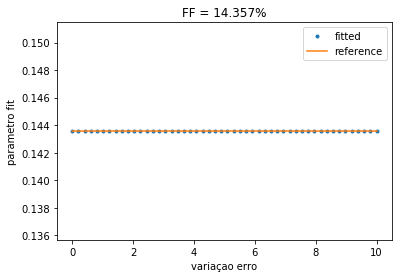

rho_fat = 1.538
rho_water = 8.462
rho_tot = 10.000
OK


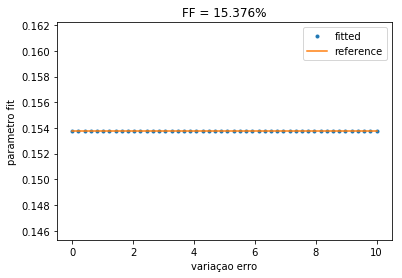

rho_fat = 1.639
rho_water = 8.361
rho_tot = 10.000
OK


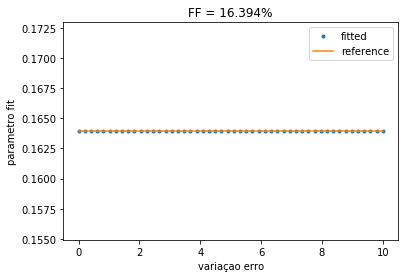

rho_fat = 1.741
rho_water = 8.259
rho_tot = 10.000
OK


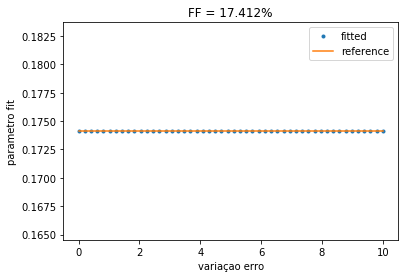

rho_fat = 1.843
rho_water = 8.157
rho_tot = 10.000
OK


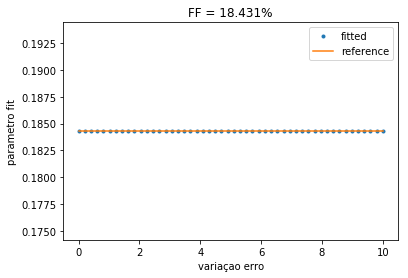

rho_fat = 1.945
rho_water = 8.055
rho_tot = 10.000
OK


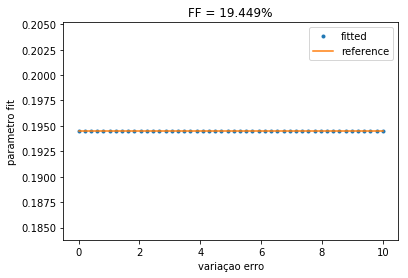

rho_fat = 2.047
rho_water = 7.953
rho_tot = 10.000
OK


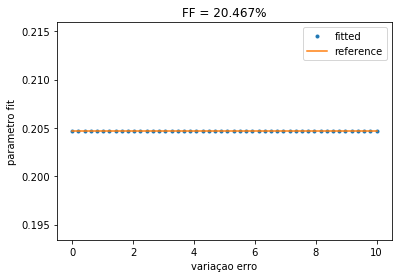

rho_fat = 2.149
rho_water = 7.851
rho_tot = 10.000
OK


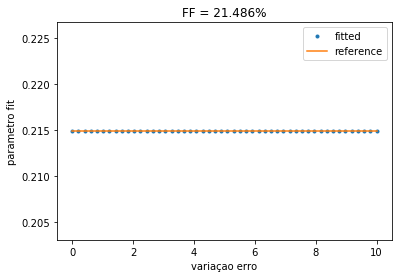

rho_fat = 2.250
rho_water = 7.750
rho_tot = 10.000
OK


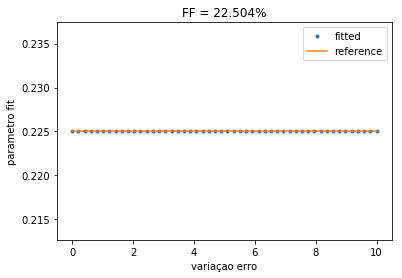

rho_fat = 2.352
rho_water = 7.648
rho_tot = 10.000
OK


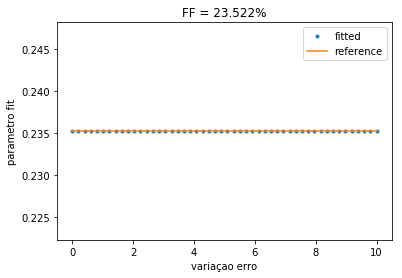

rho_fat = 2.454
rho_water = 7.546
rho_tot = 10.000
OK


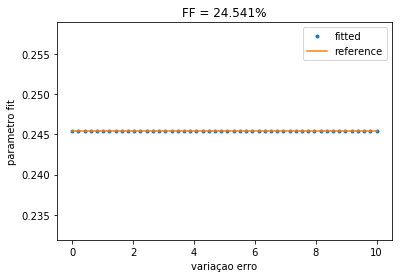

rho_fat = 2.556
rho_water = 7.444
rho_tot = 10.000
OK


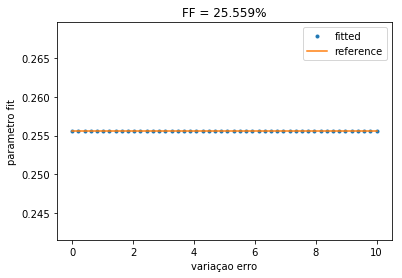

rho_fat = 2.658
rho_water = 7.342
rho_tot = 10.000
OK


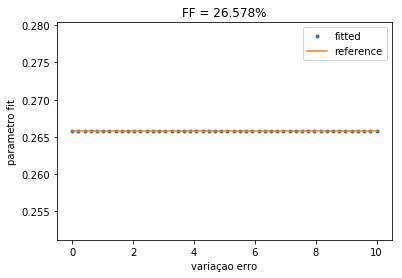

rho_fat = 2.760
rho_water = 7.240
rho_tot = 10.000
OK


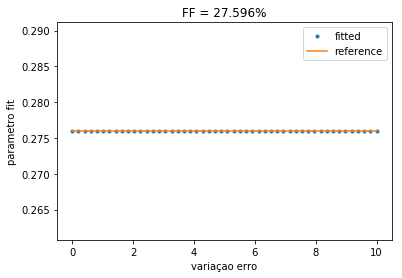

rho_fat = 2.861
rho_water = 7.139
rho_tot = 10.000
OK


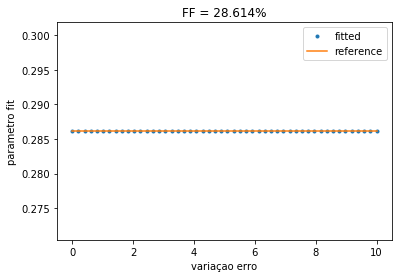

rho_fat = 2.963
rho_water = 7.037
rho_tot = 10.000
OK


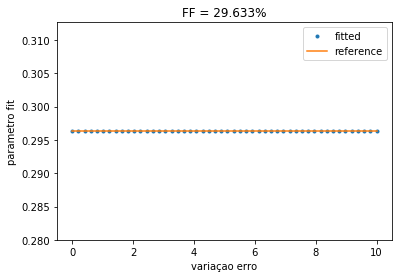

rho_fat = 3.065
rho_water = 6.935
rho_tot = 10.000
OK


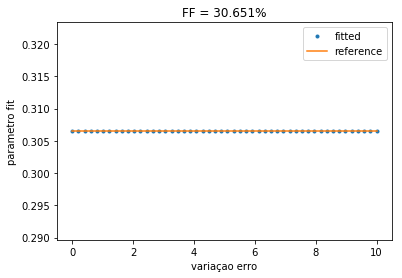

rho_fat = 3.167
rho_water = 6.833
rho_tot = 10.000
OK


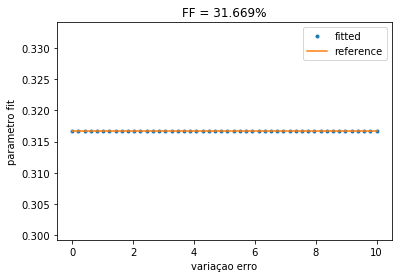

rho_fat = 3.269
rho_water = 6.731
rho_tot = 10.000
OK


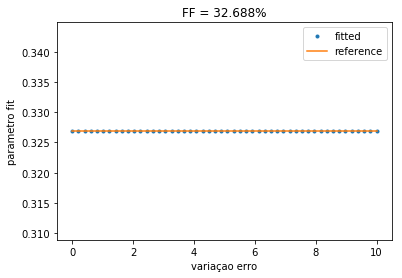

rho_fat = 3.371
rho_water = 6.629
rho_tot = 10.000
OK


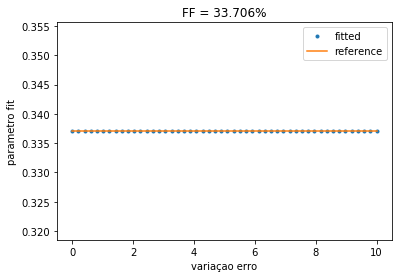

rho_fat = 3.472
rho_water = 6.528
rho_tot = 10.000
OK


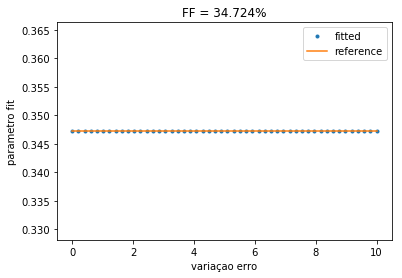

rho_fat = 3.574
rho_water = 6.426
rho_tot = 10.000
OK


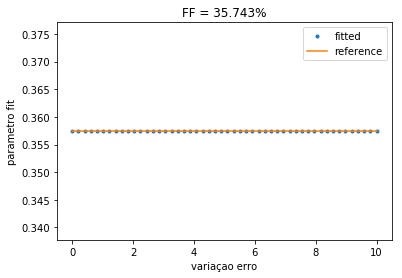

rho_fat = 3.676
rho_water = 6.324
rho_tot = 10.000
OK


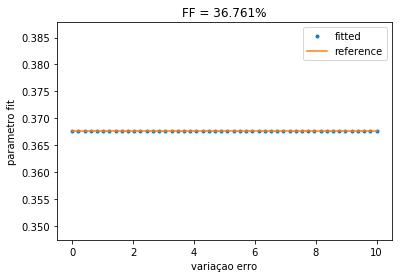

rho_fat = 3.778
rho_water = 6.222
rho_tot = 10.000
OK


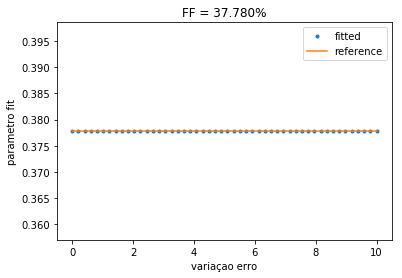

rho_fat = 3.880
rho_water = 6.120
rho_tot = 10.000
OK


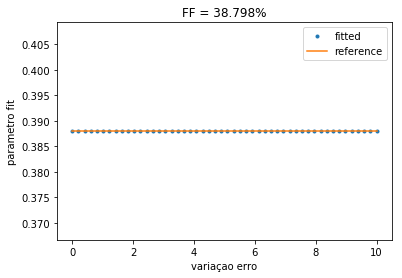

rho_fat = 3.982
rho_water = 6.018
rho_tot = 10.000
OK


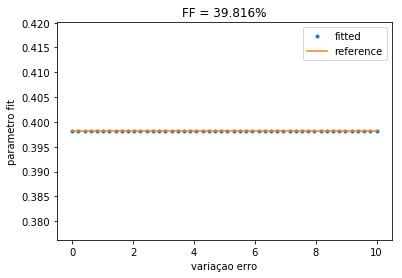

rho_fat = 4.083
rho_water = 5.917
rho_tot = 10.000
OK


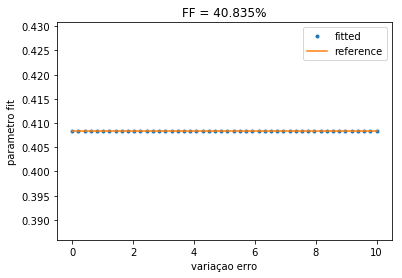

rho_fat = 4.185
rho_water = 5.815
rho_tot = 10.000
OK


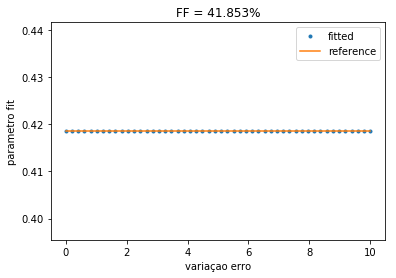

rho_fat = 4.287
rho_water = 5.713
rho_tot = 10.000
OK


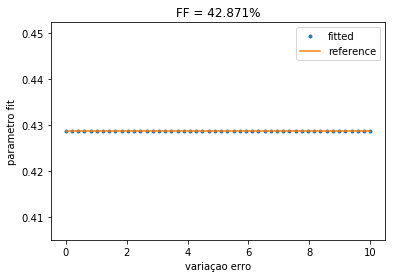

rho_fat = 4.389
rho_water = 5.611
rho_tot = 10.000
OK


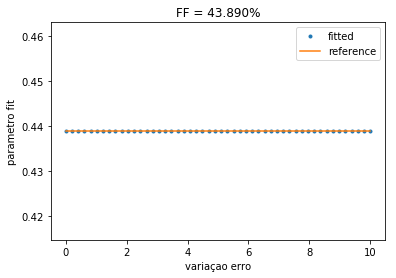

rho_fat = 4.491
rho_water = 5.509
rho_tot = 10.000
OK


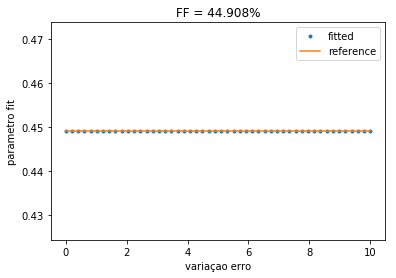

rho_fat = 4.593
rho_water = 5.407
rho_tot = 10.000
OK


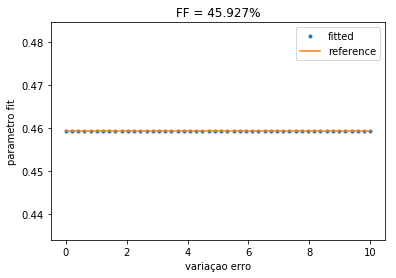

rho_fat = 4.694
rho_water = 5.306
rho_tot = 10.000
OK


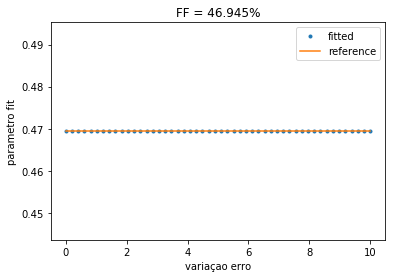

rho_fat = 4.796
rho_water = 5.204
rho_tot = 10.000
OK


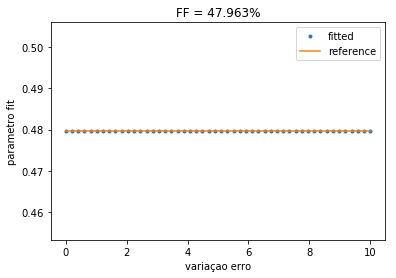

rho_fat = 4.898
rho_water = 5.102
rho_tot = 10.000
OK


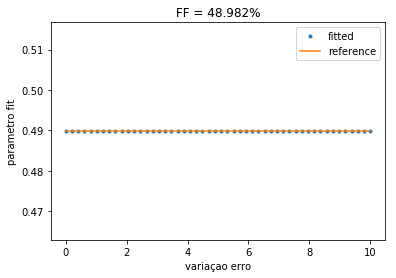

rho_fat = 5.000
rho_water = 5.000
rho_tot = 10.000
OK


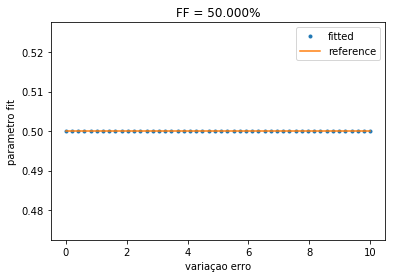

In [9]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 10                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat, rho_water+erro] # WATER + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(calc_fatfrac(fitted_par))
    
    ref10 = np.zeros(np.size(fitted10))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted10, '.', label='fitted')
    plt.plot(init_guess_var, ref10, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

rho_fat = 0.100
rho_water = 99.900
rho_tot = 100.000
OK


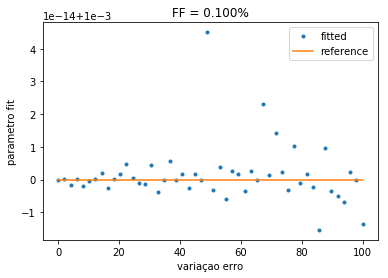

rho_fat = 1.118
rho_water = 98.882
rho_tot = 100.000
OK


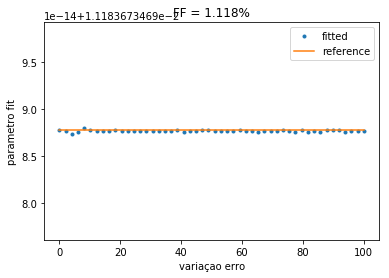

rho_fat = 2.137
rho_water = 97.863
rho_tot = 100.000
OK


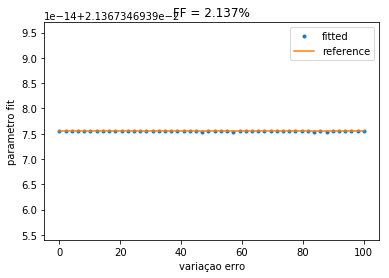

rho_fat = 3.155
rho_water = 96.845
rho_tot = 100.000
OK


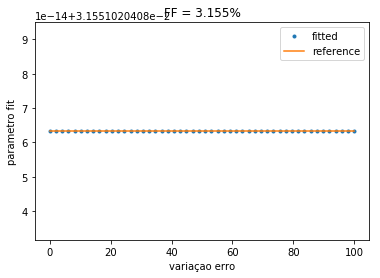

rho_fat = 4.173
rho_water = 95.827
rho_tot = 100.000
OK


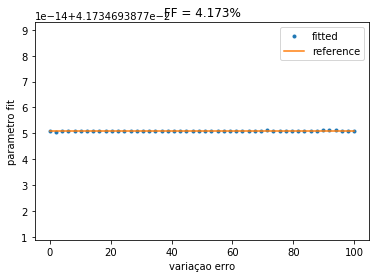

rho_fat = 5.192
rho_water = 94.808
rho_tot = 100.000
OK


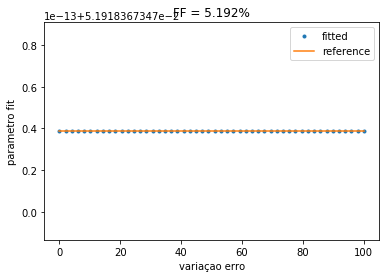

rho_fat = 6.210
rho_water = 93.790
rho_tot = 100.000
OK


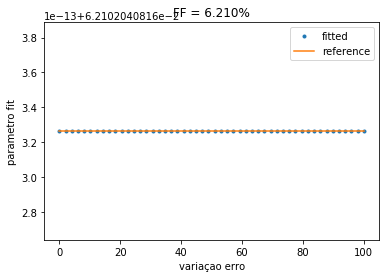

rho_fat = 7.229
rho_water = 92.771
rho_tot = 100.000
OK


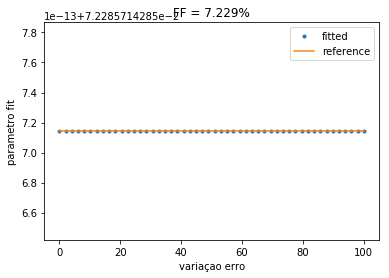

rho_fat = 8.247
rho_water = 91.753
rho_tot = 100.000
OK


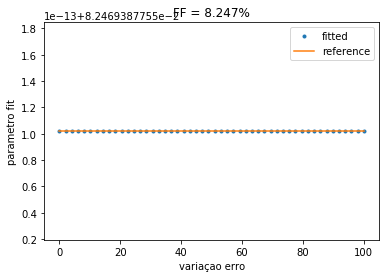

rho_fat = 9.265
rho_water = 90.735
rho_tot = 100.000
OK


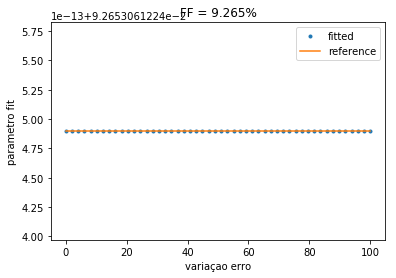

rho_fat = 10.284
rho_water = 89.716
rho_tot = 100.000
OK


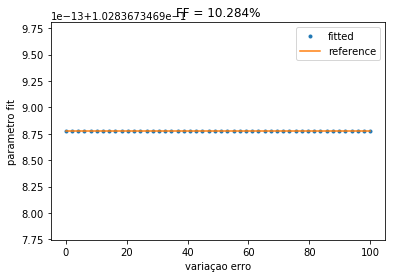

rho_fat = 11.302
rho_water = 88.698
rho_tot = 100.000
OK


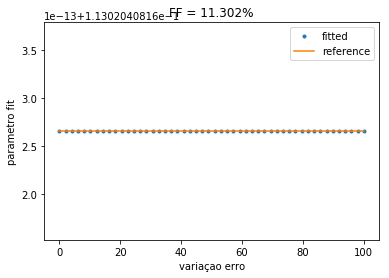

rho_fat = 12.320
rho_water = 87.680
rho_tot = 100.000
OK


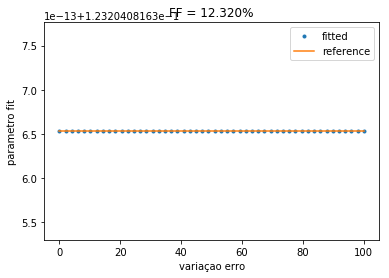

rho_fat = 13.339
rho_water = 86.661
rho_tot = 100.000
OK


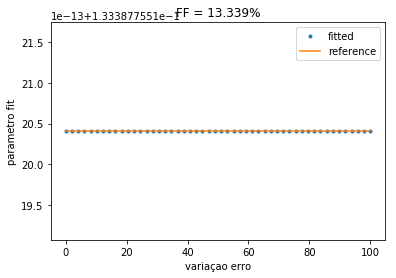

rho_fat = 14.357
rho_water = 85.643
rho_tot = 100.000
OK


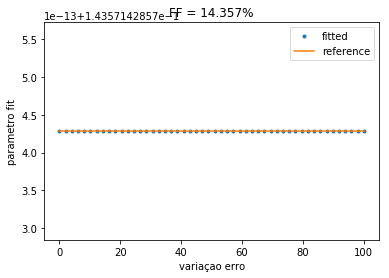

rho_fat = 15.376
rho_water = 84.624
rho_tot = 100.000
OK


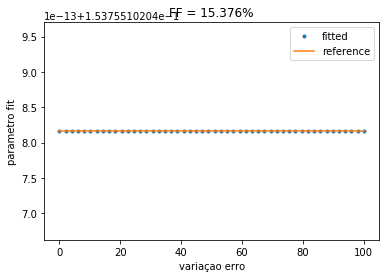

rho_fat = 16.394
rho_water = 83.606
rho_tot = 100.000
OK


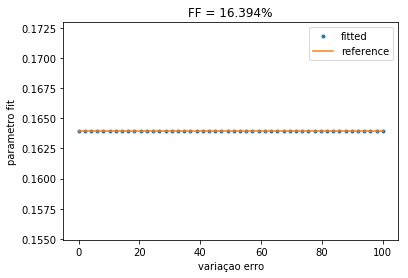

rho_fat = 17.412
rho_water = 82.588
rho_tot = 100.000
OK


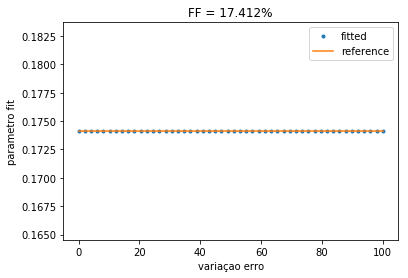

rho_fat = 18.431
rho_water = 81.569
rho_tot = 100.000
OK


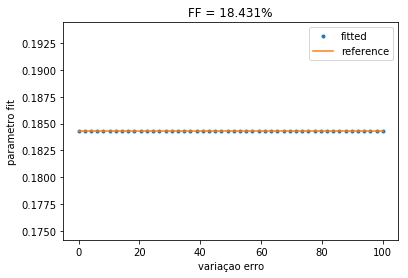

rho_fat = 19.449
rho_water = 80.551
rho_tot = 100.000
OK


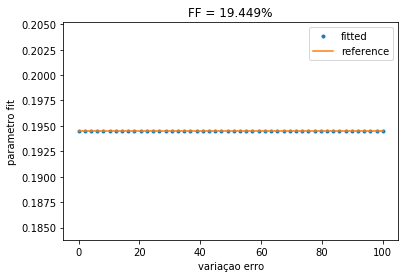

rho_fat = 20.467
rho_water = 79.533
rho_tot = 100.000
OK


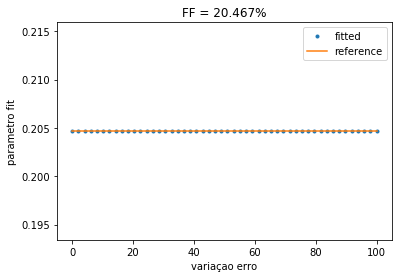

rho_fat = 21.486
rho_water = 78.514
rho_tot = 100.000
OK


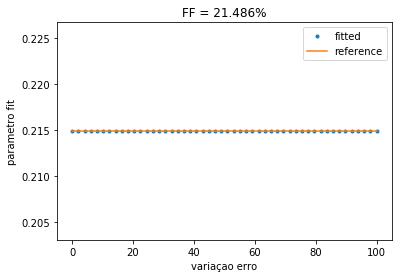

rho_fat = 22.504
rho_water = 77.496
rho_tot = 100.000
OK


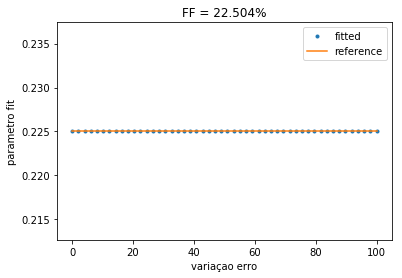

rho_fat = 23.522
rho_water = 76.478
rho_tot = 100.000
OK


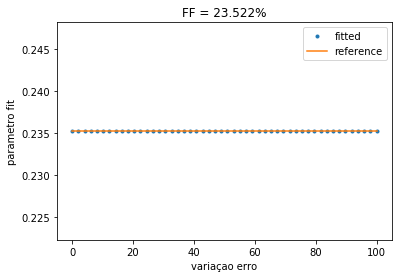

rho_fat = 24.541
rho_water = 75.459
rho_tot = 100.000
OK


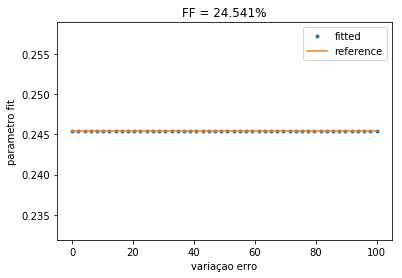

rho_fat = 25.559
rho_water = 74.441
rho_tot = 100.000
OK


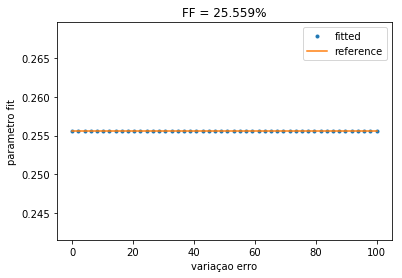

rho_fat = 26.578
rho_water = 73.422
rho_tot = 100.000
OK


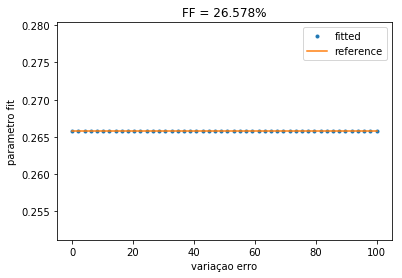

rho_fat = 27.596
rho_water = 72.404
rho_tot = 100.000
OK


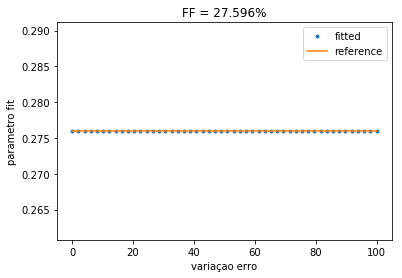

rho_fat = 28.614
rho_water = 71.386
rho_tot = 100.000
OK


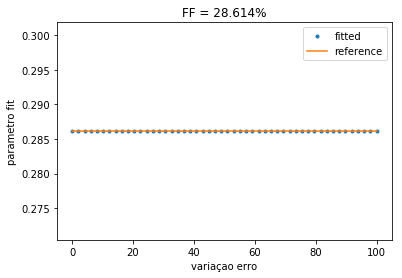

rho_fat = 29.633
rho_water = 70.367
rho_tot = 100.000
OK


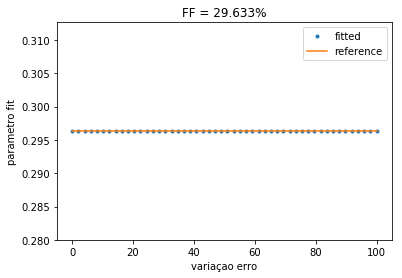

rho_fat = 30.651
rho_water = 69.349
rho_tot = 100.000
OK


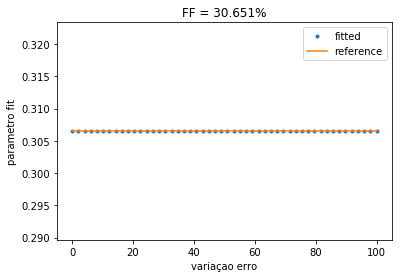

rho_fat = 31.669
rho_water = 68.331
rho_tot = 100.000
OK


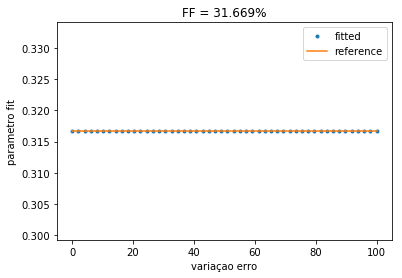

rho_fat = 32.688
rho_water = 67.312
rho_tot = 100.000
OK


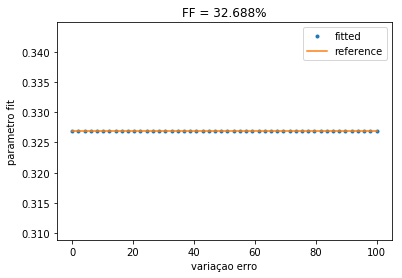

rho_fat = 33.706
rho_water = 66.294
rho_tot = 100.000
OK


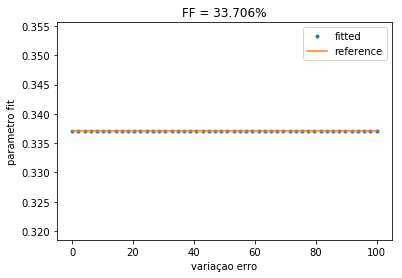

rho_fat = 34.724
rho_water = 65.276
rho_tot = 100.000
OK


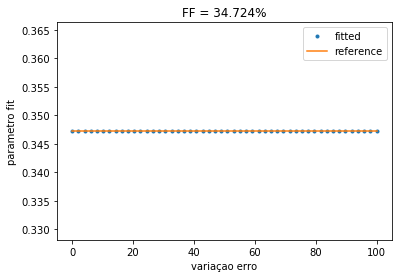

rho_fat = 35.743
rho_water = 64.257
rho_tot = 100.000
OK


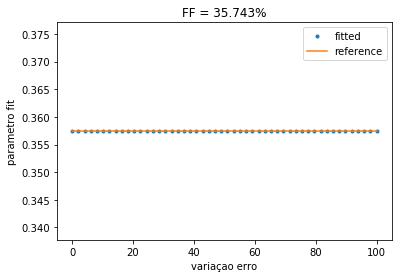

rho_fat = 36.761
rho_water = 63.239
rho_tot = 100.000
OK


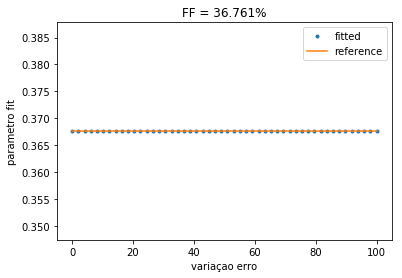

rho_fat = 37.780
rho_water = 62.220
rho_tot = 100.000
OK


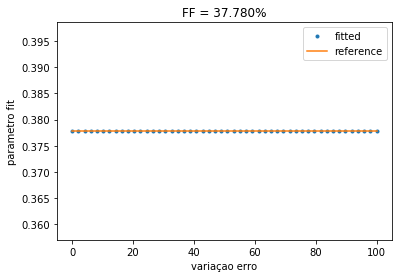

rho_fat = 38.798
rho_water = 61.202
rho_tot = 100.000
OK


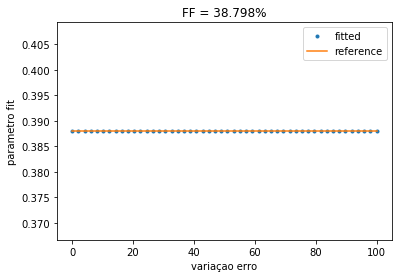

rho_fat = 39.816
rho_water = 60.184
rho_tot = 100.000
OK


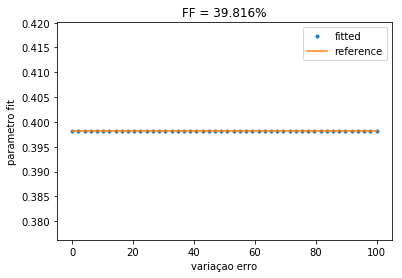

rho_fat = 40.835
rho_water = 59.165
rho_tot = 100.000
OK


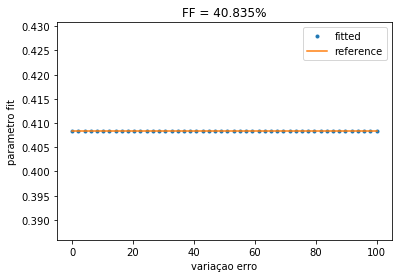

rho_fat = 41.853
rho_water = 58.147
rho_tot = 100.000
OK


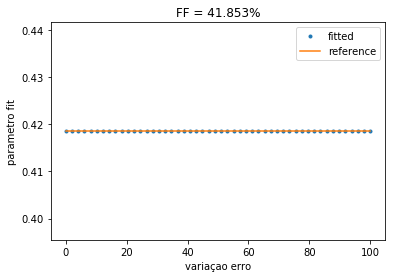

rho_fat = 42.871
rho_water = 57.129
rho_tot = 100.000
OK


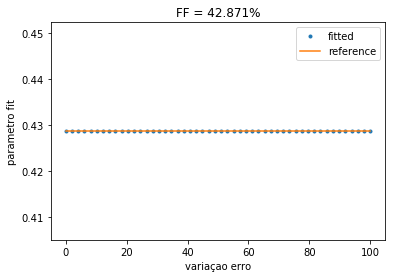

rho_fat = 43.890
rho_water = 56.110
rho_tot = 100.000
OK


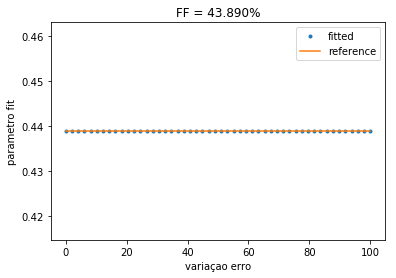

rho_fat = 44.908
rho_water = 55.092
rho_tot = 100.000
OK


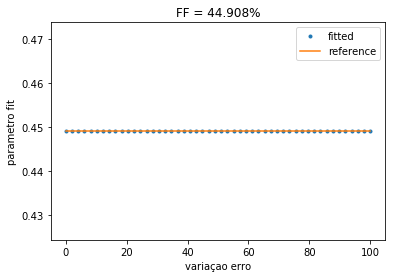

rho_fat = 45.927
rho_water = 54.073
rho_tot = 100.000
OK


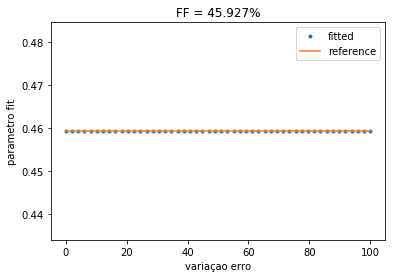

rho_fat = 46.945
rho_water = 53.055
rho_tot = 100.000
OK


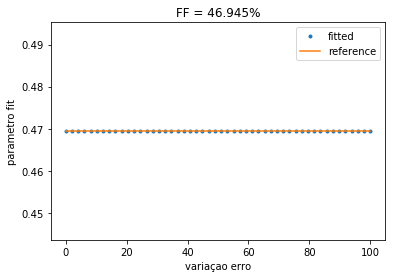

rho_fat = 47.963
rho_water = 52.037
rho_tot = 100.000
OK


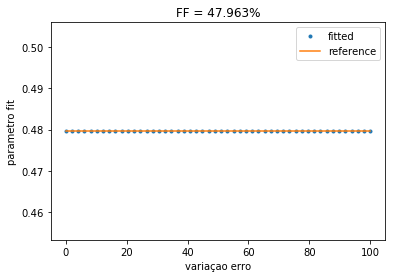

rho_fat = 48.982
rho_water = 51.018
rho_tot = 100.000
OK


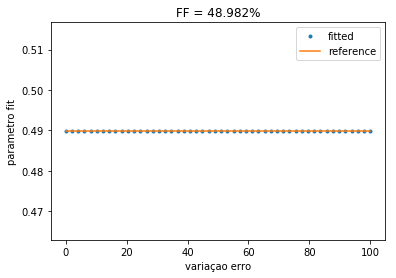

rho_fat = 50.000
rho_water = 50.000
rho_tot = 100.000
OK


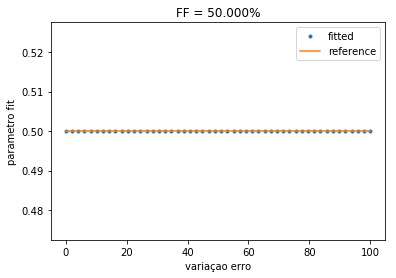

In [10]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 100                # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted100 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat, rho_water+erro] # WATER + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted100.append(calc_fatfrac(fitted_par))
    
    ref100 = np.zeros(np.size(fitted100))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted100, '.', label='fitted')
    plt.plot(init_guess_var, ref100, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

rho_fat = 1.000
rho_water = 999.000
rho_tot = 1000.000
OK


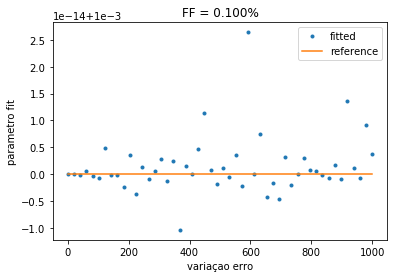

rho_fat = 11.184
rho_water = 988.816
rho_tot = 1000.000
OK


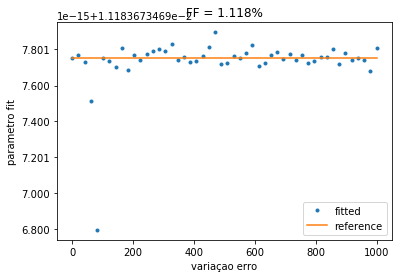

rho_fat = 21.367
rho_water = 978.633
rho_tot = 1000.000
OK


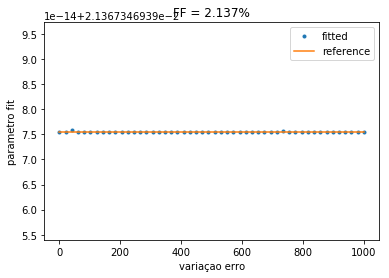

rho_fat = 31.551
rho_water = 968.449
rho_tot = 1000.000
OK


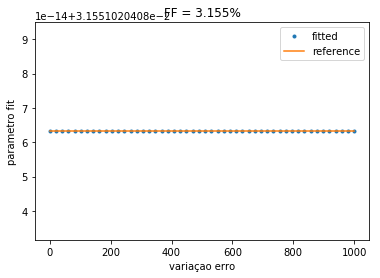

rho_fat = 41.735
rho_water = 958.265
rho_tot = 1000.000
OK


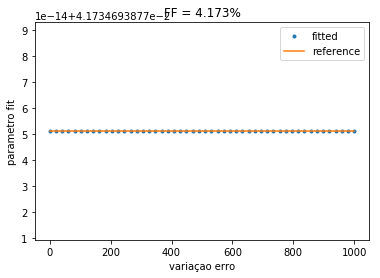

rho_fat = 51.918
rho_water = 948.082
rho_tot = 1000.000
OK


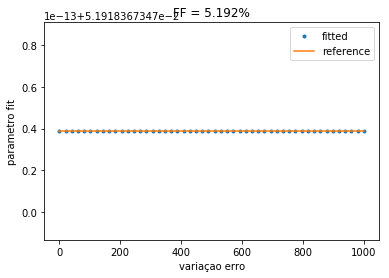

rho_fat = 62.102
rho_water = 937.898
rho_tot = 1000.000
OK


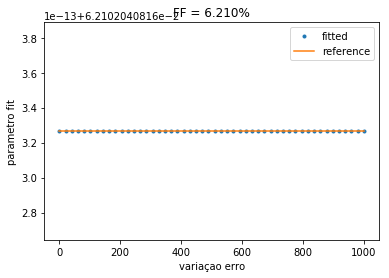

rho_fat = 72.286
rho_water = 927.714
rho_tot = 1000.000
OK


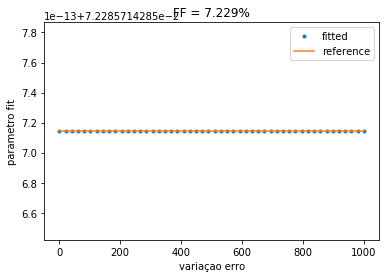

rho_fat = 82.469
rho_water = 917.531
rho_tot = 1000.000
OK


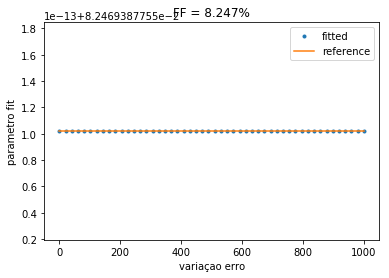

rho_fat = 92.653
rho_water = 907.347
rho_tot = 1000.000
OK


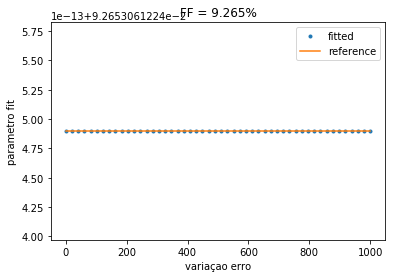

rho_fat = 102.837
rho_water = 897.163
rho_tot = 1000.000
OK


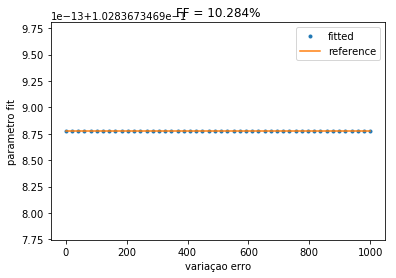

rho_fat = 113.020
rho_water = 886.980
rho_tot = 1000.000
OK


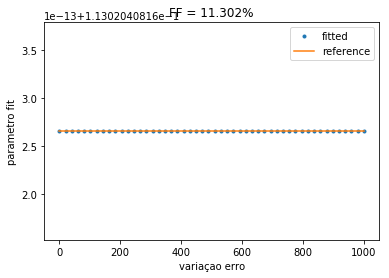

rho_fat = 123.204
rho_water = 876.796
rho_tot = 1000.000
OK


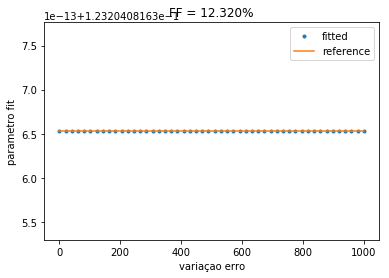

rho_fat = 133.388
rho_water = 866.612
rho_tot = 1000.000
OK


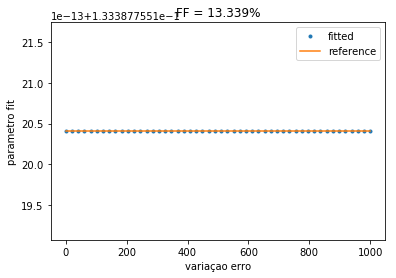

rho_fat = 143.571
rho_water = 856.429
rho_tot = 1000.000
OK


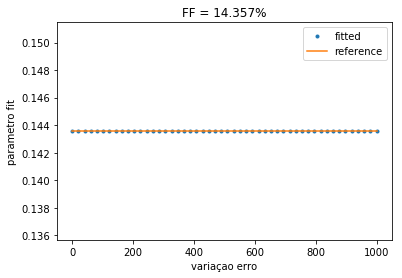

rho_fat = 153.755
rho_water = 846.245
rho_tot = 1000.000
OK


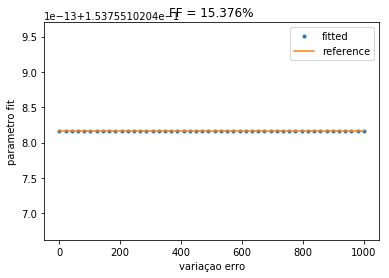

rho_fat = 163.939
rho_water = 836.061
rho_tot = 1000.000
OK


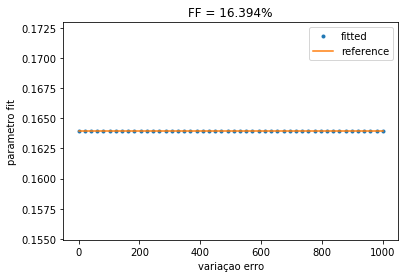

rho_fat = 174.122
rho_water = 825.878
rho_tot = 1000.000
OK


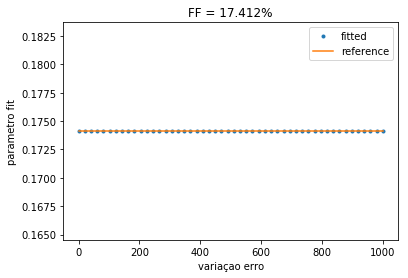

rho_fat = 184.306
rho_water = 815.694
rho_tot = 1000.000
OK


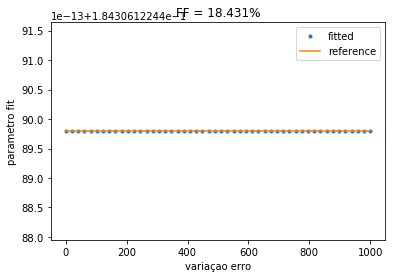

rho_fat = 194.490
rho_water = 805.510
rho_tot = 1000.000
OK


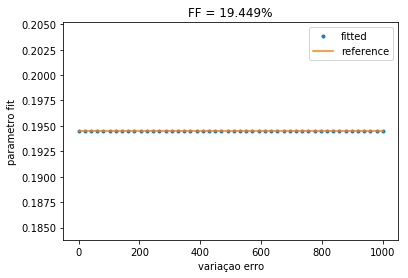

rho_fat = 204.673
rho_water = 795.327
rho_tot = 1000.000
OK


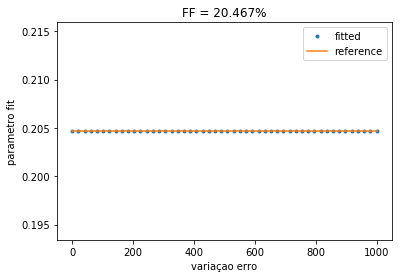

rho_fat = 214.857
rho_water = 785.143
rho_tot = 1000.000
OK


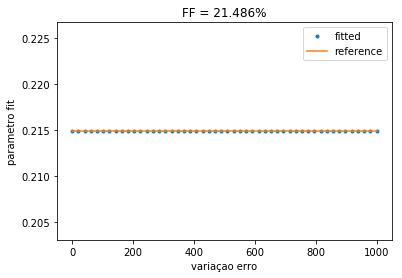

rho_fat = 225.041
rho_water = 774.959
rho_tot = 1000.000
OK


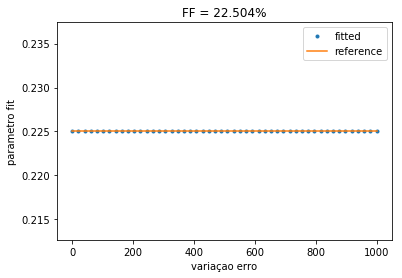

rho_fat = 235.224
rho_water = 764.776
rho_tot = 1000.000
OK


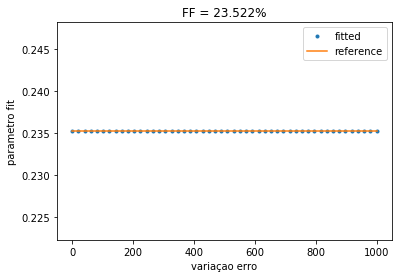

rho_fat = 245.408
rho_water = 754.592
rho_tot = 1000.000
OK


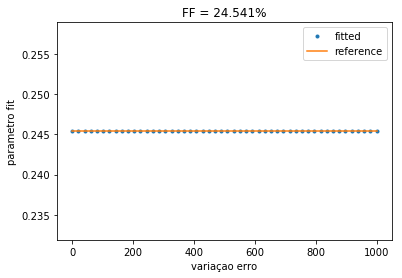

rho_fat = 255.592
rho_water = 744.408
rho_tot = 1000.000
OK


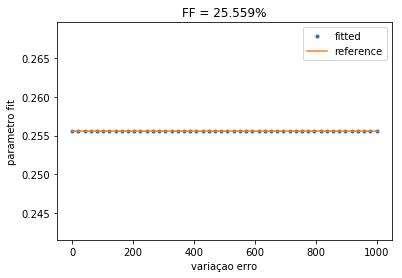

rho_fat = 265.776
rho_water = 734.224
rho_tot = 1000.000
OK


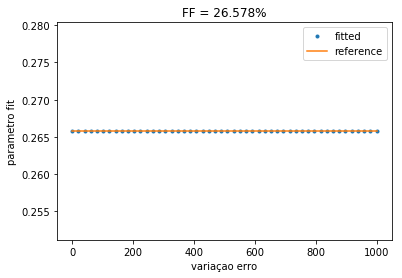

rho_fat = 275.959
rho_water = 724.041
rho_tot = 1000.000
OK


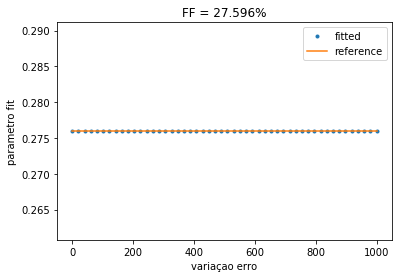

rho_fat = 286.143
rho_water = 713.857
rho_tot = 1000.000
OK


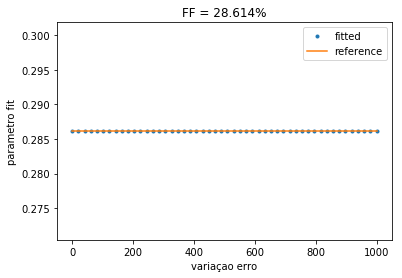

rho_fat = 296.327
rho_water = 703.673
rho_tot = 1000.000
OK


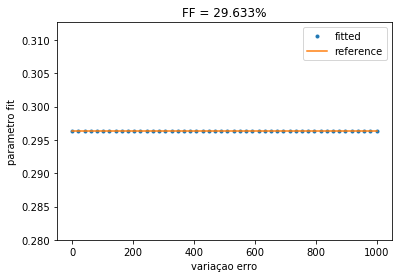

rho_fat = 306.510
rho_water = 693.490
rho_tot = 1000.000
OK


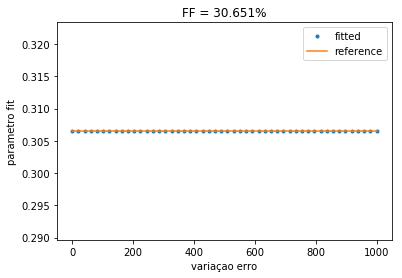

rho_fat = 316.694
rho_water = 683.306
rho_tot = 1000.000
OK


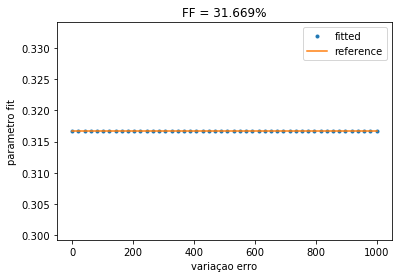

rho_fat = 326.878
rho_water = 673.122
rho_tot = 1000.000
OK


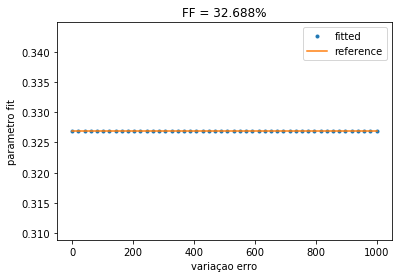

rho_fat = 337.061
rho_water = 662.939
rho_tot = 1000.000
OK


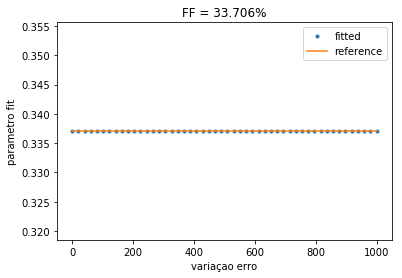

rho_fat = 347.245
rho_water = 652.755
rho_tot = 1000.000
OK


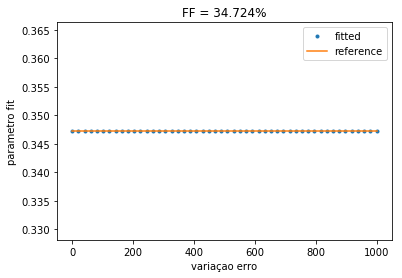

rho_fat = 357.429
rho_water = 642.571
rho_tot = 1000.000
OK


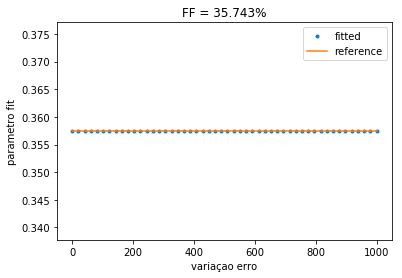

rho_fat = 367.612
rho_water = 632.388
rho_tot = 1000.000
OK


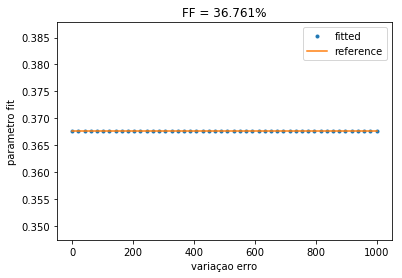

rho_fat = 377.796
rho_water = 622.204
rho_tot = 1000.000
OK


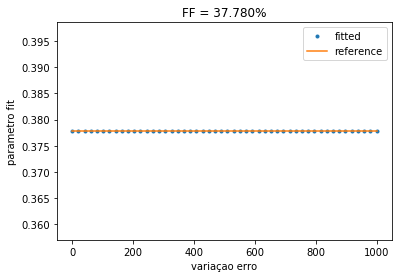

rho_fat = 387.980
rho_water = 612.020
rho_tot = 1000.000
OK


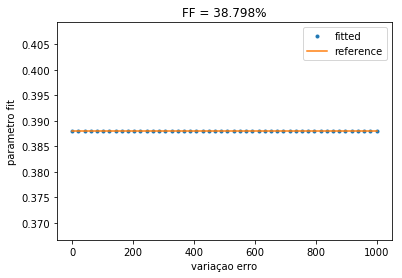

rho_fat = 398.163
rho_water = 601.837
rho_tot = 1000.000
OK


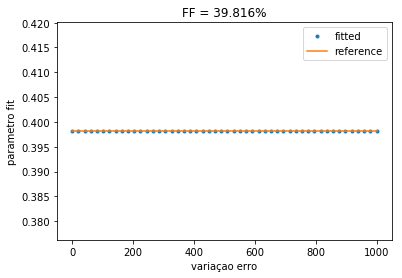

rho_fat = 408.347
rho_water = 591.653
rho_tot = 1000.000
OK


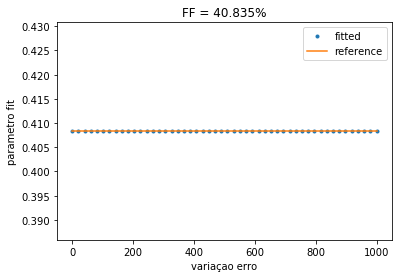

rho_fat = 418.531
rho_water = 581.469
rho_tot = 1000.000
OK


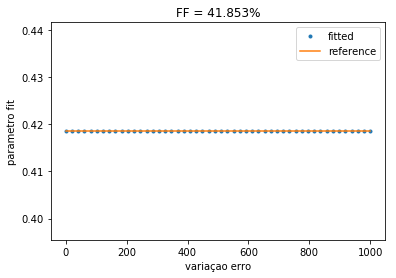

rho_fat = 428.714
rho_water = 571.286
rho_tot = 1000.000
OK


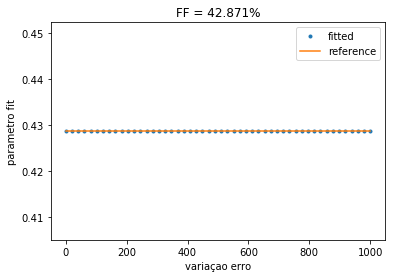

rho_fat = 438.898
rho_water = 561.102
rho_tot = 1000.000
OK


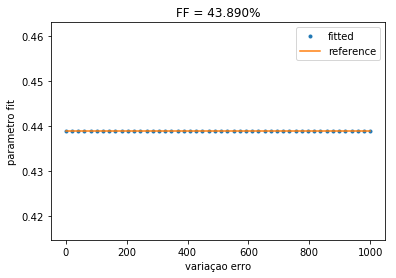

rho_fat = 449.082
rho_water = 550.918
rho_tot = 1000.000
OK


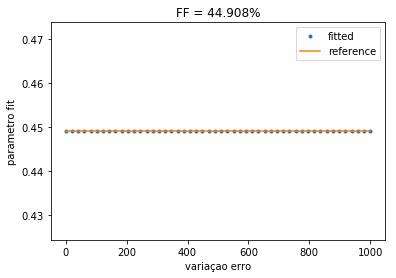

rho_fat = 459.265
rho_water = 540.735
rho_tot = 1000.000
OK


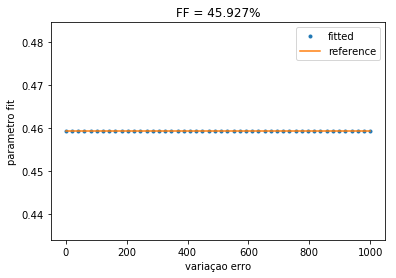

rho_fat = 469.449
rho_water = 530.551
rho_tot = 1000.000
OK


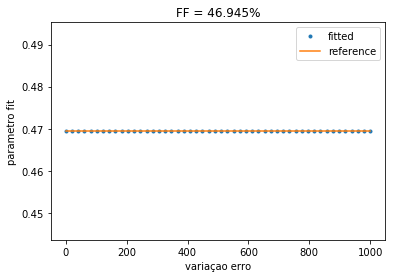

rho_fat = 479.633
rho_water = 520.367
rho_tot = 1000.000
OK


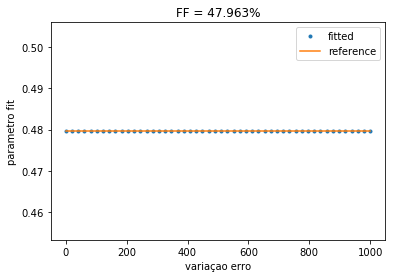

rho_fat = 489.816
rho_water = 510.184
rho_tot = 1000.000
OK


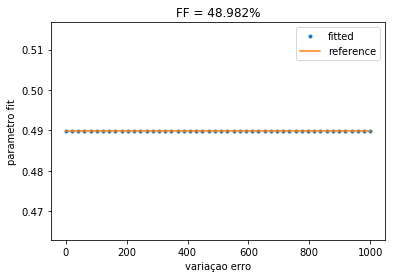

rho_fat = 500.000
rho_water = 500.000
rho_tot = 1000.000
OK


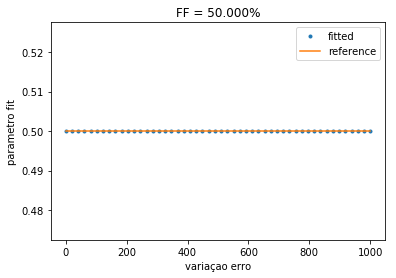

In [11]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 1000               # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted1000 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat, rho_water+erro] # WATER + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1000.append(calc_fatfrac(fitted_par))
    
    ref1000 = np.zeros(np.size(fitted1000))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted1000, '.', label='fitted')
    plt.plot(init_guess_var, ref1000, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

# Juntar os 3 rho_tot em graf ?

# Teste 3:
## Variando o valor inicial da água e da gordura

rho_fat = 0.010
rho_water = 9.990
rho_tot = 10.000
OK


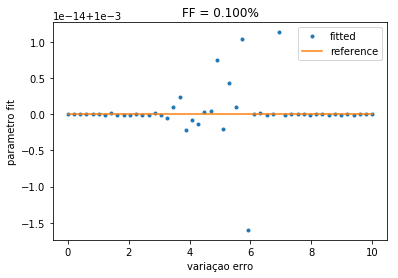

rho_fat = 0.112
rho_water = 9.888
rho_tot = 10.000
OK


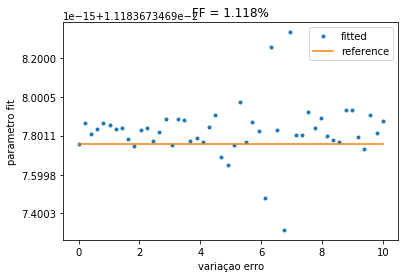

rho_fat = 0.214
rho_water = 9.786
rho_tot = 10.000
OK


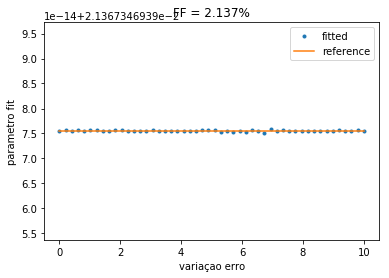

rho_fat = 0.316
rho_water = 9.684
rho_tot = 10.000
OK


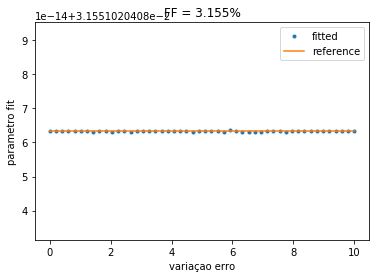

rho_fat = 0.417
rho_water = 9.583
rho_tot = 10.000
OK


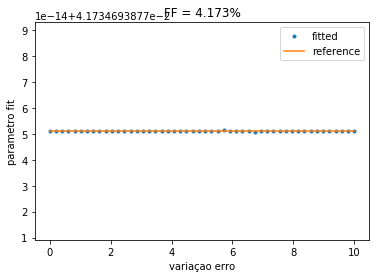

rho_fat = 0.519
rho_water = 9.481
rho_tot = 10.000
OK


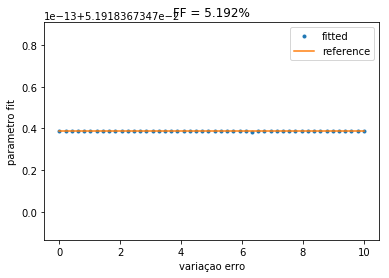

rho_fat = 0.621
rho_water = 9.379
rho_tot = 10.000
OK


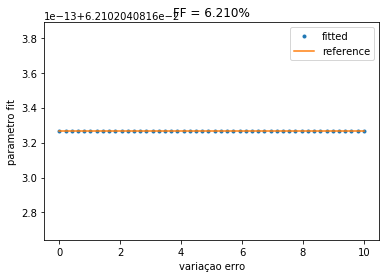

rho_fat = 0.723
rho_water = 9.277
rho_tot = 10.000
OK


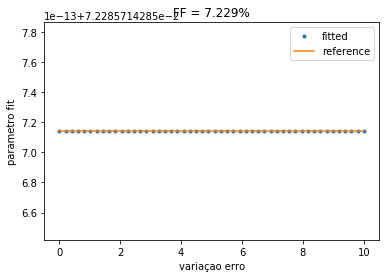

rho_fat = 0.825
rho_water = 9.175
rho_tot = 10.000
OK


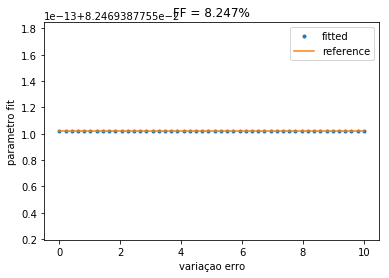

rho_fat = 0.927
rho_water = 9.073
rho_tot = 10.000
OK


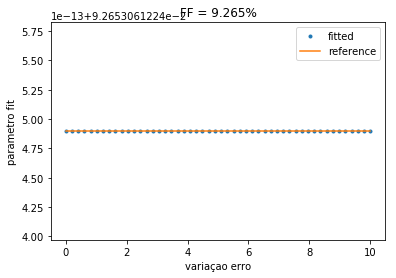

rho_fat = 1.028
rho_water = 8.972
rho_tot = 10.000
OK


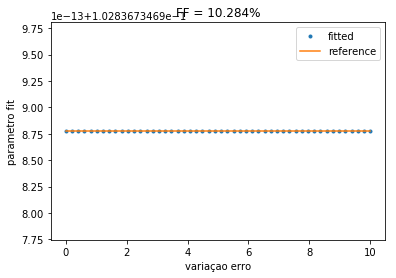

rho_fat = 1.130
rho_water = 8.870
rho_tot = 10.000
OK


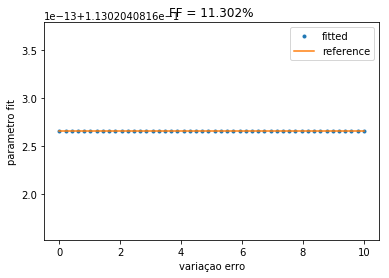

rho_fat = 1.232
rho_water = 8.768
rho_tot = 10.000
OK


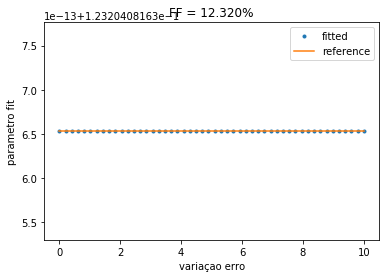

rho_fat = 1.334
rho_water = 8.666
rho_tot = 10.000
OK


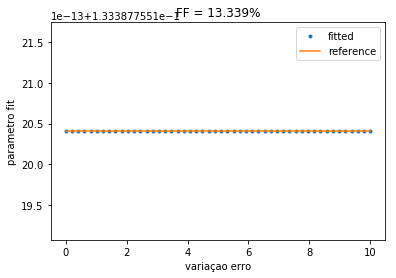

rho_fat = 1.436
rho_water = 8.564
rho_tot = 10.000
OK


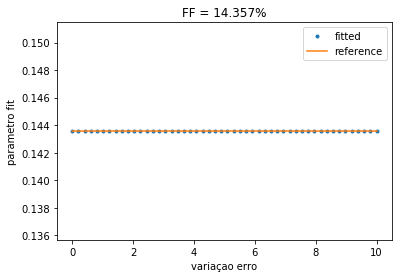

rho_fat = 1.538
rho_water = 8.462
rho_tot = 10.000
OK


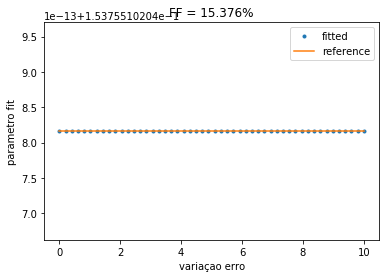

rho_fat = 1.639
rho_water = 8.361
rho_tot = 10.000
OK


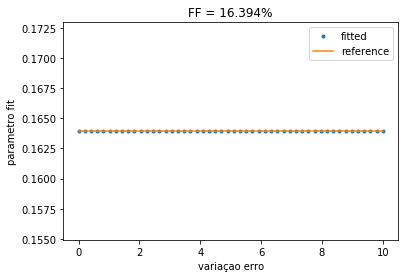

rho_fat = 1.741
rho_water = 8.259
rho_tot = 10.000
OK


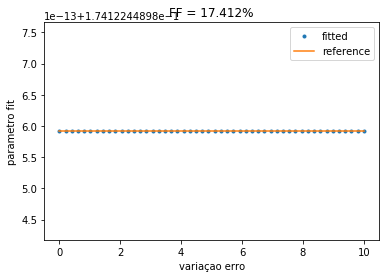

rho_fat = 1.843
rho_water = 8.157
rho_tot = 10.000
OK


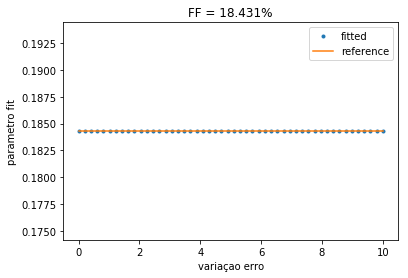

rho_fat = 1.945
rho_water = 8.055
rho_tot = 10.000
OK


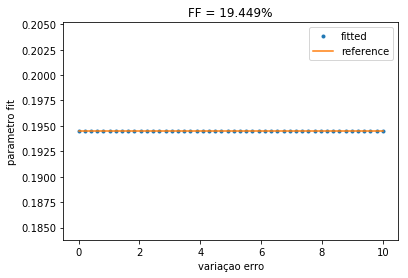

rho_fat = 2.047
rho_water = 7.953
rho_tot = 10.000
OK


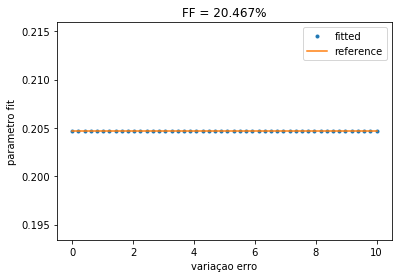

rho_fat = 2.149
rho_water = 7.851
rho_tot = 10.000
OK


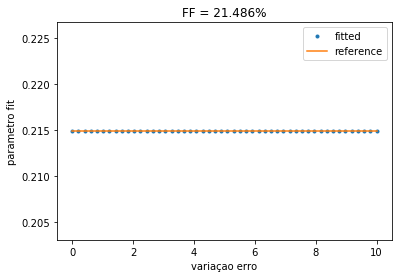

rho_fat = 2.250
rho_water = 7.750
rho_tot = 10.000
OK


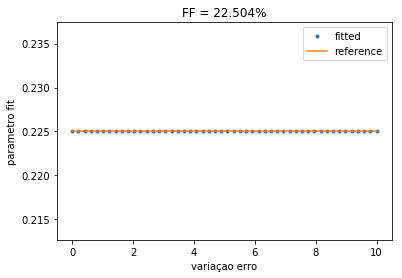

rho_fat = 2.352
rho_water = 7.648
rho_tot = 10.000
OK


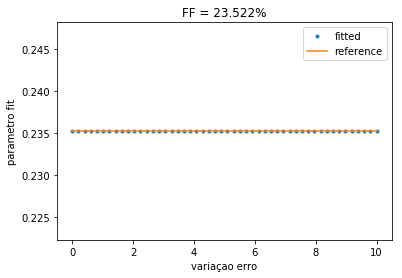

rho_fat = 2.454
rho_water = 7.546
rho_tot = 10.000
OK


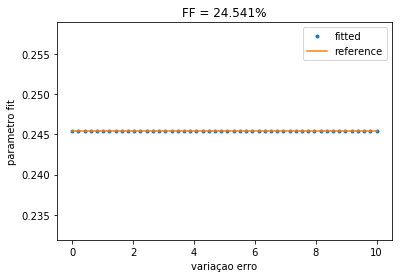

rho_fat = 2.556
rho_water = 7.444
rho_tot = 10.000
OK


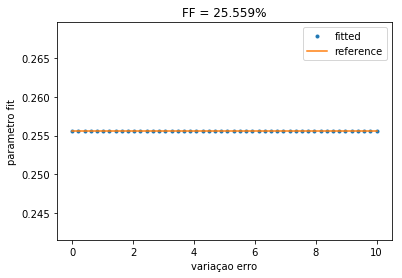

rho_fat = 2.658
rho_water = 7.342
rho_tot = 10.000
OK


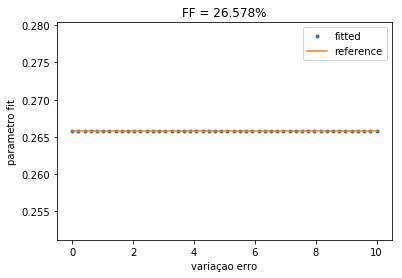

rho_fat = 2.760
rho_water = 7.240
rho_tot = 10.000
OK


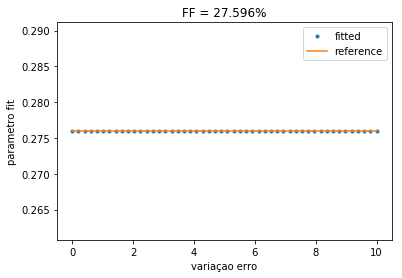

rho_fat = 2.861
rho_water = 7.139
rho_tot = 10.000
OK


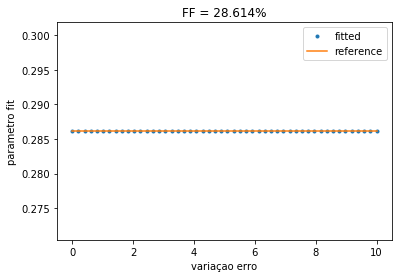

rho_fat = 2.963
rho_water = 7.037
rho_tot = 10.000
OK


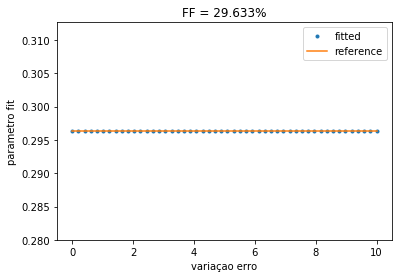

rho_fat = 3.065
rho_water = 6.935
rho_tot = 10.000
OK


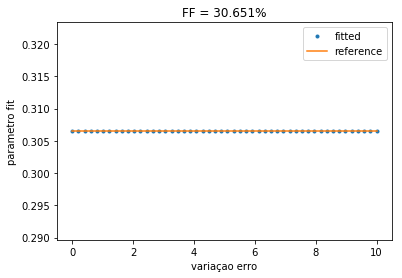

rho_fat = 3.167
rho_water = 6.833
rho_tot = 10.000
OK


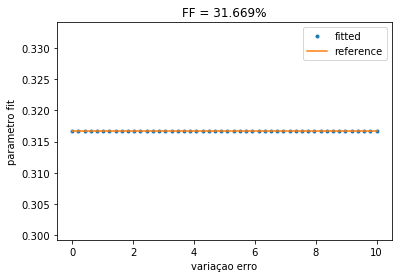

rho_fat = 3.269
rho_water = 6.731
rho_tot = 10.000
OK


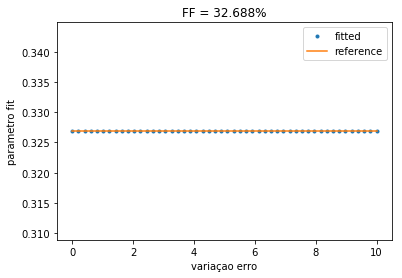

rho_fat = 3.371
rho_water = 6.629
rho_tot = 10.000
OK


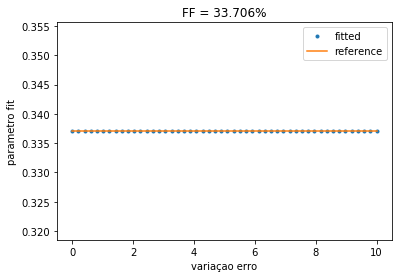

rho_fat = 3.472
rho_water = 6.528
rho_tot = 10.000
OK


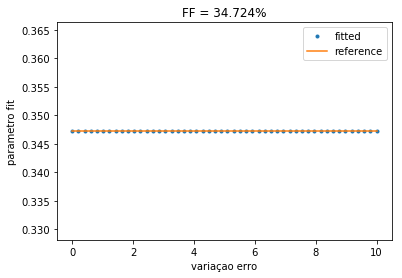

rho_fat = 3.574
rho_water = 6.426
rho_tot = 10.000
OK


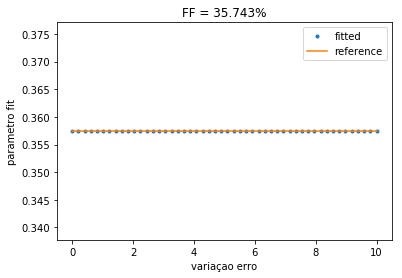

rho_fat = 3.676
rho_water = 6.324
rho_tot = 10.000
OK


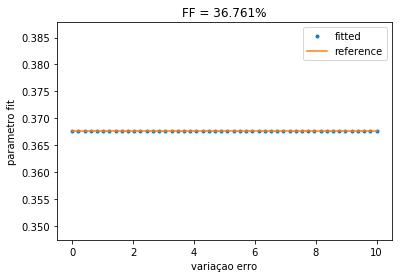

rho_fat = 3.778
rho_water = 6.222
rho_tot = 10.000
OK


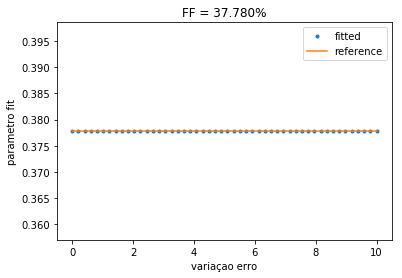

rho_fat = 3.880
rho_water = 6.120
rho_tot = 10.000
OK


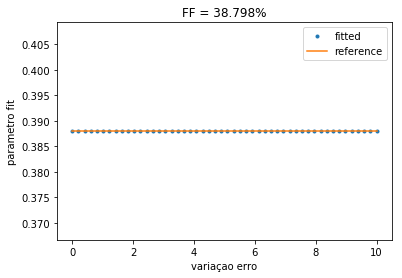

rho_fat = 3.982
rho_water = 6.018
rho_tot = 10.000
OK


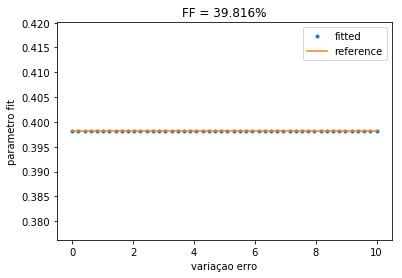

rho_fat = 4.083
rho_water = 5.917
rho_tot = 10.000
OK


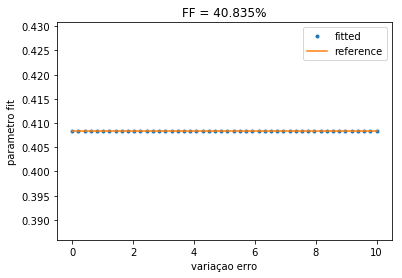

rho_fat = 4.185
rho_water = 5.815
rho_tot = 10.000
OK


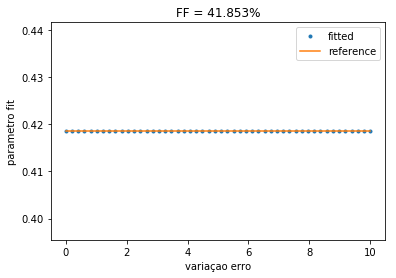

rho_fat = 4.287
rho_water = 5.713
rho_tot = 10.000
OK


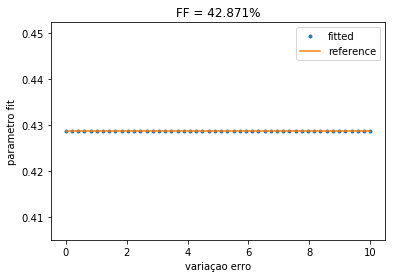

rho_fat = 4.389
rho_water = 5.611
rho_tot = 10.000
OK


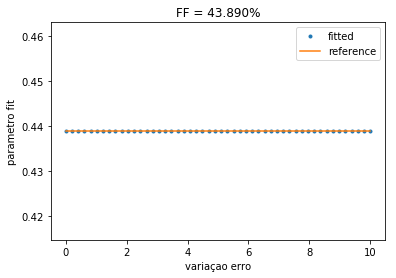

rho_fat = 4.491
rho_water = 5.509
rho_tot = 10.000
OK


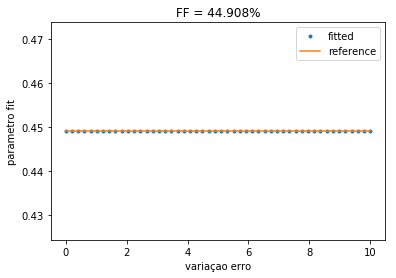

rho_fat = 4.593
rho_water = 5.407
rho_tot = 10.000
OK


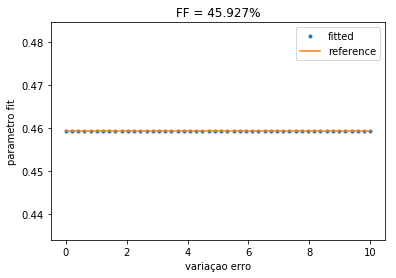

rho_fat = 4.694
rho_water = 5.306
rho_tot = 10.000
OK


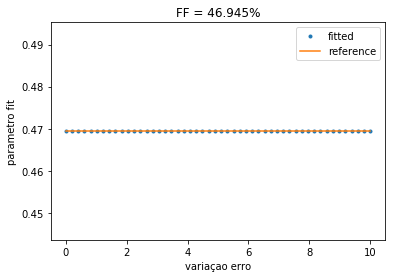

rho_fat = 4.796
rho_water = 5.204
rho_tot = 10.000
OK


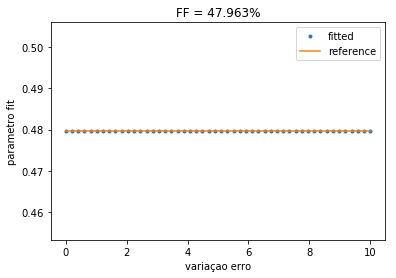

rho_fat = 4.898
rho_water = 5.102
rho_tot = 10.000
OK


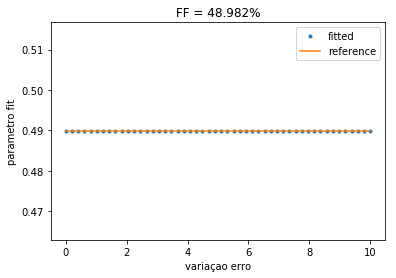

rho_fat = 5.000
rho_water = 5.000
rho_tot = 10.000
OK


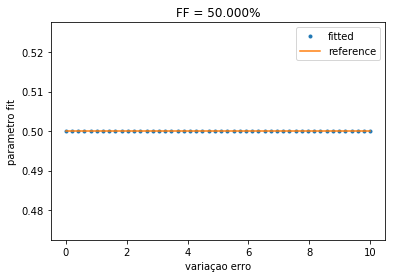

In [12]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 10                 # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted10 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water+erro] # (FAT,WATER) + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted10.append(calc_fatfrac(fitted_par))
    
    ref10 = np.zeros(np.size(fitted10))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted10, '.', label='fitted')
    plt.plot(init_guess_var, ref10, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

rho_fat = 0.100
rho_water = 99.900
rho_tot = 100.000
OK


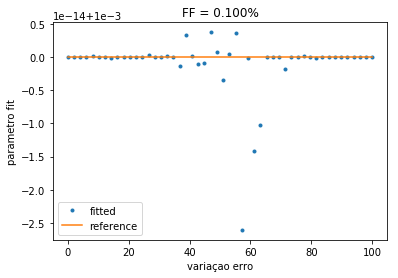

rho_fat = 1.118
rho_water = 98.882
rho_tot = 100.000
OK


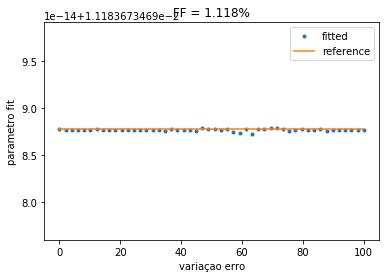

rho_fat = 2.137
rho_water = 97.863
rho_tot = 100.000
OK


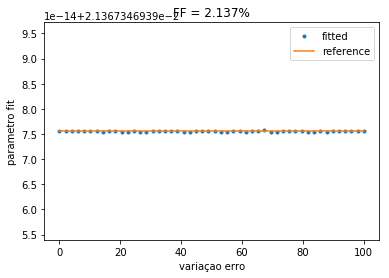

rho_fat = 3.155
rho_water = 96.845
rho_tot = 100.000
OK


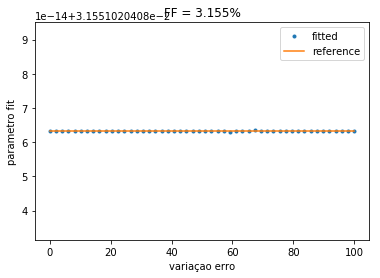

rho_fat = 4.173
rho_water = 95.827
rho_tot = 100.000
OK


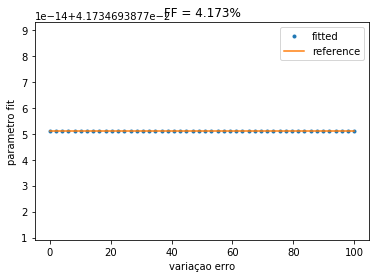

rho_fat = 5.192
rho_water = 94.808
rho_tot = 100.000
OK


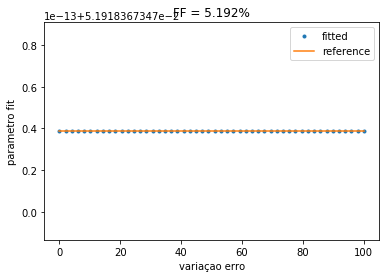

rho_fat = 6.210
rho_water = 93.790
rho_tot = 100.000
OK


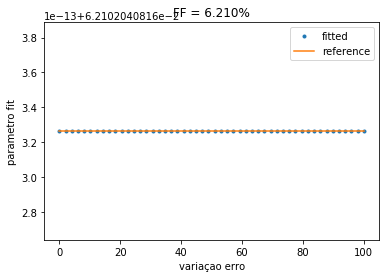

rho_fat = 7.229
rho_water = 92.771
rho_tot = 100.000
OK


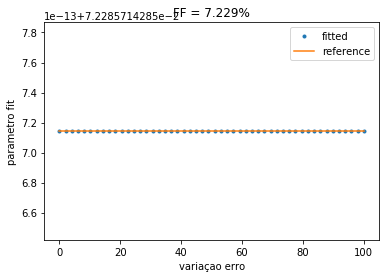

rho_fat = 8.247
rho_water = 91.753
rho_tot = 100.000
OK


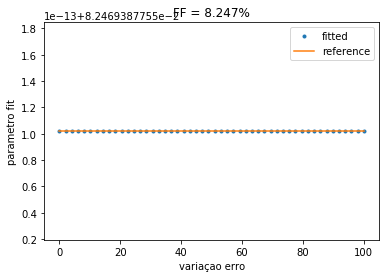

rho_fat = 9.265
rho_water = 90.735
rho_tot = 100.000
OK


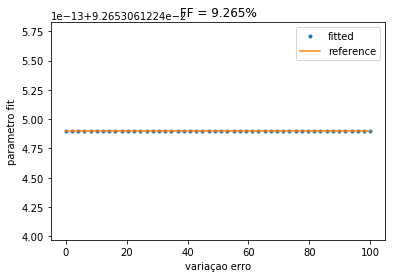

rho_fat = 10.284
rho_water = 89.716
rho_tot = 100.000
OK


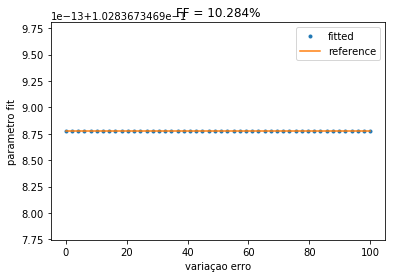

rho_fat = 11.302
rho_water = 88.698
rho_tot = 100.000
OK


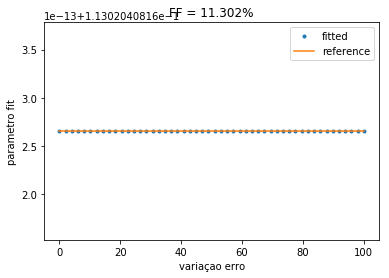

rho_fat = 12.320
rho_water = 87.680
rho_tot = 100.000
OK


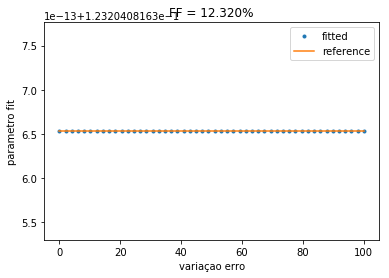

rho_fat = 13.339
rho_water = 86.661
rho_tot = 100.000
OK


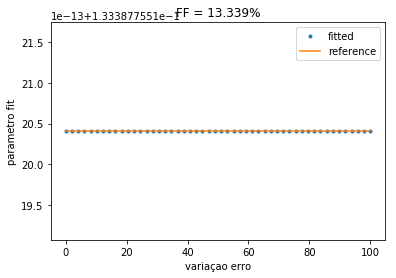

rho_fat = 14.357
rho_water = 85.643
rho_tot = 100.000
OK


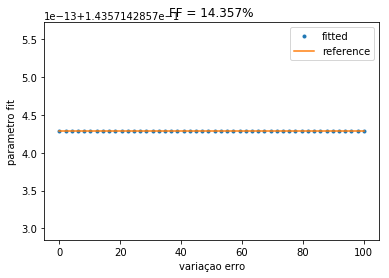

rho_fat = 15.376
rho_water = 84.624
rho_tot = 100.000
OK


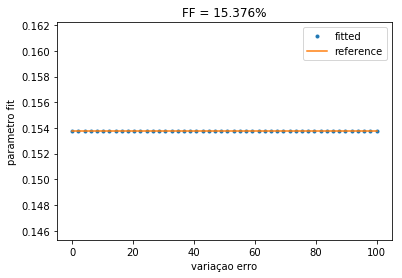

rho_fat = 16.394
rho_water = 83.606
rho_tot = 100.000
OK


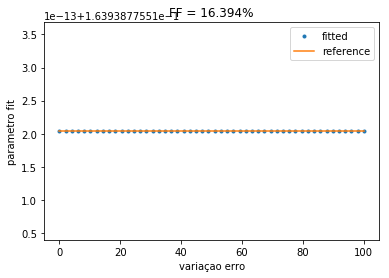

rho_fat = 17.412
rho_water = 82.588
rho_tot = 100.000
OK


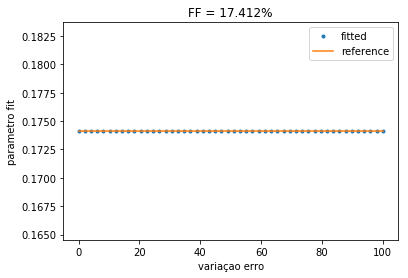

rho_fat = 18.431
rho_water = 81.569
rho_tot = 100.000
OK


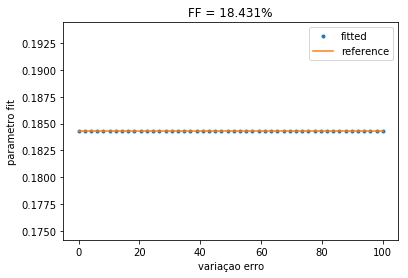

rho_fat = 19.449
rho_water = 80.551
rho_tot = 100.000
OK


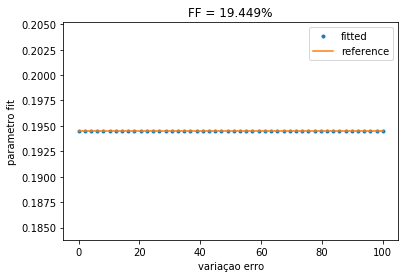

rho_fat = 20.467
rho_water = 79.533
rho_tot = 100.000
OK


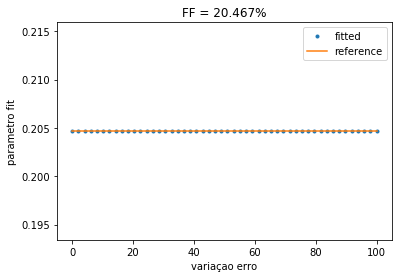

rho_fat = 21.486
rho_water = 78.514
rho_tot = 100.000
OK


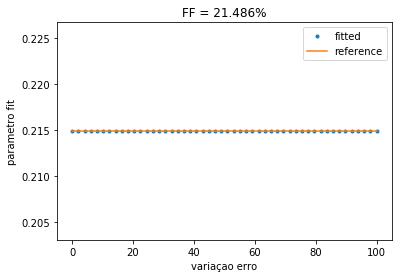

rho_fat = 22.504
rho_water = 77.496
rho_tot = 100.000
OK


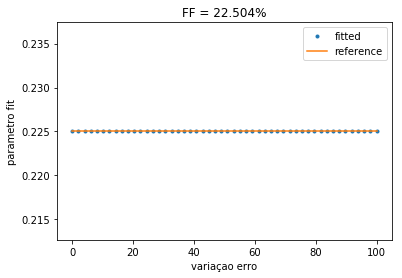

rho_fat = 23.522
rho_water = 76.478
rho_tot = 100.000
OK


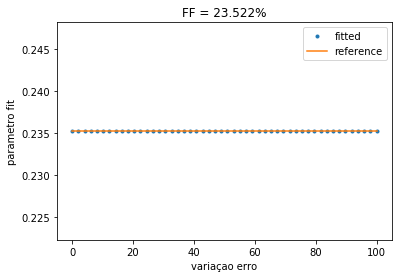

rho_fat = 24.541
rho_water = 75.459
rho_tot = 100.000
OK


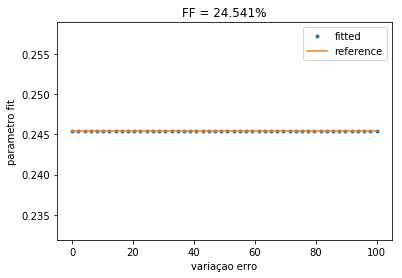

rho_fat = 25.559
rho_water = 74.441
rho_tot = 100.000
OK


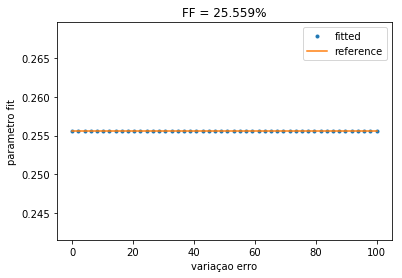

rho_fat = 26.578
rho_water = 73.422
rho_tot = 100.000
OK


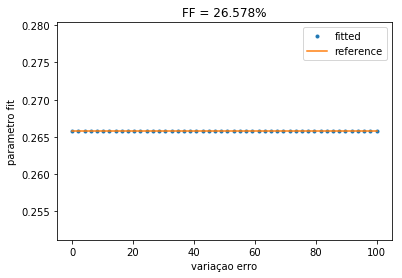

rho_fat = 27.596
rho_water = 72.404
rho_tot = 100.000
OK


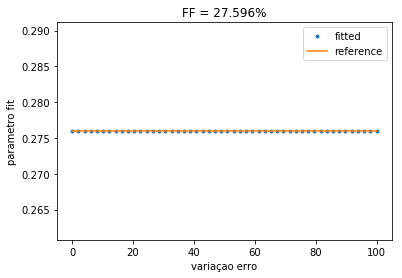

rho_fat = 28.614
rho_water = 71.386
rho_tot = 100.000
OK


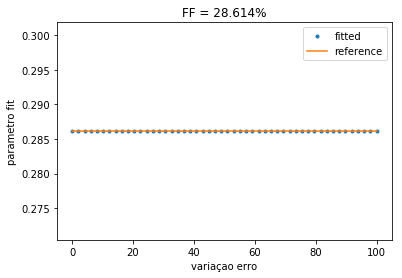

rho_fat = 29.633
rho_water = 70.367
rho_tot = 100.000
OK


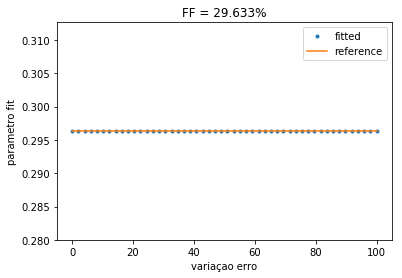

rho_fat = 30.651
rho_water = 69.349
rho_tot = 100.000
OK


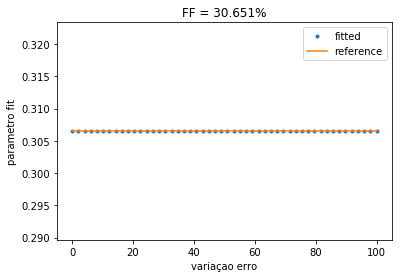

rho_fat = 31.669
rho_water = 68.331
rho_tot = 100.000
OK


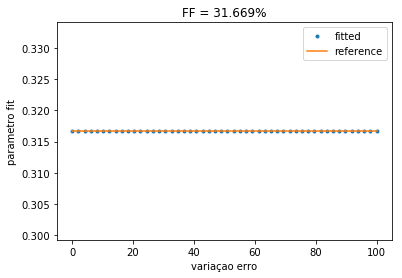

rho_fat = 32.688
rho_water = 67.312
rho_tot = 100.000
OK


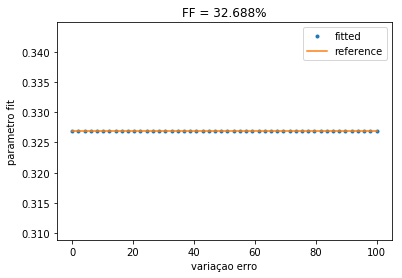

rho_fat = 33.706
rho_water = 66.294
rho_tot = 100.000
OK


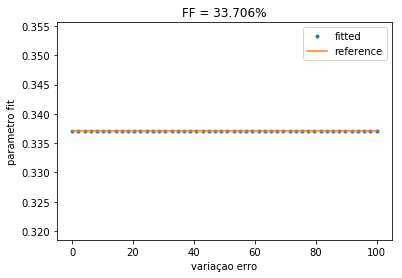

rho_fat = 34.724
rho_water = 65.276
rho_tot = 100.000
OK


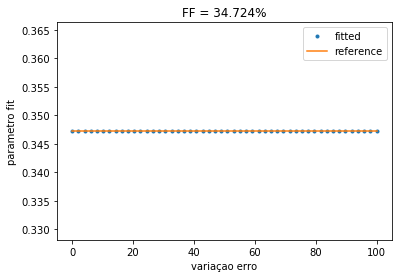

rho_fat = 35.743
rho_water = 64.257
rho_tot = 100.000
OK


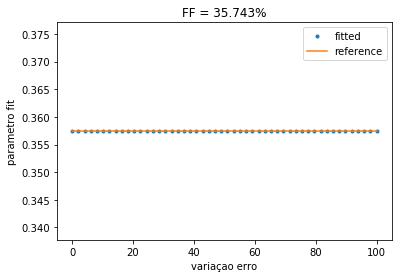

rho_fat = 36.761
rho_water = 63.239
rho_tot = 100.000
OK


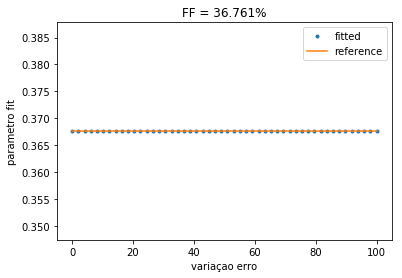

rho_fat = 37.780
rho_water = 62.220
rho_tot = 100.000
OK


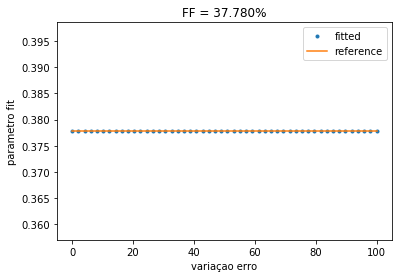

rho_fat = 38.798
rho_water = 61.202
rho_tot = 100.000
OK


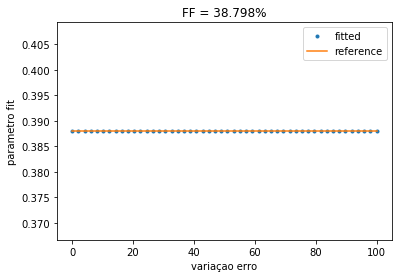

rho_fat = 39.816
rho_water = 60.184
rho_tot = 100.000
OK


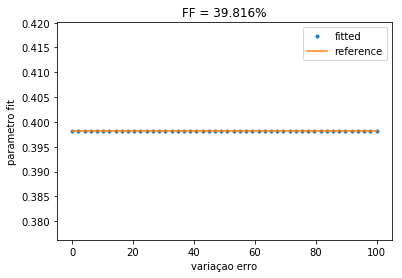

rho_fat = 40.835
rho_water = 59.165
rho_tot = 100.000
OK


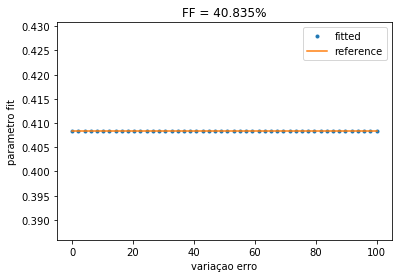

rho_fat = 41.853
rho_water = 58.147
rho_tot = 100.000
OK


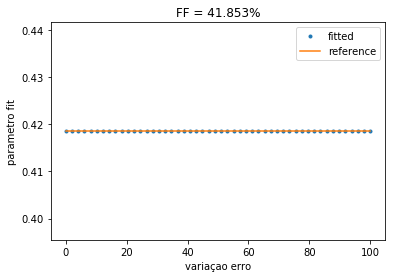

rho_fat = 42.871
rho_water = 57.129
rho_tot = 100.000
OK


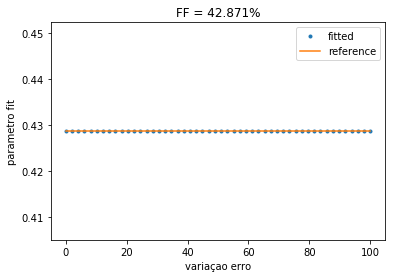

rho_fat = 43.890
rho_water = 56.110
rho_tot = 100.000
OK


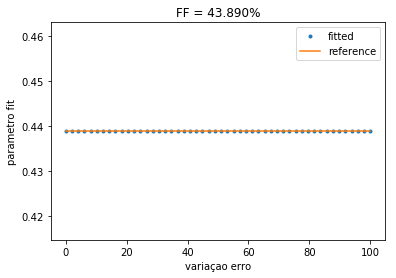

rho_fat = 44.908
rho_water = 55.092
rho_tot = 100.000
OK


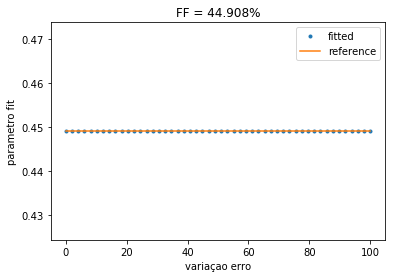

rho_fat = 45.927
rho_water = 54.073
rho_tot = 100.000
OK


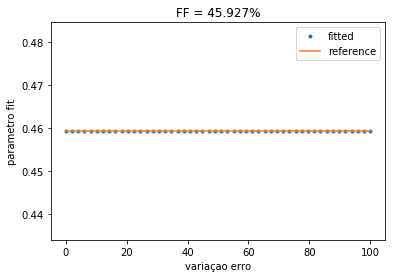

rho_fat = 46.945
rho_water = 53.055
rho_tot = 100.000
OK


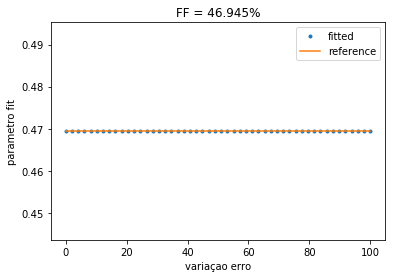

rho_fat = 47.963
rho_water = 52.037
rho_tot = 100.000
OK


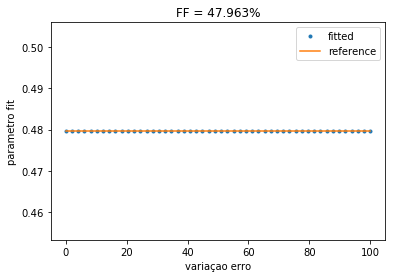

rho_fat = 48.982
rho_water = 51.018
rho_tot = 100.000
OK


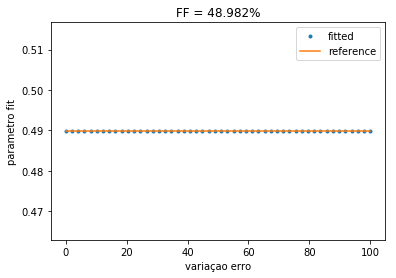

rho_fat = 50.000
rho_water = 50.000
rho_tot = 100.000
OK


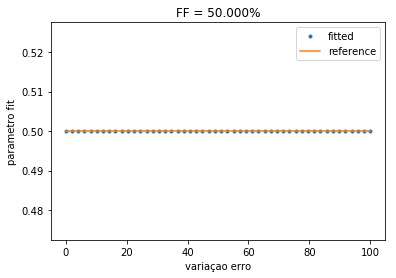

In [13]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 100                # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted100 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water+erro] # (FAT,WATER) + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted100.append(calc_fatfrac(fitted_par))
    
    ref100 = np.zeros(np.size(fitted100))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted100, '.', label='fitted')
    plt.plot(init_guess_var, ref100, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

rho_fat = 1.000
rho_water = 999.000
rho_tot = 1000.000
OK


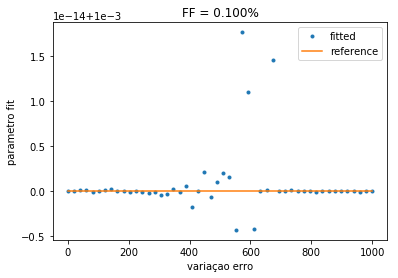

rho_fat = 11.184
rho_water = 988.816
rho_tot = 1000.000
OK


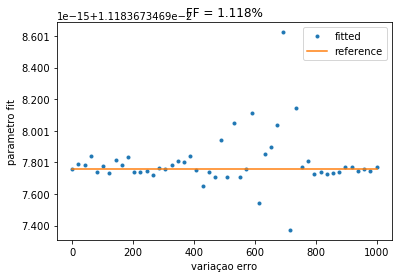

rho_fat = 21.367
rho_water = 978.633
rho_tot = 1000.000
OK


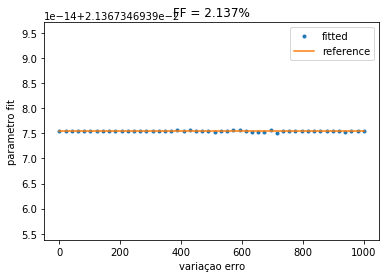

rho_fat = 31.551
rho_water = 968.449
rho_tot = 1000.000
OK


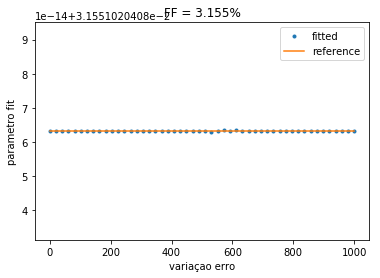

rho_fat = 41.735
rho_water = 958.265
rho_tot = 1000.000
OK


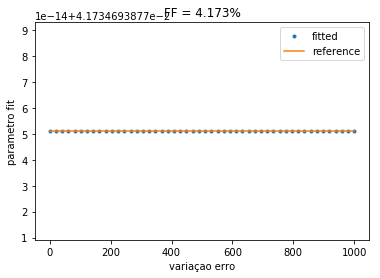

rho_fat = 51.918
rho_water = 948.082
rho_tot = 1000.000
OK


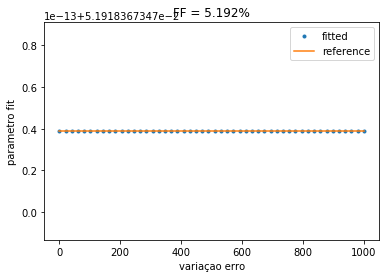

rho_fat = 62.102
rho_water = 937.898
rho_tot = 1000.000
OK


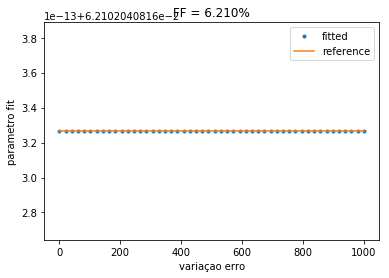

rho_fat = 72.286
rho_water = 927.714
rho_tot = 1000.000
OK


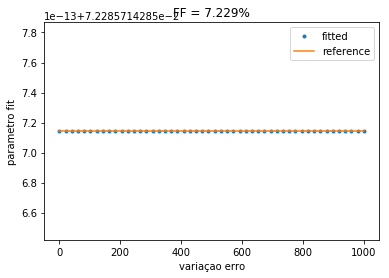

rho_fat = 82.469
rho_water = 917.531
rho_tot = 1000.000
OK


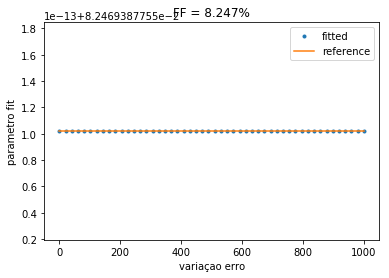

rho_fat = 92.653
rho_water = 907.347
rho_tot = 1000.000
OK


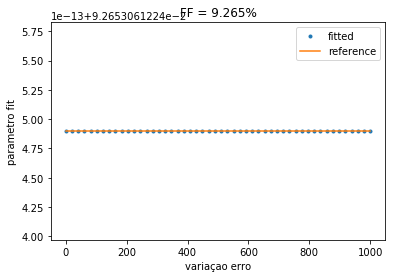

rho_fat = 102.837
rho_water = 897.163
rho_tot = 1000.000
OK


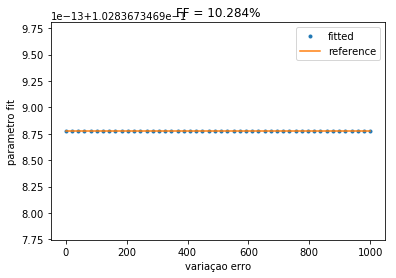

rho_fat = 113.020
rho_water = 886.980
rho_tot = 1000.000
OK


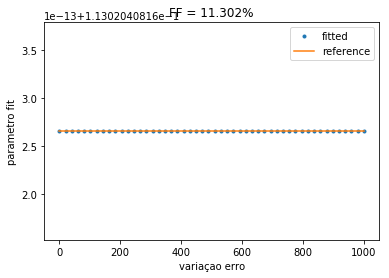

rho_fat = 123.204
rho_water = 876.796
rho_tot = 1000.000
OK


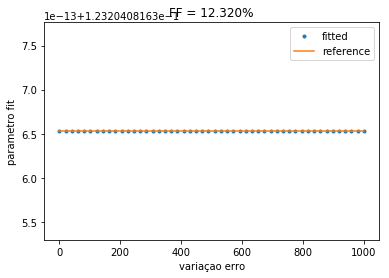

rho_fat = 133.388
rho_water = 866.612
rho_tot = 1000.000
OK


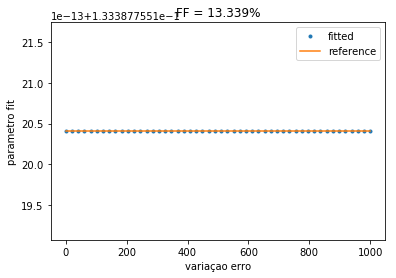

rho_fat = 143.571
rho_water = 856.429
rho_tot = 1000.000
OK


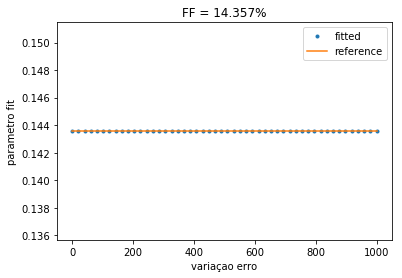

rho_fat = 153.755
rho_water = 846.245
rho_tot = 1000.000
OK


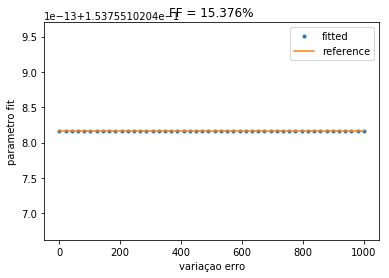

rho_fat = 163.939
rho_water = 836.061
rho_tot = 1000.000
OK


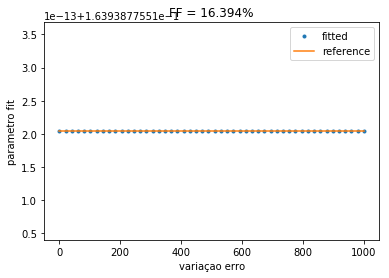

rho_fat = 174.122
rho_water = 825.878
rho_tot = 1000.000
OK


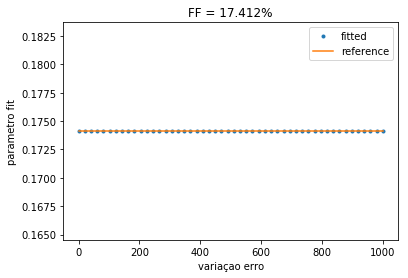

rho_fat = 184.306
rho_water = 815.694
rho_tot = 1000.000
OK


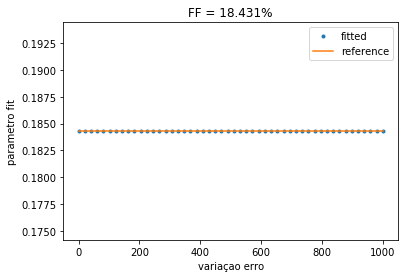

rho_fat = 194.490
rho_water = 805.510
rho_tot = 1000.000
OK


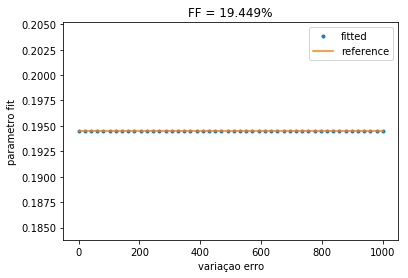

rho_fat = 204.673
rho_water = 795.327
rho_tot = 1000.000
OK


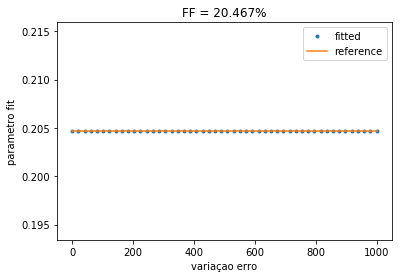

rho_fat = 214.857
rho_water = 785.143
rho_tot = 1000.000
OK


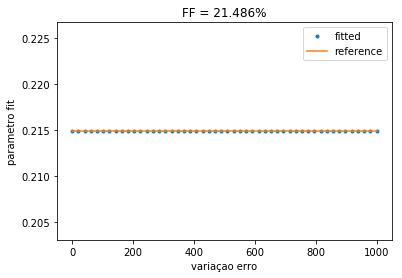

rho_fat = 225.041
rho_water = 774.959
rho_tot = 1000.000
OK


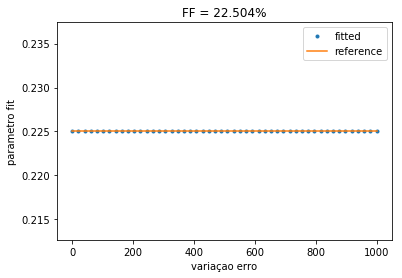

rho_fat = 235.224
rho_water = 764.776
rho_tot = 1000.000
OK


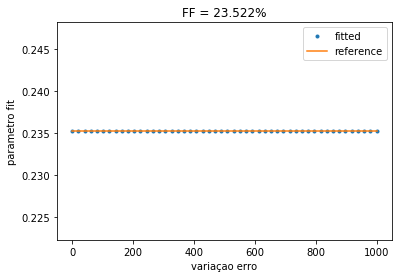

rho_fat = 245.408
rho_water = 754.592
rho_tot = 1000.000
OK


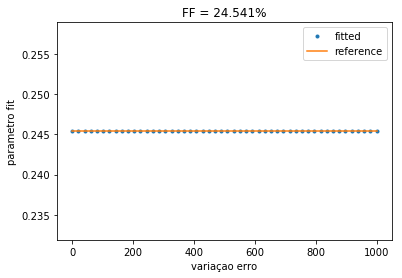

rho_fat = 255.592
rho_water = 744.408
rho_tot = 1000.000
OK


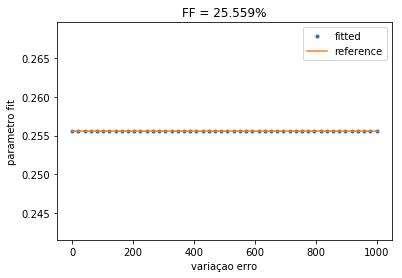

rho_fat = 265.776
rho_water = 734.224
rho_tot = 1000.000
OK


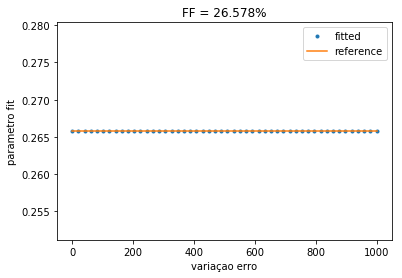

rho_fat = 275.959
rho_water = 724.041
rho_tot = 1000.000
OK


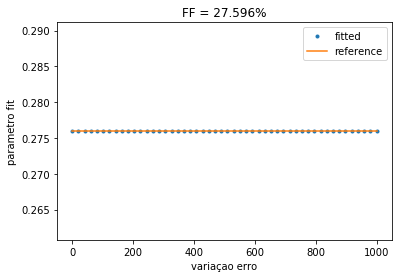

rho_fat = 286.143
rho_water = 713.857
rho_tot = 1000.000
OK


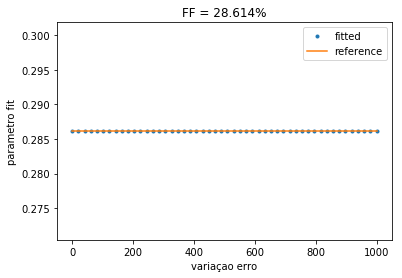

rho_fat = 296.327
rho_water = 703.673
rho_tot = 1000.000
OK


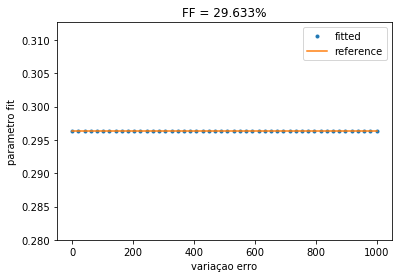

rho_fat = 306.510
rho_water = 693.490
rho_tot = 1000.000
OK


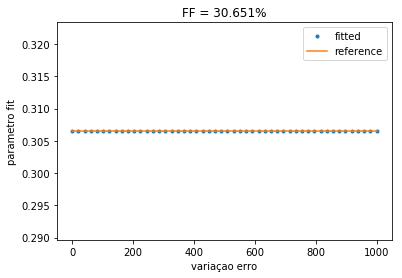

rho_fat = 316.694
rho_water = 683.306
rho_tot = 1000.000
OK


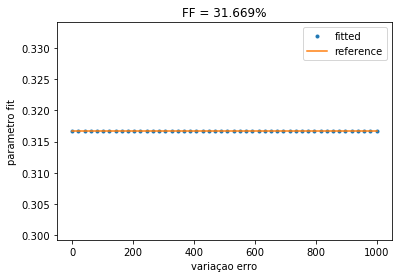

rho_fat = 326.878
rho_water = 673.122
rho_tot = 1000.000
OK


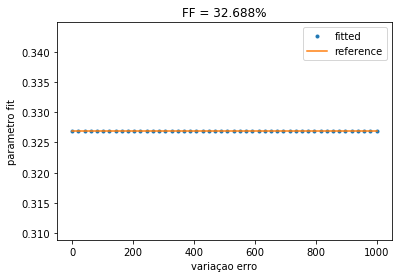

rho_fat = 337.061
rho_water = 662.939
rho_tot = 1000.000
OK


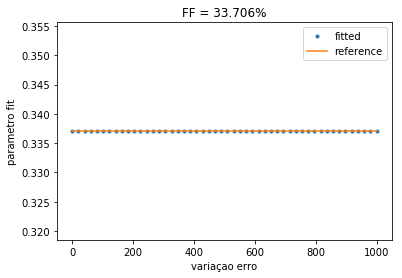

rho_fat = 347.245
rho_water = 652.755
rho_tot = 1000.000
OK


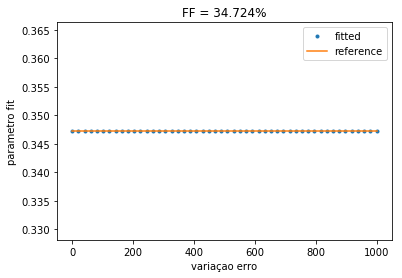

rho_fat = 357.429
rho_water = 642.571
rho_tot = 1000.000
OK


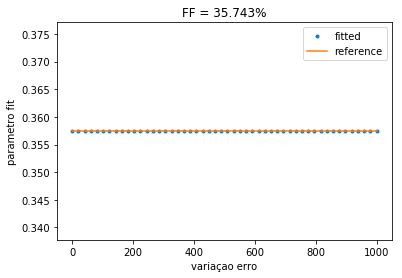

rho_fat = 367.612
rho_water = 632.388
rho_tot = 1000.000
OK


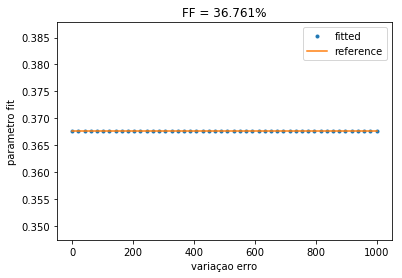

rho_fat = 377.796
rho_water = 622.204
rho_tot = 1000.000
OK


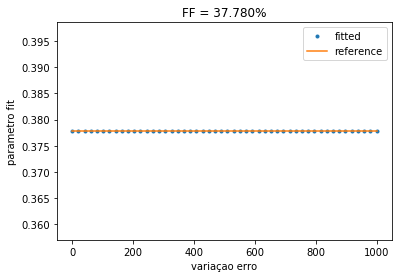

rho_fat = 387.980
rho_water = 612.020
rho_tot = 1000.000
OK


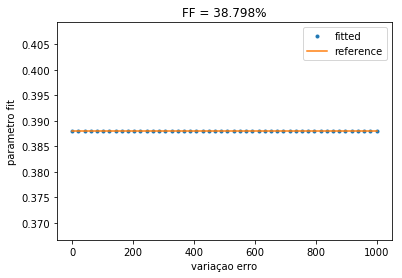

rho_fat = 398.163
rho_water = 601.837
rho_tot = 1000.000
OK


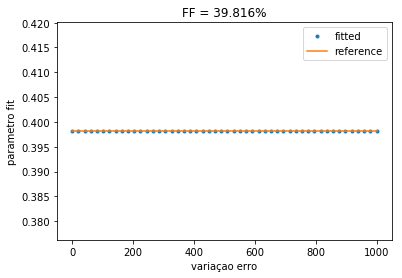

rho_fat = 408.347
rho_water = 591.653
rho_tot = 1000.000
OK


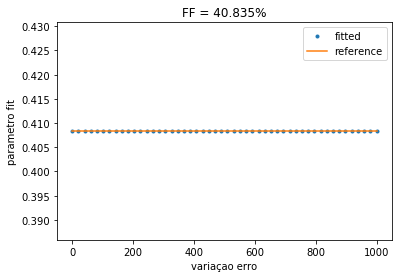

rho_fat = 418.531
rho_water = 581.469
rho_tot = 1000.000
OK


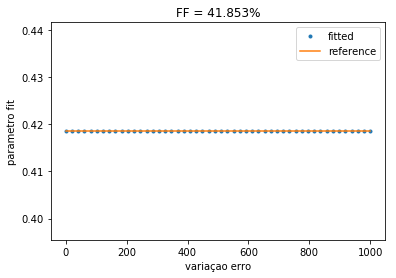

rho_fat = 428.714
rho_water = 571.286
rho_tot = 1000.000
OK


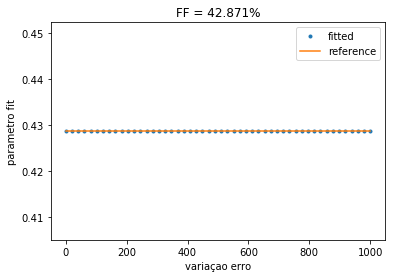

rho_fat = 438.898
rho_water = 561.102
rho_tot = 1000.000
OK


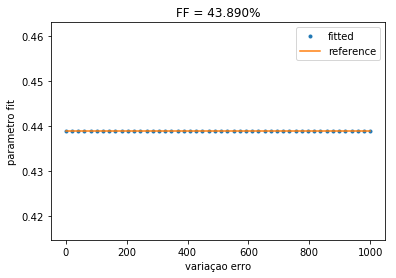

rho_fat = 449.082
rho_water = 550.918
rho_tot = 1000.000
OK


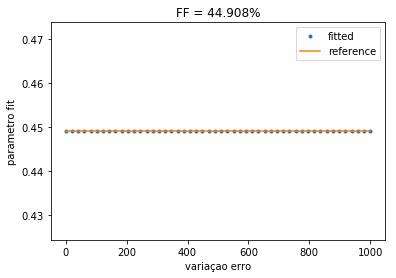

rho_fat = 459.265
rho_water = 540.735
rho_tot = 1000.000
OK


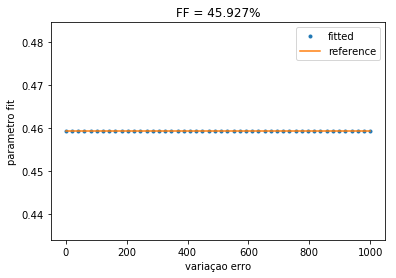

rho_fat = 469.449
rho_water = 530.551
rho_tot = 1000.000
OK


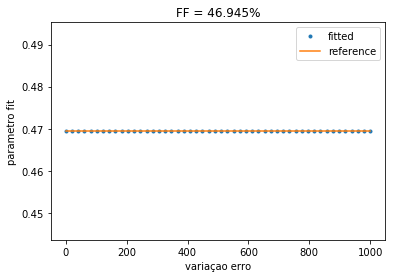

rho_fat = 479.633
rho_water = 520.367
rho_tot = 1000.000
OK


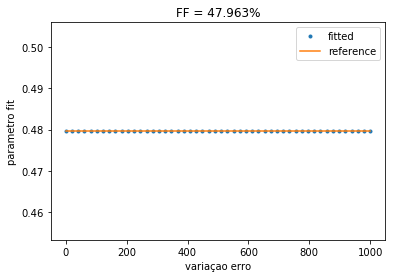

rho_fat = 489.816
rho_water = 510.184
rho_tot = 1000.000
OK


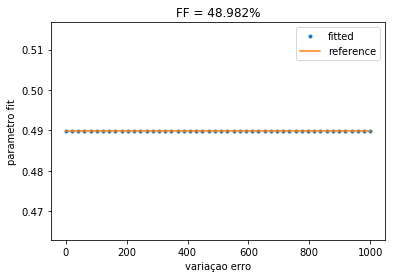

rho_fat = 500.000
rho_water = 500.000
rho_tot = 1000.000
OK


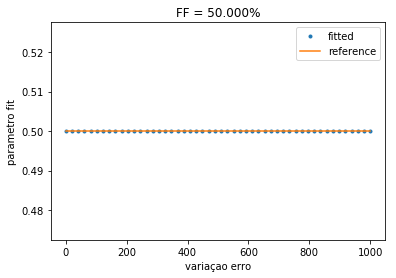

In [14]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.001, 0.5) # fat fraction
rho_tot = 1000               # rho_water + rho_fat
init_guess_var = np.linspace(0, rho_tot) # erro para valores iniciais

for fat in ff:
    fitted1000 = []
    rho_fat, rho_water = set_rho(fat, rho_tot)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water+erro] # (FAT,WATER) + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1000.append(calc_fatfrac(fitted_par))
    
    ref1000 = np.zeros(np.size(fitted1000))+fat # original FF
    
    print('rho_fat = %.3f' % rho_fat)
    print('rho_water = %.3f' % rho_water)
    tot = rho_water+rho_fat
    print('rho_tot = %.3f' % tot)
    if(rho_tot == tot): print('OK')
    else: 
        dif = rho_tot-tot
        print('rho_tot - tot = %.3f' % dif)
    
    plt.figure()
    plt.plot(init_guess_var, fitted1000, '.', label='fitted')
    plt.plot(init_guess_var, ref1000, label='reference')
    
    i = fat*100
    plt.title('FF = %.3f%%' % i)
    plt.xlabel('variaçao erro')
    plt.ylabel('parametro fit')
    plt.legend()
    plt.show()

# Juntar os 3 rho_tot em graf ?

# Juntando tudo?

In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)  # fat fraction
init_guess_var = np.linspace(-20,20)  # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(init_guess_var), np.size(ff)))

plt.figure(1)
plt.xlabel('init_guess_var')
plt.ylabel('fitted')
for i in range(int(np.size(fitted1[0])/2)):
    plt.title('0-50%')
    plt.plot(init_guess_var, fitted1[i,:])
plt.savefig('fitted_init_guess_var.png')
plt.show()

print(ff[45])
print(fitted1[45])

# testes a revisar

In [ ]:
# preamble
from mpl_toolkits.mplot3d.axes3d import Axes3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
cs = ['r','g','b','y','r','g','b','y','r','g','b','y']

fat_fract = list(np.linspace(0.01,0.50))
for ff in fat_fract:    
    x = continuous_timeseries()

    fitted_parameter3 = []

    erro = list(np.linspace(-20,20))

    for n in erro:
        rho_fat, rho_water = set_rho(ff)
        xdata = discrete_timeseries(7)
        ydata = gen_GRE(xdata, rho_fat, rho_water)

        p0 = [rho_fat + n, rho_water + n]
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) # valores iniciais + random em 0.01
        fitted_parameter3.append(fitted_par)

    fitted3 = np.array([calc_fatfrac(x) for x in fitted_parameter3])
    
    # x axis
    X = erro

    # y axis
    Y = np.zeros(50)+ff

    # data - plotted against z axis
    Z = ff-fitted3

    # populate figure
    ax.plot(X, np.array(Y), Z)

ax.set_xlabel('Erro inserido')
ax.set_ylabel('FF real')
ax.set_zlabel('Erro na estimacao')
    # set initial view of plot
ax.view_init(elev=40., azim=345.)
plt.show()    


In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
init_guess_var = np.linspace(-20,20)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(init_guess_var), np.size(ff)))

plt.figure(1)
plt.xlabel('init_guess_var')
plt.ylabel('fitted init_guess_var')
for i in range(int(np.size(fitted1[0])/2)):
    plt.title('0-50%')
    plt.plot(init_guess_var, ff[i]-fitted1[i,:])
plt.show()

In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
init_guess_var = np.linspace(-20,20)    # erro para valores iniciais
fitted1 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted1.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted1 = np.reshape(np.array(fitted1), (np.size(init_guess_var), np.size(ff)))

print(fitted1)

plt.xlabel('init_guess_var')
plt.ylabel('fitted')

for i in range(np.size(fitted1[0])):
    plt.plot(init_guess_var, ff-fitted1[i,:])


In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
init_guess_var = np.linspace(-1,0)    # erro para valores iniciais
fitted_0 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_0.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_0 = np.reshape(np.array(fitted_0), (np.size(init_guess_var), np.size(ff)))

plt.xlabel('fitted')
plt.ylabel('init_guess_var')
for i in range(np.size(fitted_0[0])):
    plt.plot(fitted_0[i,:],init_guess_var)

In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
init_guess_var = np.linspace(0,1)    # erro para valores iniciais
fitted_01 = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_01.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_01 = np.reshape(np.array(fitted_01), (np.size(init_guess_var), np.size(ff)))

plt.xlabel('fitted')
plt.ylabel('init_guess_var')
for i in range(np.size(fitted_01[0])):
    plt.plot(fitted_01[i,:],init_guess_var)

In [ ]:
x = continuous_timeseries()  # plotar função contínua
ff = np.linspace(0.01,0.50)   # fat fraction
init_guess_var = np.zeros(50)    # erro para valores iniciais
fitted_zeros = []                 # lista com parametros encontrados no fit
        
for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    for erro in init_guess_var:
        p0 = [rho_fat+erro, rho_water] # FAT + init_guess_var
        fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) 
        fitted_zeros.append(calc_fatfrac(fitted_par))

# Cada linha do fitted1 é o parâmetro encontrado no curve_fit, cada coluna é um valor de erro
fitted_zeros = np.reshape(np.array(fitted_zeros), (np.size(init_guess_var), np.size(ff)))

plt.xlabel('ff')
plt.ylabel('fitted')
for i in range(np.size(fitted_zeros[0])):
    plt.plot(ff, fitted_zeros[i,:])